In [1]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns
from scipy.stats import gaussian_kde, wasserstein_distance, ks_2samp, pearsonr, spearmanr
import glob
import os
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import AutoMinorLocator
from sklearn.manifold import trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
import umap
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
import os
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import matplotlib.colors as mcolors


In [2]:
from picosvg.svg import SVG

def save_flat_svg(fig, path, dpi=500):
    fig.savefig(path, dpi=dpi)
    svg = SVG.parse(path).topicosvg()
    with open(path, "w") as f:
        f.write(svg.tostring())

In [3]:
plt.rcParams.update({
    "font.size": 18,
    "axes.labelsize": 17,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
})

# Figure Panel #2

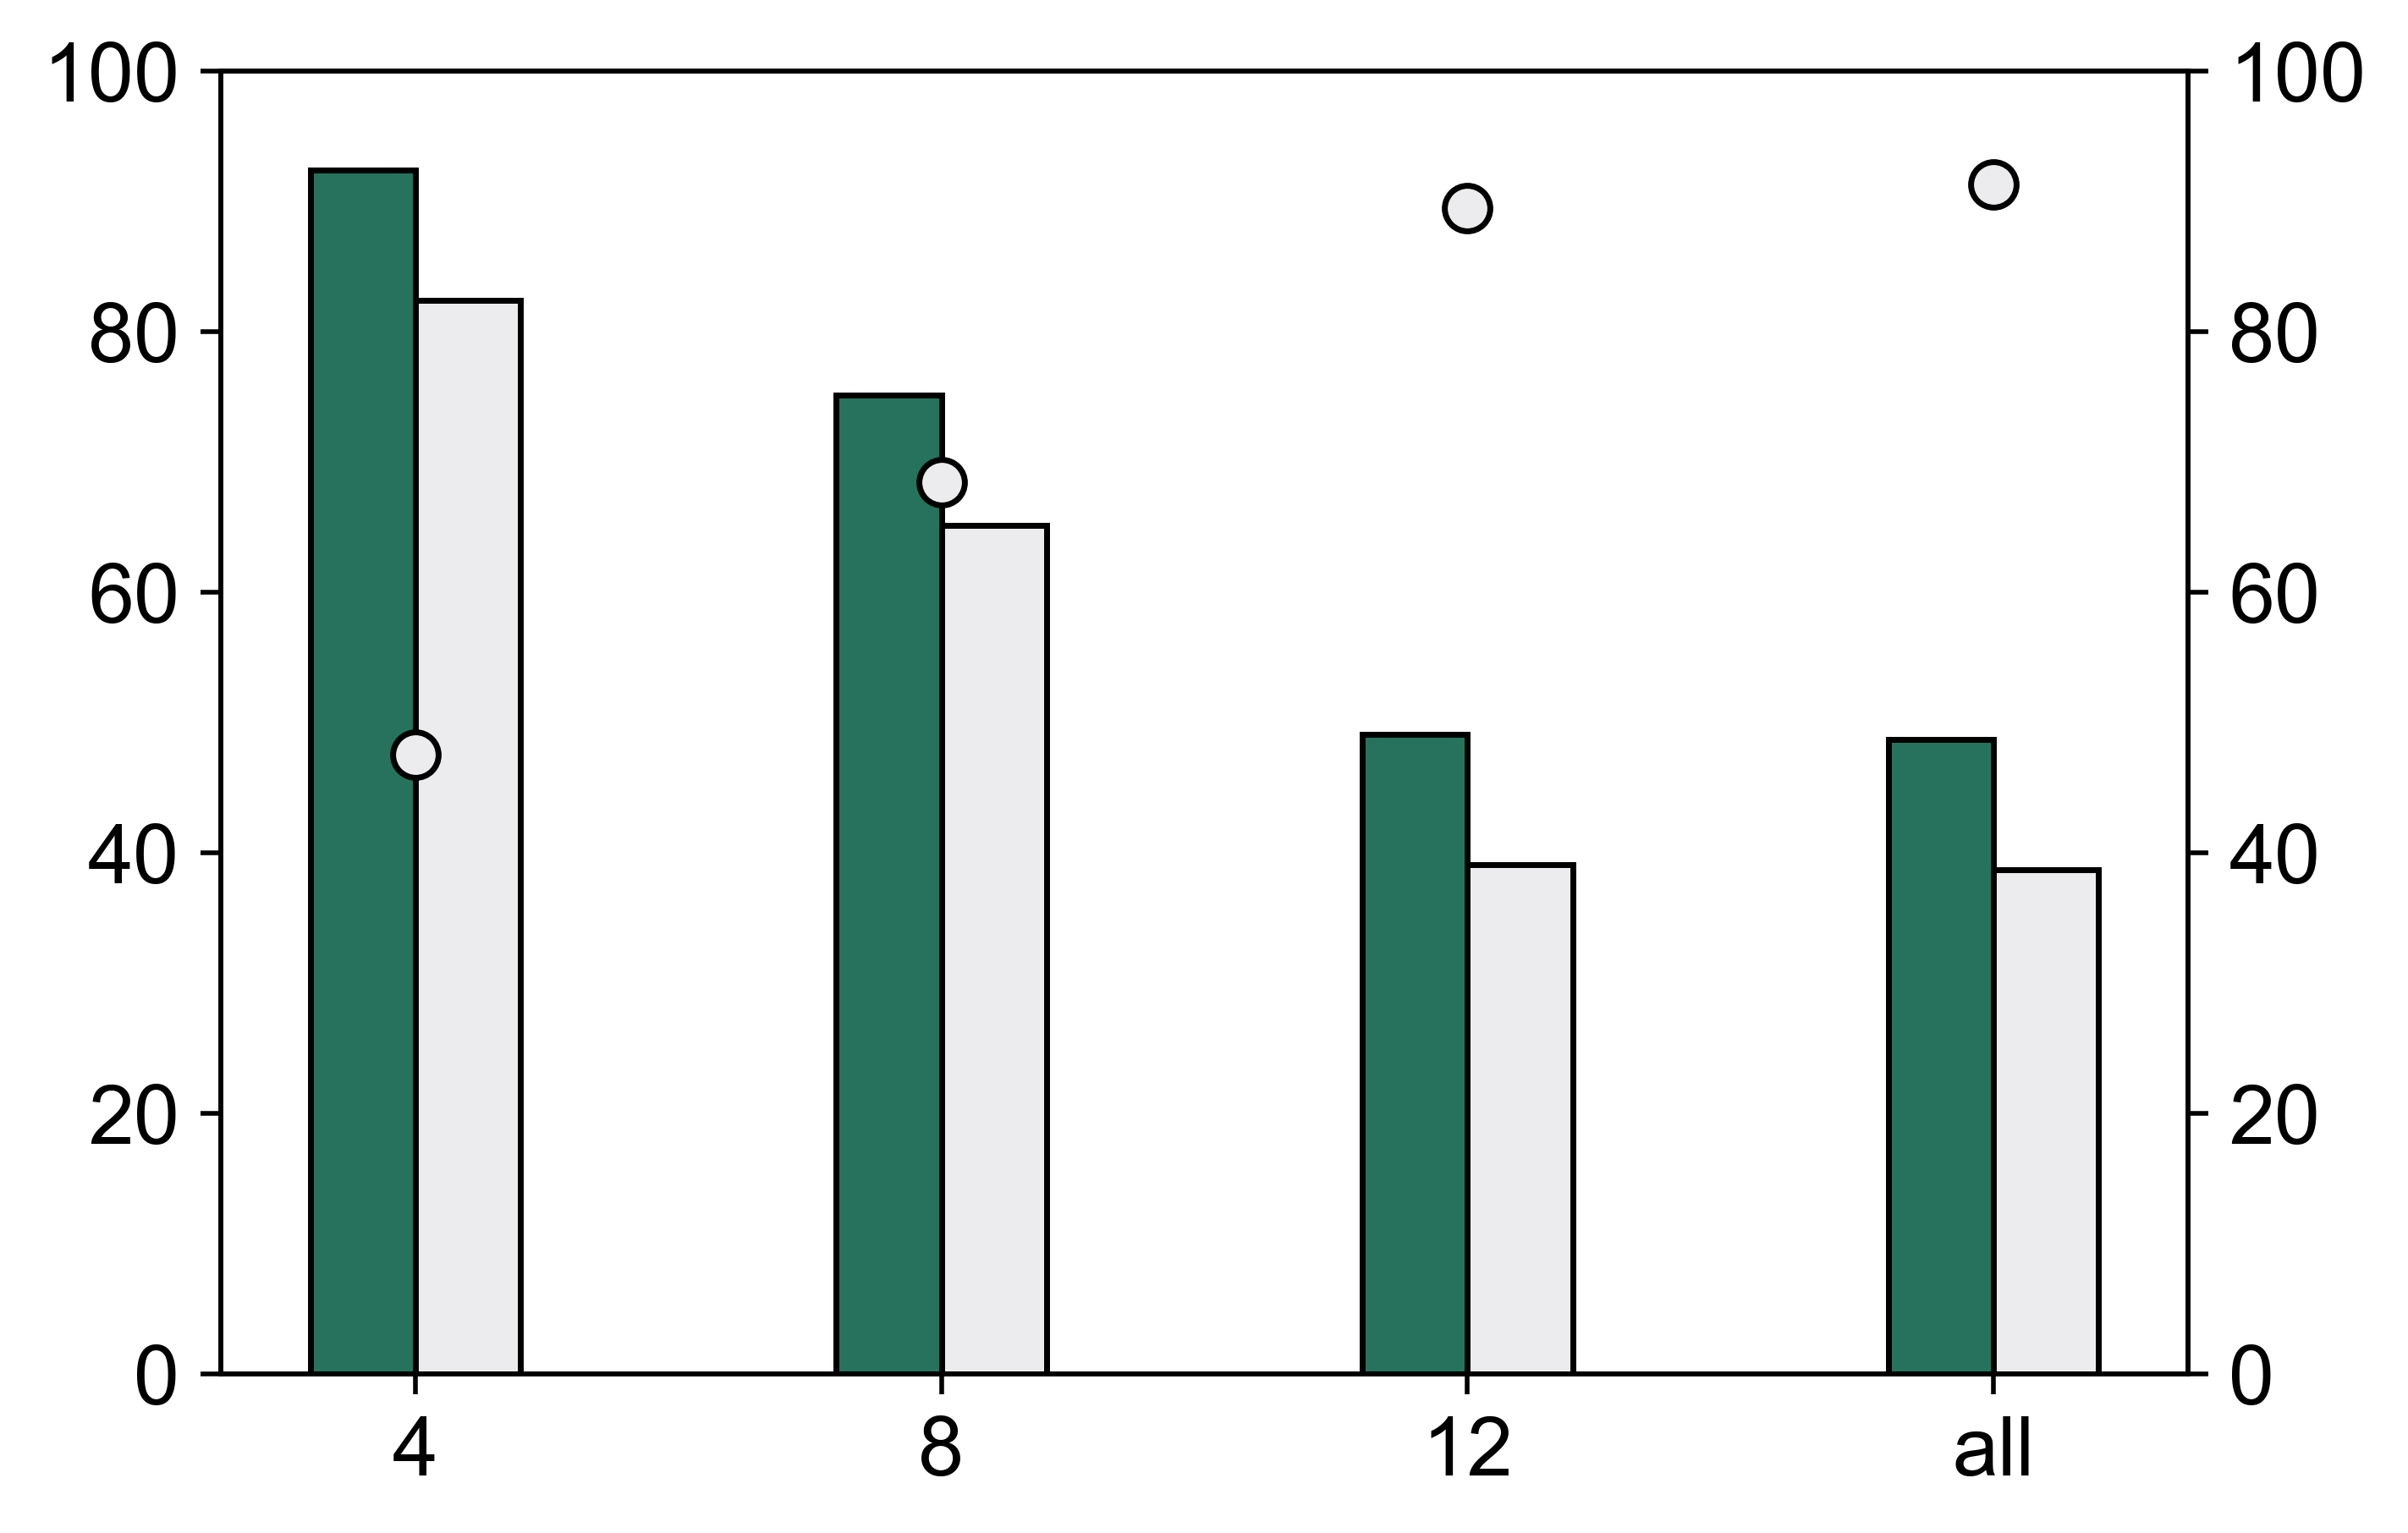

In [4]:
plt.rcParams['font.family'] = 'Arial'

categories = ["4", "8", "12", "all"]

# Dummy values for ID/OOD; "all" ID is the real value from Table 3
id_values = np.array([92.44, 75.15, 49.13, 48.73])   # TODO: replace 4/8/12 with real numbers
ood_values = id_values - 10   # TODO: replace with real numbers

# Dummy uniqueness values (one point per category)
uniqueness_values = np.array([47.57, 68.47, 89.50, 91.32])   # TODO: replace with real numbers

x = np.arange(len(categories))
width = 0.2

fig, ax1 = plt.subplots(figsize=(6, 4), dpi=500)

bars_id = ax1.bar(x - width/2, id_values, width, label="ID", color="#27725D", edgecolor='black' )
bars_ood = ax1.bar(x + width/2, ood_values, width, label="OOD", color="#ECECEE", edgecolor='black' )

ax1.tick_params(axis='both', labelsize=14)

ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, 100)

ax2 = ax1.twinx()
ax2.tick_params(axis='both', labelsize=14)
points_uniqueness = ax2.scatter(x, uniqueness_values, color="#ECECEE", marker="o", edgecolors='black',
                                 s=60, zorder=3, label="Uniqueness")
ax2.set_ylim(0, 100)

# Combine legends from both axes
handles = [bars_id, bars_ood, points_uniqueness]
labels = [h.get_label() for h in handles]

[94.86333333 84.90333333 65.71       58.68333333] [0.02054805 0.08576454 0.15513435 0.21853045] [93.82 83.41 65.06 57.23] [0. 0. 0. 0.]
[42.58333333 59.99       79.56666667 89.15333333] [0.21684608 0.83693887 0.13274872 0.03858612] [43.17 60.74 79.16 89.29]


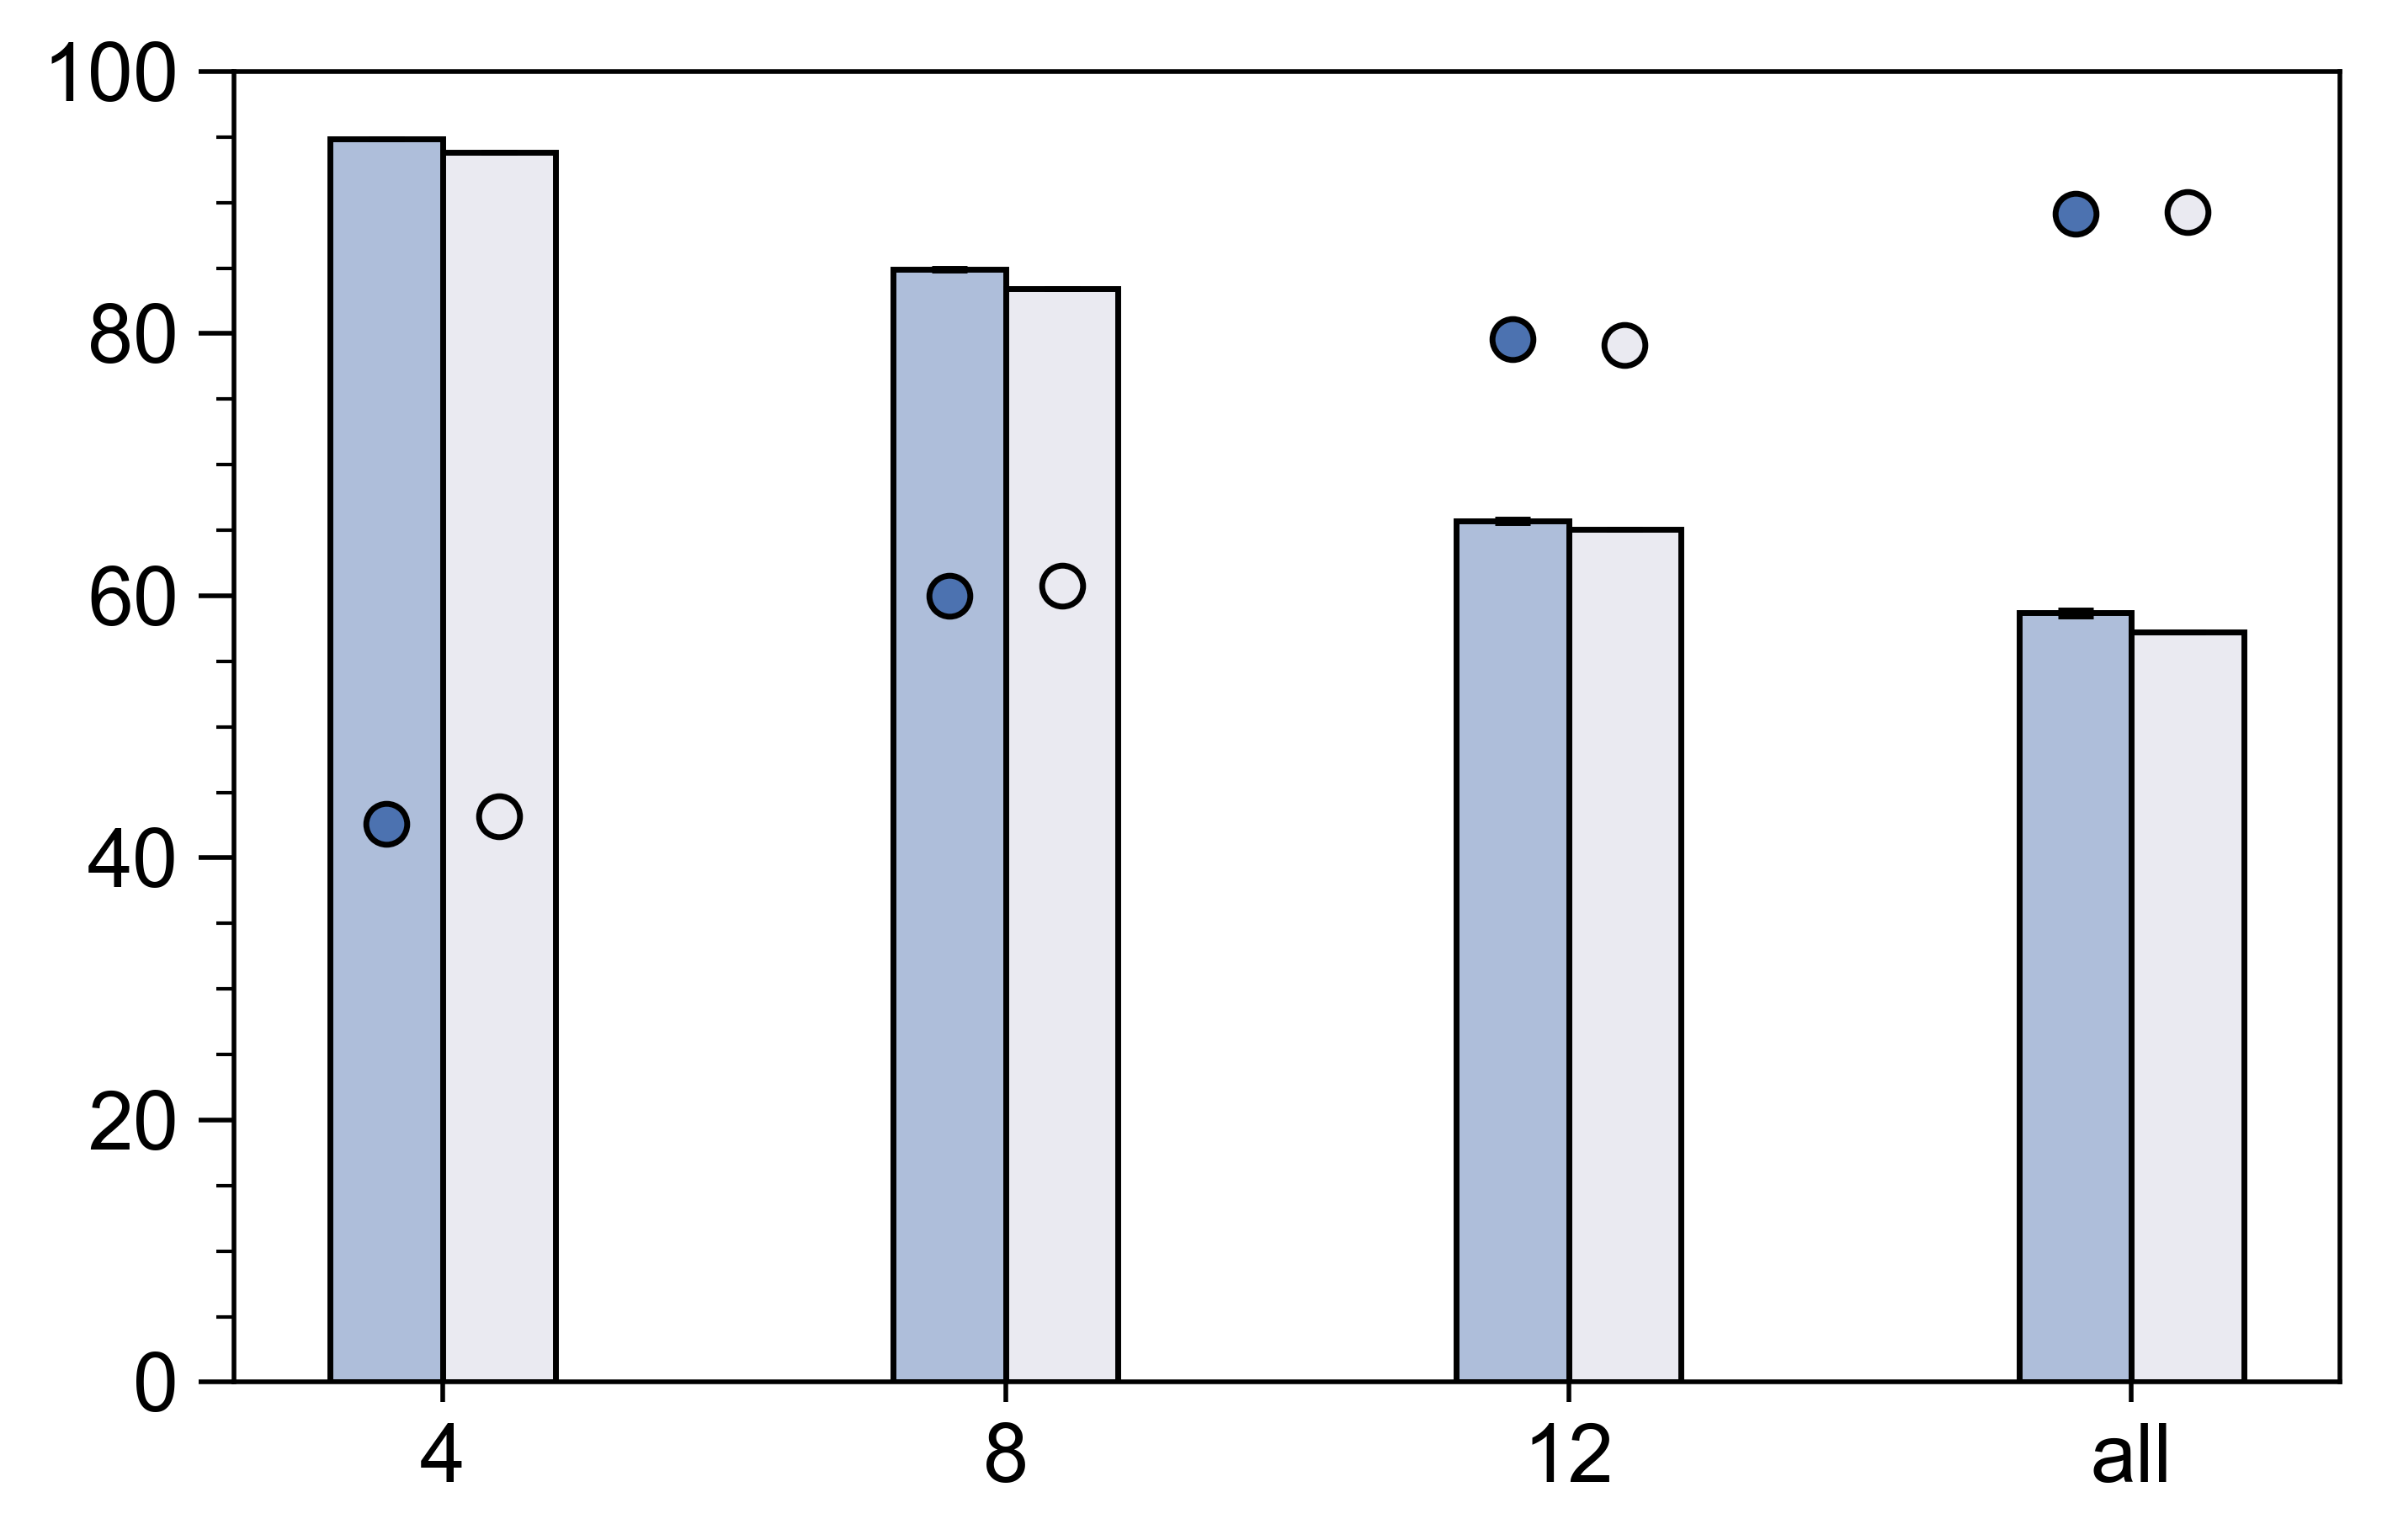

In [5]:
"""
Compare elemental composition diversity between GACE (across seeds) and OC20,
via a back-to-back horizontal bar chart plus Shannon entropy summary stats.

Setup:
  - Sets global matplotlib font sizes (title/axis/tick/legend) for the figure.
  - TOP_N = 20 controls how many elements are shown in the plot.

`load_percent(path)`:
  Reads a CSV, normalizes column names (strip + lowercase), locates the
  "element" and "count" columns, and returns a pandas Series mapping
  element -> percent of total count (values sum to 100).

`shannon_entropy(pct_series)`:
  Computes Shannon entropy in nats from a Series of percentages (converts
  to probabilities, drops zeros, returns -sum(p * log(p))).

Main flow:
  1. Loads elemental composition percentages for three GACE seeds
     (0, 7, 42) and for OC20 from CSV files in "./data/".
  2. Builds the union of all elements seen across the three GACE seeds and
     OC20, and reindexes every series onto that common element set,
     filling missing elements with 0.0.
  3. Stacks the three GACE seed series and computes, per element, the mean
     (`gace`) and std (`gace_err`) across seeds.
  4. Computes and prints Shannon entropy (and "effective diversity" =
     exp(entropy), i.e. the effective number of equally-likely elements)
     for both OC20 and the seed-averaged GACE distribution.
  5. Ranks elements by combined (GACE + OC20) percentage, takes the top
     TOP_N, and reverses the order so the largest ends up at the top of
     the plot.
  6. Plots a horizontal "tornado" / back-to-back bar chart: GACE
     percentages extend right (with seed-std error bars), OC20 percentages
     extend left (plotted as negative values), sharing a common y-axis of
     element labels. X-tick labels are converted to their absolute value
     so both sides read as positive percentages.
  7. Draws a vertical line at x=0, tightens layout, and saves the figure
     as an SVG via `save_flat_svg`.

Note: this saves to the same path as the previous panel
("fig2/panel/val_uniq_gaussian.svg") — looks like a copy-pasted filename
that wasn't updated, so it will silently overwrite that earlier figure.
"""

categories = ["4", "8", "12", "all"]

# Validity across different seeds
id_values_0 = np.array([94.89, 84.80, 65.50, 58.61])
ood_values_0 = np.array([93.82, 83.41, 65.06, 57.23])

id_values_7 = np.array([94.84, 84.90, 65.76, 58.98])
ood_values_7 = np.array([93.82, 83.41, 65.06, 57.23])

id_values_42 = np.array([94.86, 85.01, 65.87, 58.46])
ood_values_42 = np.array([93.82, 83.41, 65.06, 57.23])

# Uniqueness across different seeds
id_uniqueness_0 = np.array([42.89, 60.66, 79.71, 89.10])
ood_uniqueness_0 = np.array([43.17, 60.74, 79.16, 89.29])

id_uniqueness_7 = np.array([42.43, 60.50, 79.60, 89.19])
ood_uniqueness_7 = np.array([43.17, 60.74, 79.16, 89.29])

id_uniqueness_42 = np.array([42.43, 58.81, 79.39, 89.17])
ood_uniqueness_42 = np.array([43.17, 60.74, 79.16, 89.29])

# Stack across seeds -> shape (3, len(categories))
id_values_all = np.stack([id_values_0, id_values_7, id_values_42])
ood_values_all = np.stack([ood_values_0, ood_values_7, ood_values_42])
id_uniqueness_all = np.stack([id_uniqueness_0, id_uniqueness_7, id_uniqueness_42])
ood_uniqueness_all = np.stack([ood_uniqueness_0, ood_uniqueness_7, ood_uniqueness_42])

# Mean and std (ddof=0; use ddof=1 if you want sample std)
id_values, id_values_err = id_values_all.mean(axis=0), id_values_all.std(axis=0)
ood_values, ood_values_err = ood_values_all.mean(axis=0), ood_values_all.std(axis=0)
id_uniqueness, id_uniqueness_err = id_uniqueness_all.mean(axis=0), id_uniqueness_all.std(axis=0)
ood_uniqueness, ood_uniqueness_err = ood_uniqueness_all.mean(axis=0), ood_uniqueness_all.std(axis=0)

print(id_values, id_values_err, ood_values, ood_values_err)
print(id_uniqueness, id_uniqueness_err , ood_uniqueness)

x = np.arange(len(categories))
width = 0.2

fig_b, ax1 = plt.subplots(figsize=(6, 4), dpi=500)

bars_id = ax1.bar(x - width/2, id_values, width, yerr=id_values_err, capsize=3,
                   error_kw=dict(elinewidth=1, capthick=1),
                   label="ID", color="#AEBEDA", edgecolor='black')
bars_ood = ax1.bar(x + width/2, ood_values, width, yerr=ood_values_err, capsize=3,
                    error_kw=dict(elinewidth=1, capthick=1),
                    label="OOD", color="#EAEAF1", edgecolor='black')

ax1.set_xticks(x)
ax1.set_xticklabels(categories)
ax1.set_ylim(0, 100)
ax1.tick_params(axis='both', labelsize=14)

# Minor ticks on the (only) y-axis
ax1.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax1.tick_params(axis='y', which='minor', length=3)
ax1.tick_params(axis='y', which='major', length=6)

# Uniqueness points aligned to the center of each corresponding bar
points_id_uniq = ax1.errorbar(x - width/2, id_uniqueness, yerr=id_uniqueness_err,
                               fmt='o', color="#4C72B0", markeredgecolor='black',
                               ecolor='black', elinewidth=1, capsize=3,
                               markersize=7, zorder=3, label="ID Uniqueness")
points_ood_uniq = ax1.errorbar(x + width/2, ood_uniqueness, yerr=ood_uniqueness_err,
                                fmt='o', color="#EAEAF1", markeredgecolor='black',
                                ecolor='black', elinewidth=1, capsize=3,
                                markersize=7, zorder=3, label="OOD Uniqueness")

# Combine legends
handles = [bars_id, bars_ood, points_id_uniq, points_ood_uniq]
labels = [h.get_label() for h in handles]

plt.tight_layout()
save_flat_svg(fig=fig_b, path="fig2/panel/val_uniq_gaussian.svg")
plt.show()

In [6]:
"""
Compare elemental composition diversity between GACE (across seeds) and OC20,
via Shannon entropy and Jensen-Shannon divergence summary stats.

`load_percent(path)`:
  Reads a CSV, normalizes column names (strip + lowercase), locates the
  "element" and "count" columns, and returns a pandas Series mapping
  element -> percent of total count (values sum to 100).

`shannon_entropy(pct_series)`:
  Computes Shannon entropy in nats from a Series of percentages (converts
  to probabilities, drops zeros, returns -sum(p * log(p))).

`js_divergence(p_pct, q_pct)`:
  Computes Jensen-Shannon divergence in nats between two Series of
  percentages (converts each to a probability vector over the same
  element index).

Main flow:
  1. Loads elemental composition percentages for three GACE seeds
     (0, 7, 42) and for OC20 from CSV files in "./data/".
  2. Builds the union of all elements seen across the three GACE seeds and
     OC20, and reindexes every series onto that common element set,
     filling missing elements with 0.0.
  3. Stacks the three GACE seed series and computes, per element, the mean
     (`gace`) across seeds.
  4. Computes and prints Shannon entropy (and "effective diversity" =
     exp(entropy), i.e. the effective number of equally-likely elements)
     for both OC20 and the seed-averaged GACE distribution.
  5. Computes and prints the Jensen-Shannon divergence between the OC20
     and seed-averaged GACE compositional distributions.
  6. Prints the largest per-element percentage-point differences between
     GACE and OC20.
"""

import numpy as np
import pandas as pd
from scipy.spatial.distance import jensenshannon


def load_percent(path):
    df = pd.read_csv(path)
    df.columns = [str(c).strip().lower() for c in df.columns]
    elem_col = next(c for c in df.columns if c == "element")
    count_col = next(c for c in df.columns if c == "count")
    s = df.set_index(elem_col)[count_col].astype(float)
    return s / s.sum() * 100.0


def shannon_entropy(pct_series):
    """Shannon entropy (nats) from a pandas Series of percentages."""
    p = pct_series.values / 100.0
    p = p[p > 0]
    return -np.sum(p * np.log(p))


def js_divergence(p_pct, q_pct):
    """Jensen-Shannon divergence (nats) between two percentage Series
    sharing the same index."""
    p = p_pct.values / 100.0
    q = q_pct.values / 100.0
    return jensenshannon(p, q, base=np.e) ** 2  # scipy returns sqrt(JSD)


gace0 = load_percent("./data/oc20_and_gace/elemental_data/gace0_elements.csv")
gace7 = load_percent("./data/oc20_and_gace/elemental_data/gace7_elements.csv")
gace42 = load_percent("./data/oc20_and_gace/elemental_data/gace42_elements.csv")
oc20 = load_percent("./data/oc20_and_gace/elemental_data/oc20_elements.csv")

# Union of all elements across seeds + OC20
elements = sorted(set(gace0.index) | set(gace7.index) | set(gace42.index) | set(oc20.index))

gace0 = gace0.reindex(elements, fill_value=0.0)
gace7 = gace7.reindex(elements, fill_value=0.0)
gace42 = gace42.reindex(elements, fill_value=0.0)
oc20 = oc20.reindex(elements, fill_value=0.0)

# Mean across the three GACE seeds
gace_all = np.stack([gace0.values, gace7.values, gace42.values])
gace = pd.Series(gace_all.mean(axis=0), index=elements)

H_oc20 = shannon_entropy(oc20)
H_gace = shannon_entropy(gace)

print(f"OC20 entropy: {H_oc20:.3f} nats  (effective diversity: {np.exp(H_oc20):.2f} elements)")
print(f"GACE entropy: {H_gace:.3f} nats  (effective diversity: {np.exp(H_gace):.2f} elements)")

jsd = js_divergence(gace, oc20)
print(f"\nJensen-Shannon divergence (GACE vs OC20): {jsd:.4f} nats")

diff = (gace - oc20).reindex(elements)
diff_sorted = diff.reindex(diff.abs().sort_values(ascending=False).index)
print("\nGACE - OC20 (percentage points):")
for elem, d in diff_sorted.items():
    print(f"  {elem:>3s}: {d:+.2f}")

OC20 entropy: 3.881 nats  (effective diversity: 48.45 elements)
GACE entropy: 3.857 nats  (effective diversity: 47.32 elements)

Jensen-Shannon divergence (GACE vs OC20): 0.0058 nats

GACE - OC20 (percentage points):
   Ti: +1.06
    S: -1.06
    P: -0.96
   Ca: -0.85
    N: -0.76
   Pt: +0.75
   Si: -0.73
   Rh: +0.73
   Ir: +0.61
    K: -0.57
   Au: +0.50
   Ag: +0.43
   Pd: +0.41
   Mo: -0.40
   Cu: +0.36
   Hg: +0.36
   Na: -0.35
   Zn: +0.35
   Ru: +0.35
   Co: +0.30
   Sb: +0.30
    H: -0.29
   Al: -0.27
   Ni: +0.27
   Cr: -0.24
   Cl: -0.24
    C: -0.23
   Se: -0.23
   Zr: +0.21
   Os: +0.18
   Tc: +0.18
    W: -0.18
   Ge: +0.17
   Fe: +0.17
   Nb: +0.16
   Cs: -0.15
   Rb: -0.15
   Sr: -0.14
   Sc: +0.13
   Bi: -0.13
   Mn: +0.12
    Y: -0.12
   Cd: +0.09
   Te: -0.09
   Tl: -0.08
   In: -0.07
   Ta: -0.06
   Ga: +0.04
   Sn: -0.04
   As: +0.04
   Pb: +0.03
   Re: +0.03
    V: +0.03
   Hf: +0.01
    B: -0.01



GACE - OC20 (percentage points), ordered by frequency (GACE + OC20):
   Ti: +8.78
   Al: +8.75
    S: +9.45
   Si: +8.20
   Hf: +6.73
   Zr: +6.32
   Pd: +6.00
   Rh: +5.34
   Ni: +5.82
   Pt: +5.27
   Ga: +6.08
   Se: +5.80
   Ge: +5.27
    Y: +5.41
   Zn: +4.72
   Sc: +4.91
   As: +4.98
    P: +6.08
   Ca: +5.90
   Sn: +4.90
   Cu: +4.42
   Nb: +4.58
   Te: +4.84
   Co: +4.34
    V: +4.64
   Sb: +4.09
   Ru: +3.91
   Ir: +3.62
   In: +4.26
   Au: +3.59
   Ta: +4.09
   Sr: +4.05
   Fe: +3.62
   Mo: +4.16
   Mn: +3.37
   Ag: +2.98
    N: +4.00
   Cr: +3.04
   Na: +2.89
   Pb: +2.42
   Cd: +2.32
   Hg: +1.88
   Tc: +2.00
    W: +2.40
   Os: +1.94
   Bi: +2.15
    K: +2.64
   Cl: +2.08
    H: +1.84
   Rb: +1.63
   Tl: +1.55
   Re: +1.40
   Cs: +1.29
    C: +1.17
    B: +0.03


/var/folders/sl/r8hdl4bx3j9303t8kxh1v50w0000gn/T/ipykernel_53488/2490902882.py:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  plt.gca().set_xticklabels([f"{abs(t):.0f}" for t in xt])


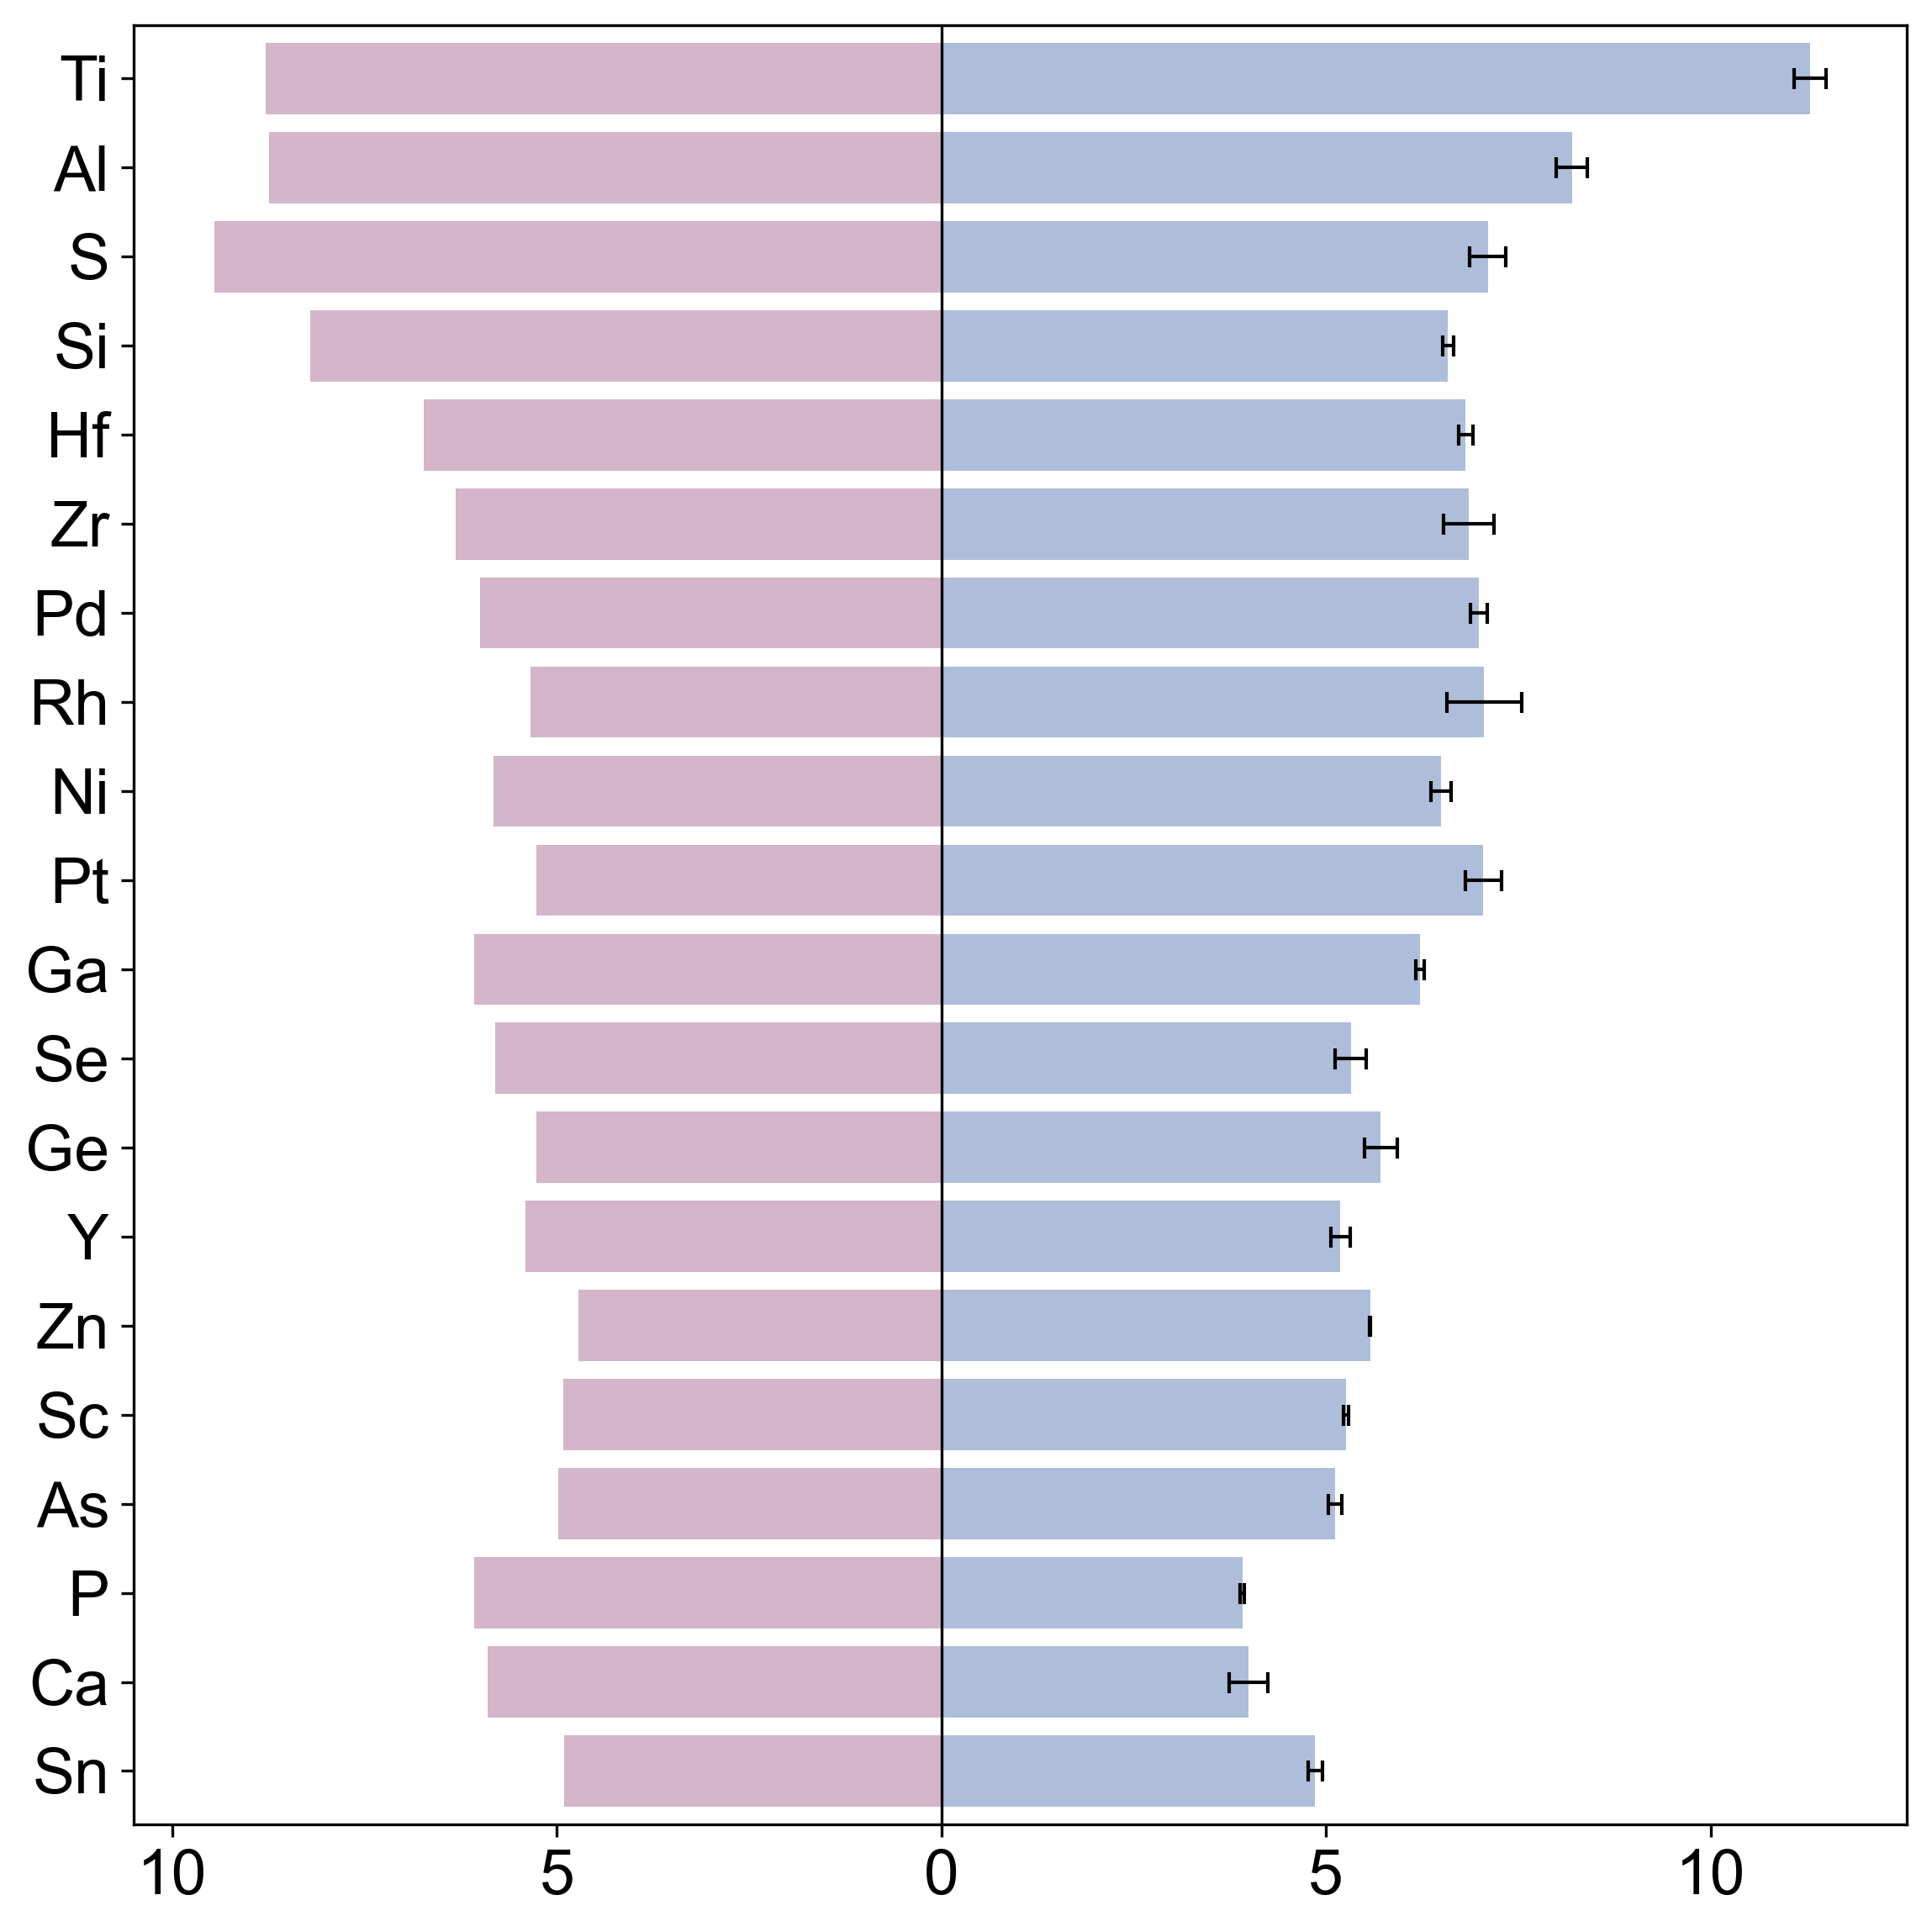

In [7]:
TOP_N = 20

N_SAMPLES = {
    "oc20": 455492,
    "gace0": 14428,
    "gace7": 14507,
    "gace42": 14392,
}

def load_percent(path, n_samples):
    df = pd.read_csv(path)
    df.columns = [str(c).strip().lower() for c in df.columns]
    elem_col = next(c for c in df.columns if c == "element")
    count_col = next(c for c in df.columns if c == "count")
    s = df.set_index(elem_col)[count_col].astype(float)
    return s / n_samples * 100.0

gace0 = load_percent("./data/oc20_and_gace/elemental_data/gace0_elements.csv", N_SAMPLES["gace0"])
gace7 = load_percent("./data/oc20_and_gace/elemental_data/gace7_elements.csv", N_SAMPLES["gace7"])
gace42 = load_percent("./data/oc20_and_gace/elemental_data/gace42_elements.csv", N_SAMPLES["gace42"])
oc20 = load_percent("./data/oc20_and_gace/elemental_data/oc20_elements.csv", N_SAMPLES["oc20"])

# Union of all elements across seeds + OC20
elements = sorted(set(gace0.index) | set(gace7.index) | set(gace42.index) | set(oc20.index))

gace0 = gace0.reindex(elements, fill_value=0.0)
gace7 = gace7.reindex(elements, fill_value=0.0)
gace42 = gace42.reindex(elements, fill_value=0.0)
oc20 = oc20.reindex(elements, fill_value=0.0)

# Mean and std across the three GACE seeds
gace_all = np.stack([gace0.values, gace7.values, gace42.values])
gace = pd.Series(gace_all.mean(axis=0), index=elements)
gace_err = pd.Series(gace_all.std(axis=0), index=elements)

combined = gace + oc20
freq_order = combined.sort_values(ascending=False).index

diff = (oc20).reindex(elements)
diff_sorted = diff.reindex(freq_order)
print("\nGACE - OC20 (percentage points), ordered by frequency (GACE + OC20):")
for elem, d in diff_sorted.items():
    print(f"  {elem:>3s}: {d:+.2f}")

order = freq_order[:TOP_N].tolist()[::-1]  # largest on top
y = np.arange(len(order))

fig_c = plt.figure(figsize=(8, 8), dpi=300)
plt.barh(y, gace.reindex(order).values, xerr=gace_err.reindex(order).values,
         color="#AEBEDA", label="GACE",
         error_kw=dict(elinewidth=1, capsize=3, capthick=1))
plt.barh(y, -oc20.reindex(order).values, color="#D4B5CA", label="OC20")

plt.yticks(y, list(order))

xt = plt.xticks()[0]
plt.gca().set_xticklabels([f"{abs(t):.0f}" for t in xt])

plt.axvline(0, color="black", linewidth=0.8)
plt.margins(y=0.01)
plt.tight_layout()

save_flat_svg(fig=fig_c, path="fig2/panel/elemental_dist.svg")

== O ==
Dropped 2 out of 566 structures
Dataset mean and std: -0.07133507177379009 ± 1.6899759556623215
Mean GACE: 0.013201895704928863 ±  1.8840381915942892
Wasserstein distance b/t GACE and dataset: 0.11155410587510213
== CH2O ==
Dropped 2 out of 375 structures
Dataset mean and std: -1.6163247860800356 ± 1.1391554254763652
Mean GACE: -1.5115637724105537 ±  1.2634483712765332
Wasserstein distance b/t GACE and dataset: 0.16484338864763695
== COCH2OH ==
Dropped 1 out of 380 structures
Dataset mean and std: -2.7752614738444223 ± 1.530674629473624
Mean GACE: -2.4730144838229964 ±  1.6858311711391534
Wasserstein distance b/t GACE and dataset: 0.3177572395996557
== C2H(OH)2 ==
Dropped 1 out of 290 structures
Dataset mean and std: -1.8537488873084447 ± 1.5712464984899868
Mean GACE: -1.750956443973066 ±  1.7720881789062877
Wasserstein distance b/t GACE and dataset: 0.1600378713035589
== C2H4OH ==
Dropped 2 out of 340 structures
Dataset mean and std: -3.5422160420897444 ± 1.0083133023941944
Me

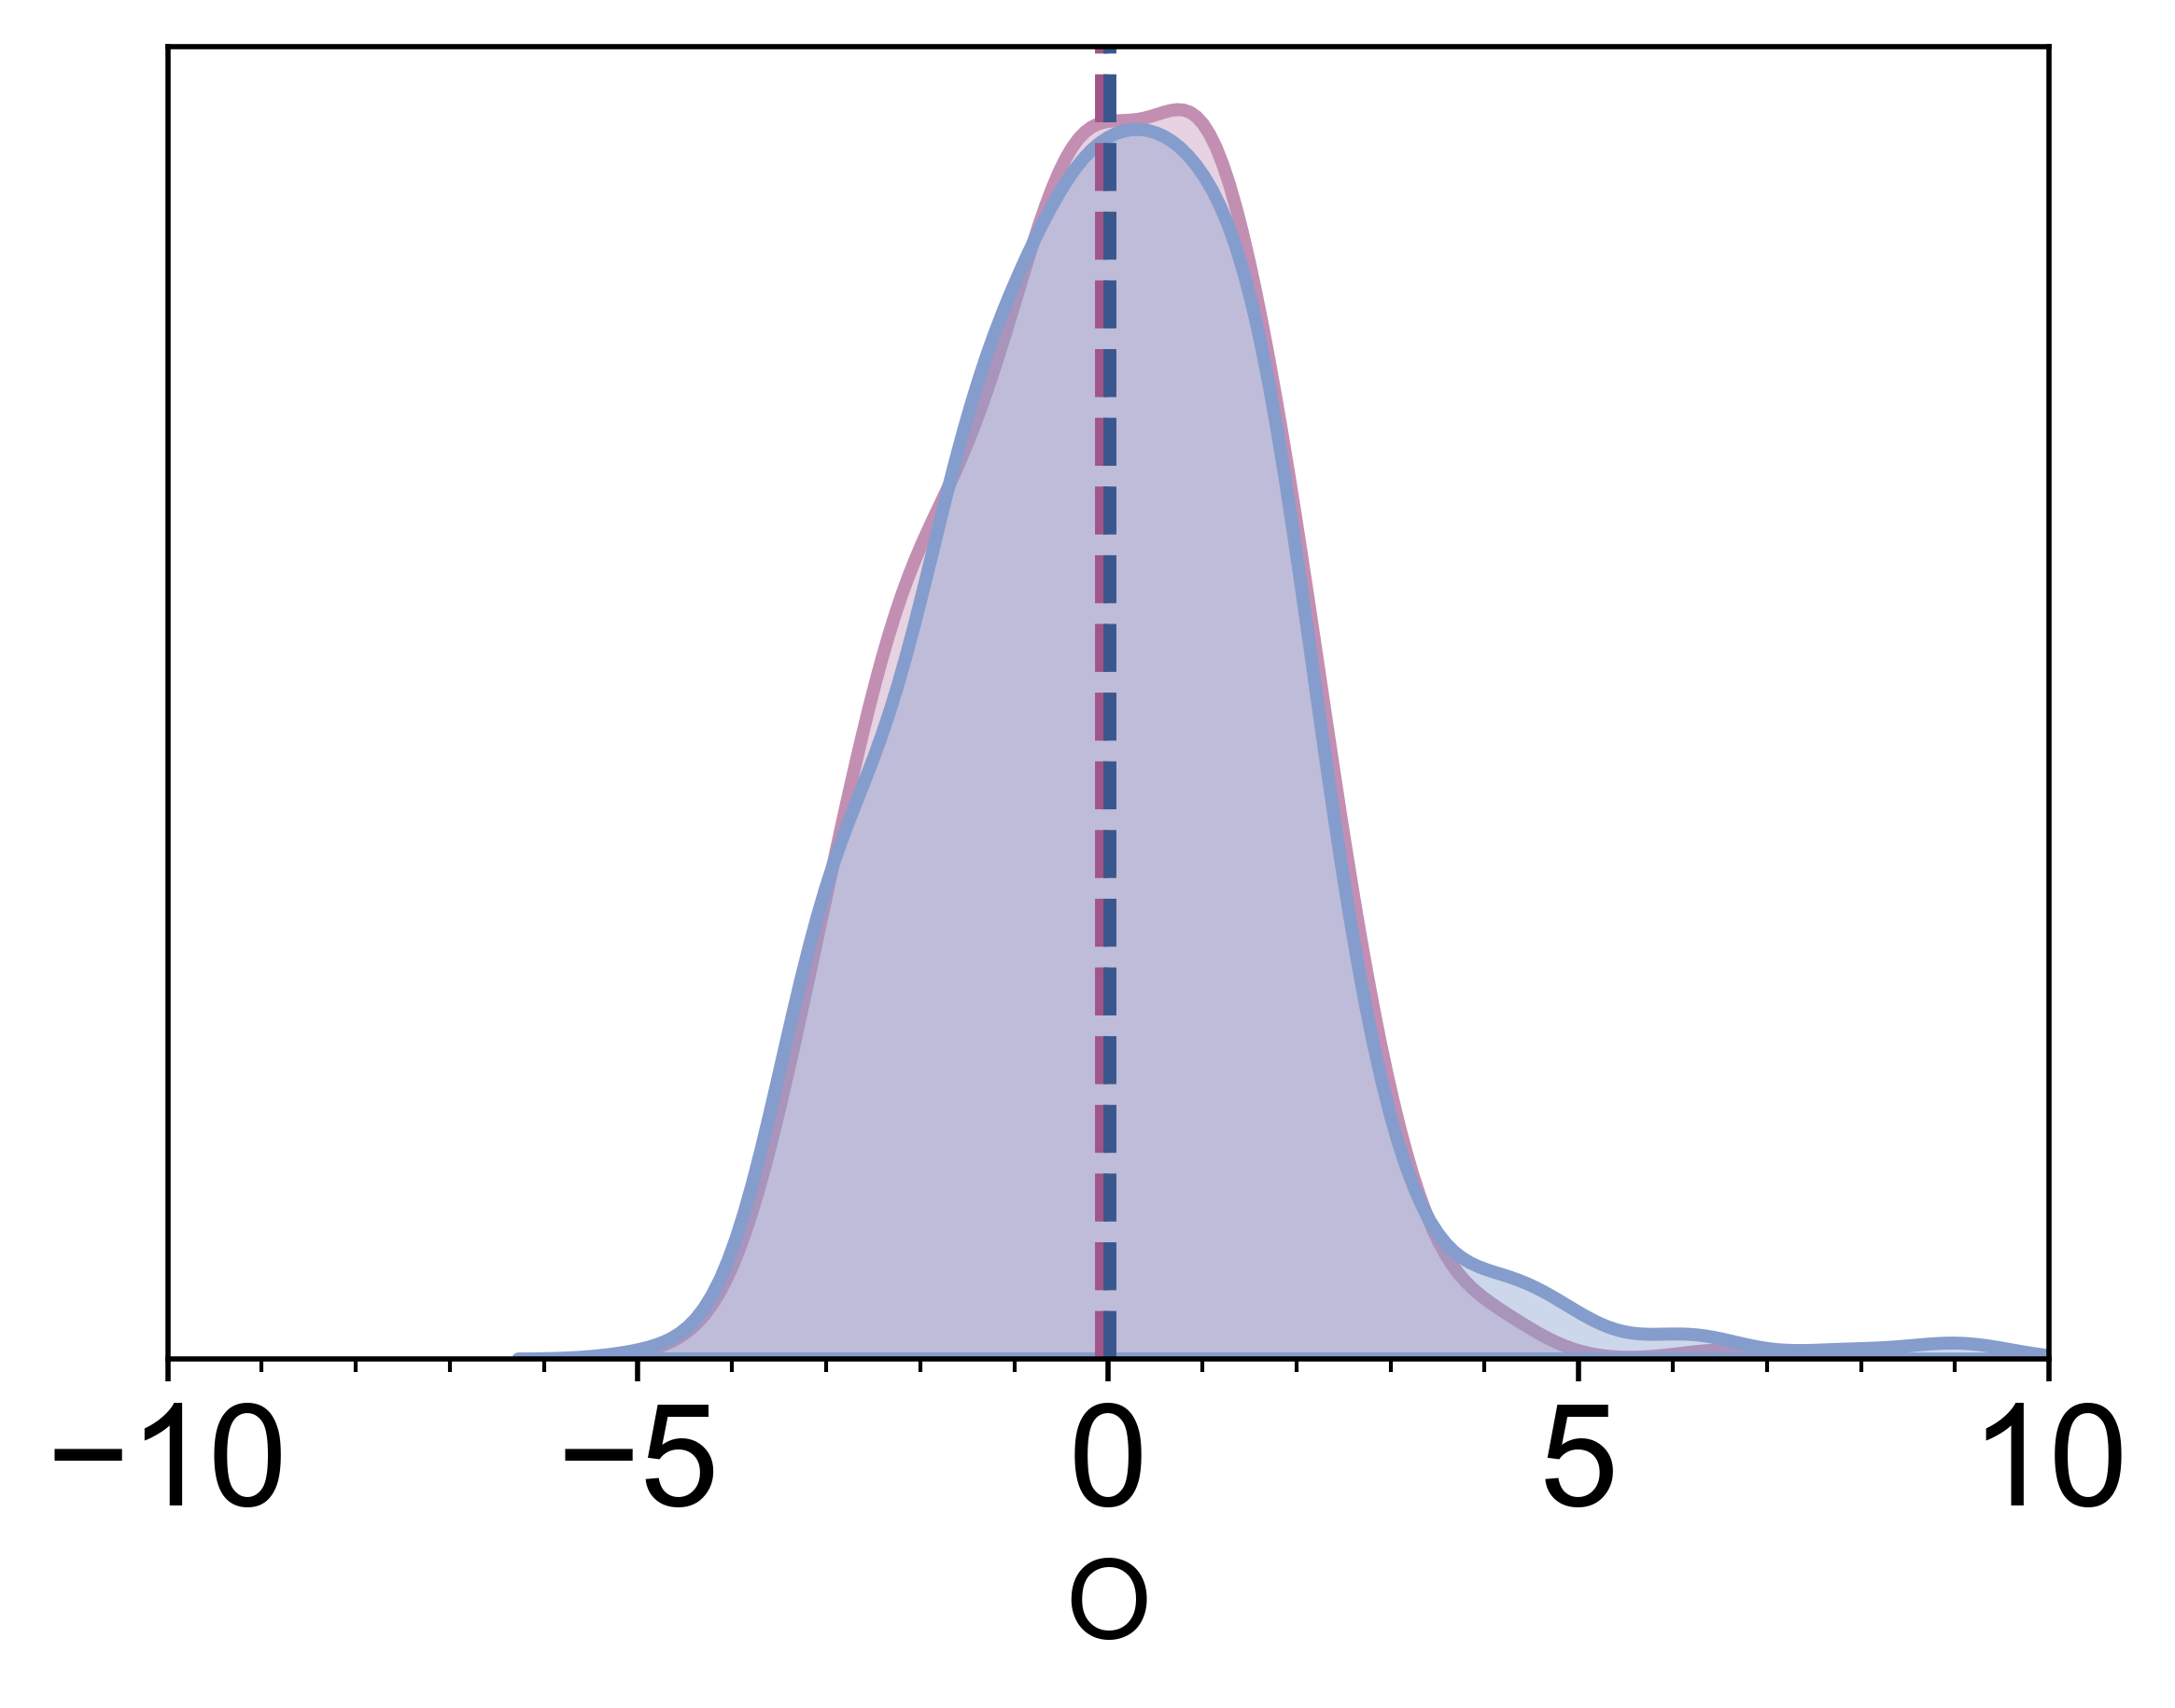

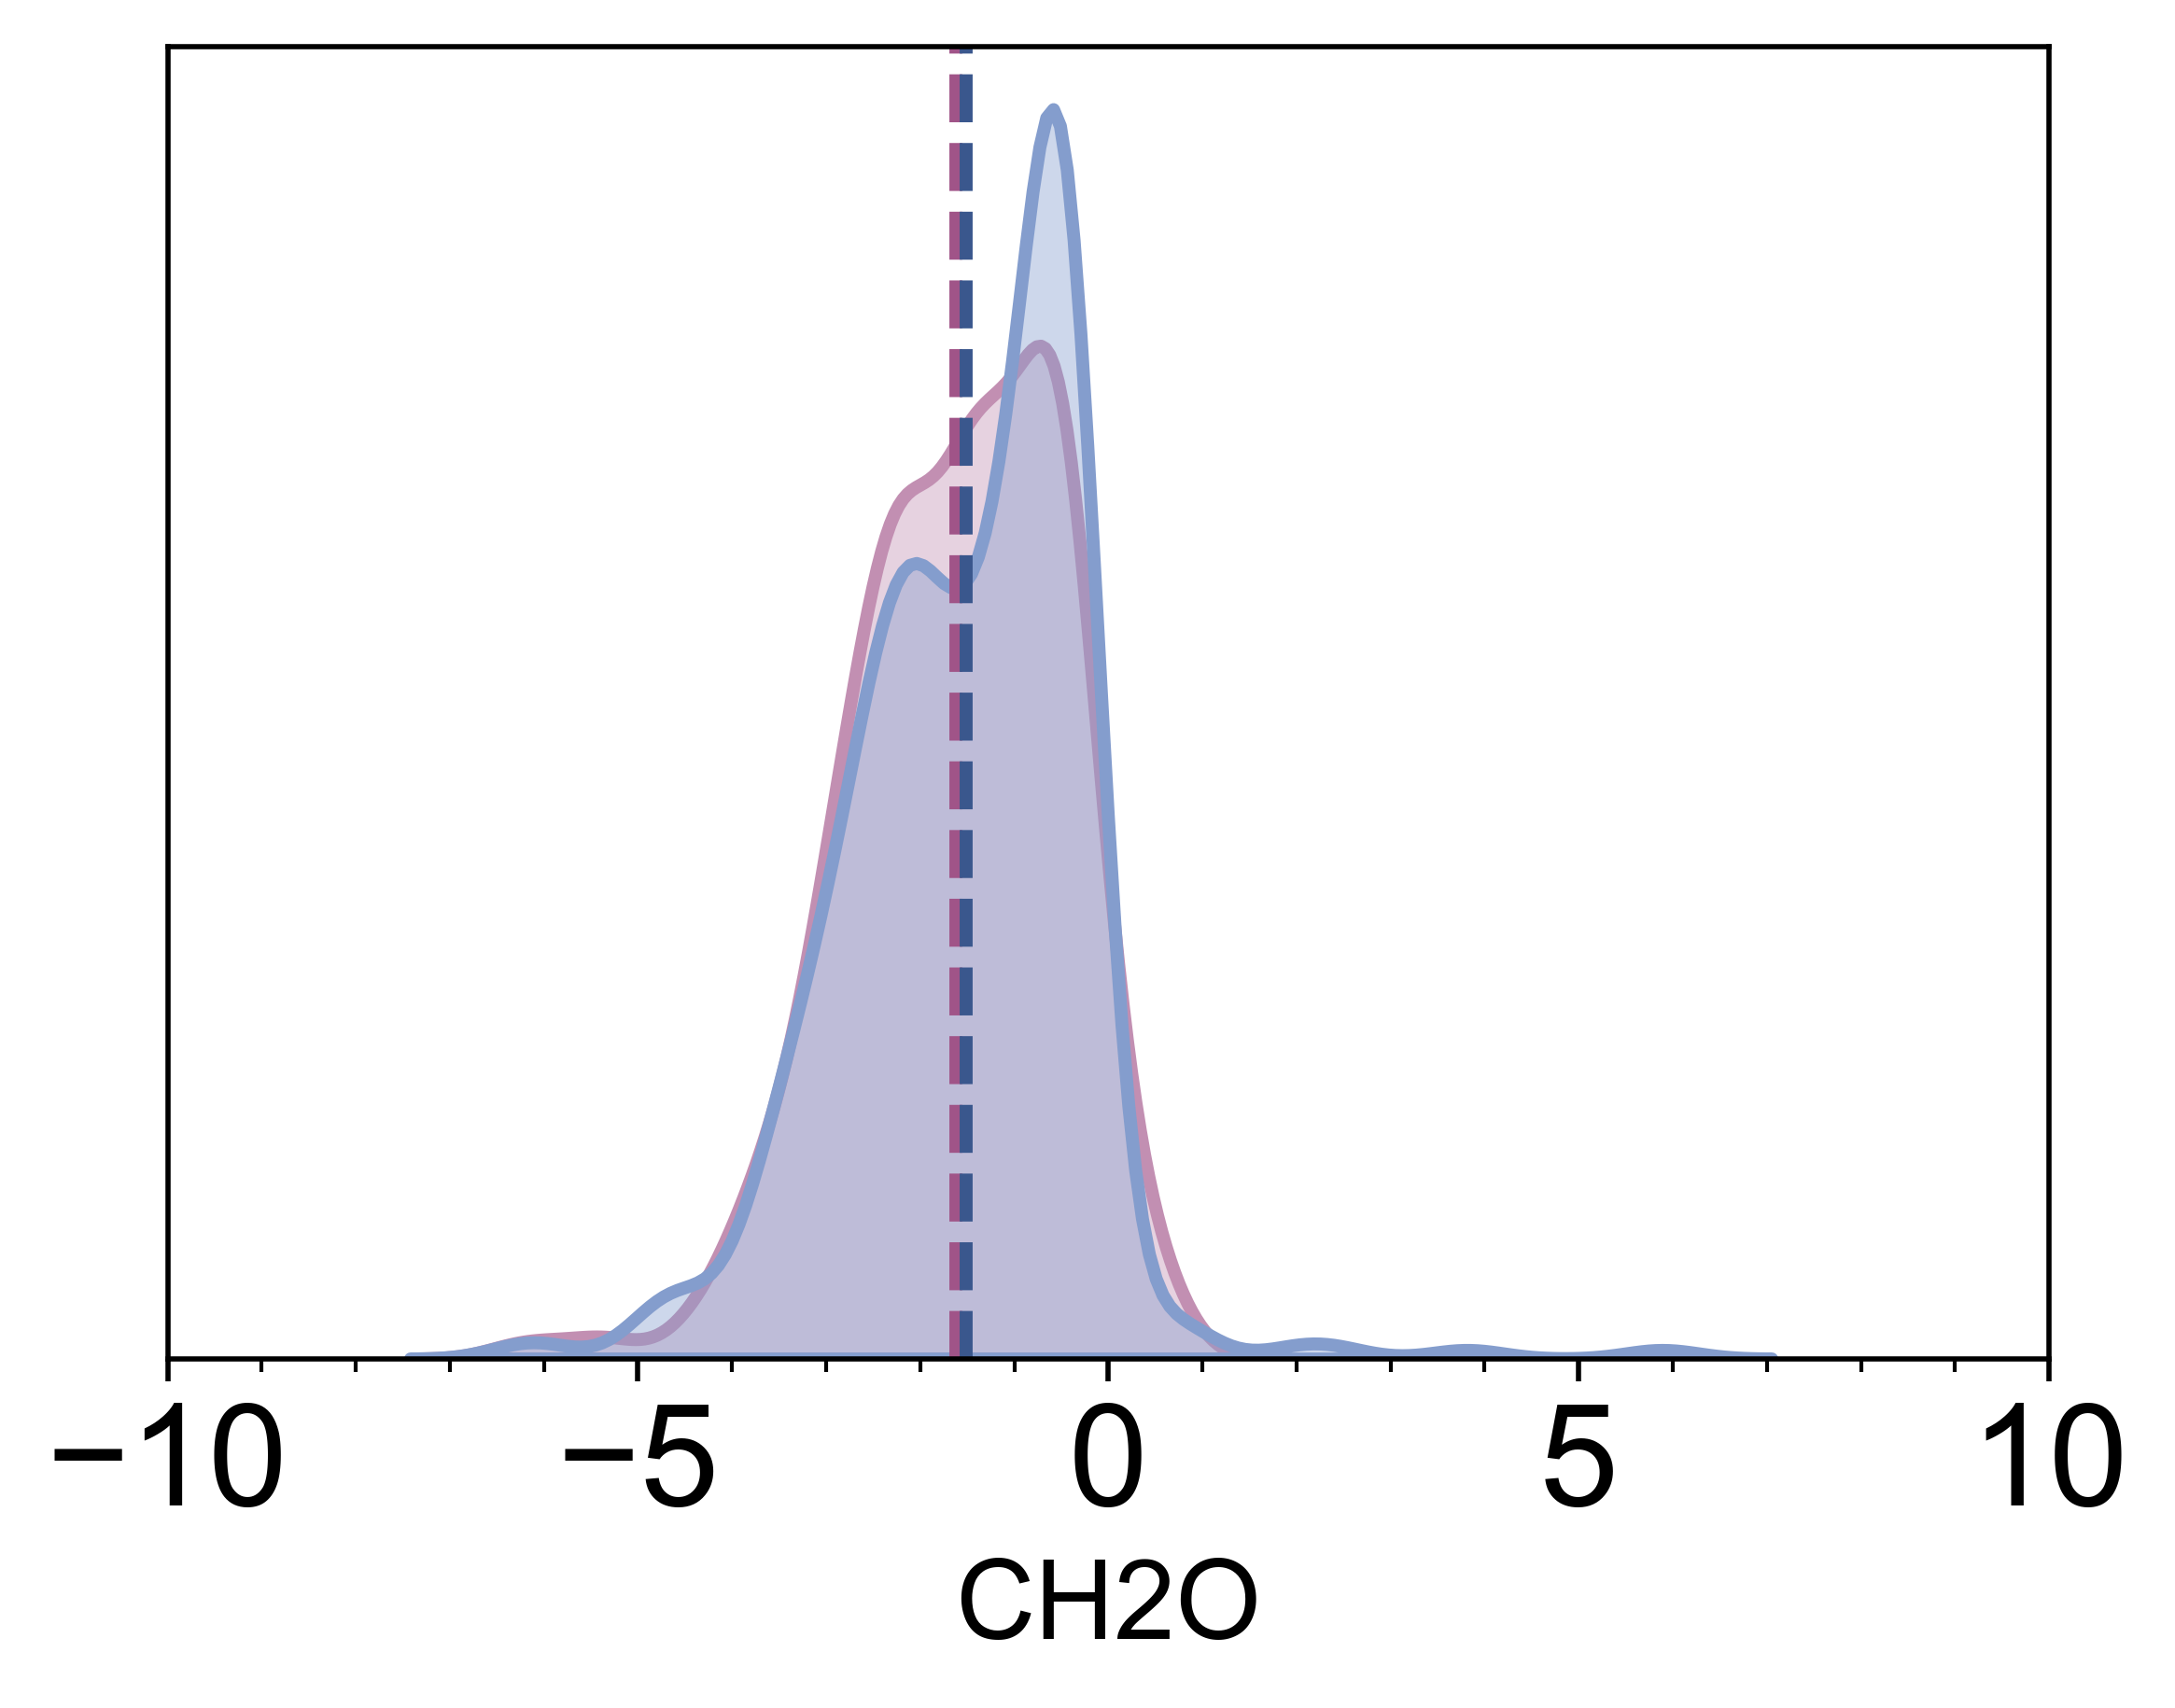

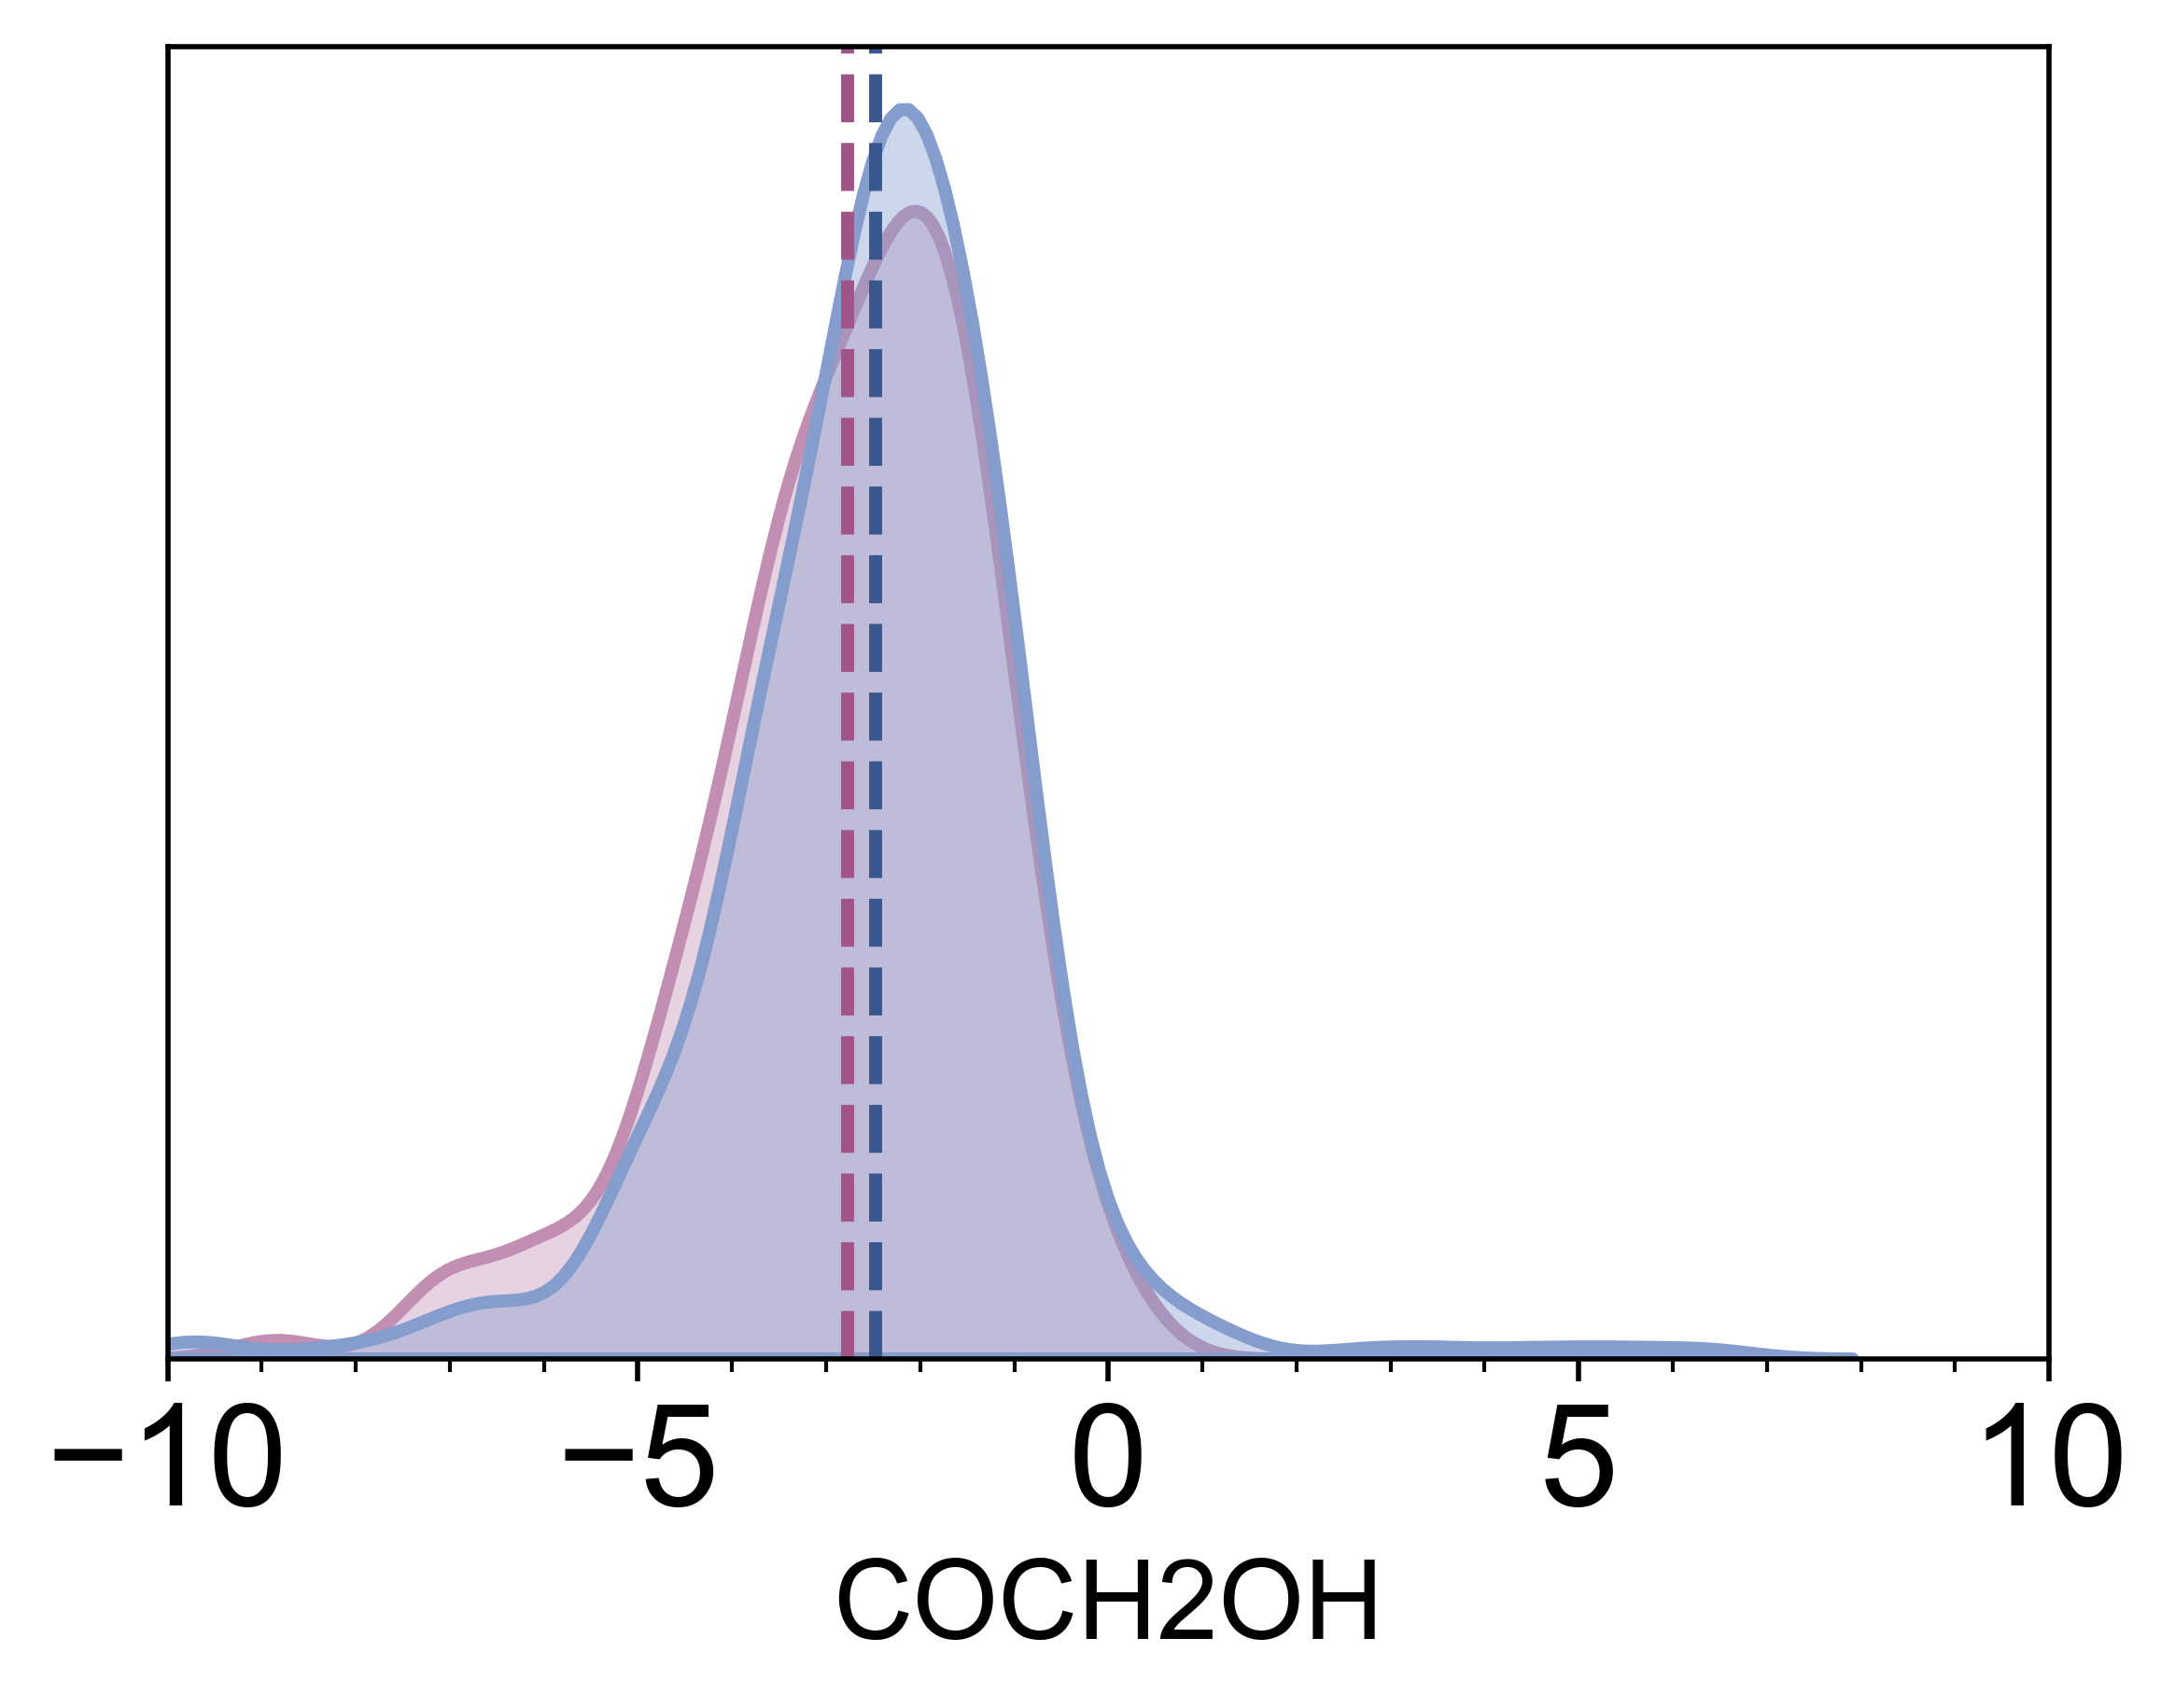

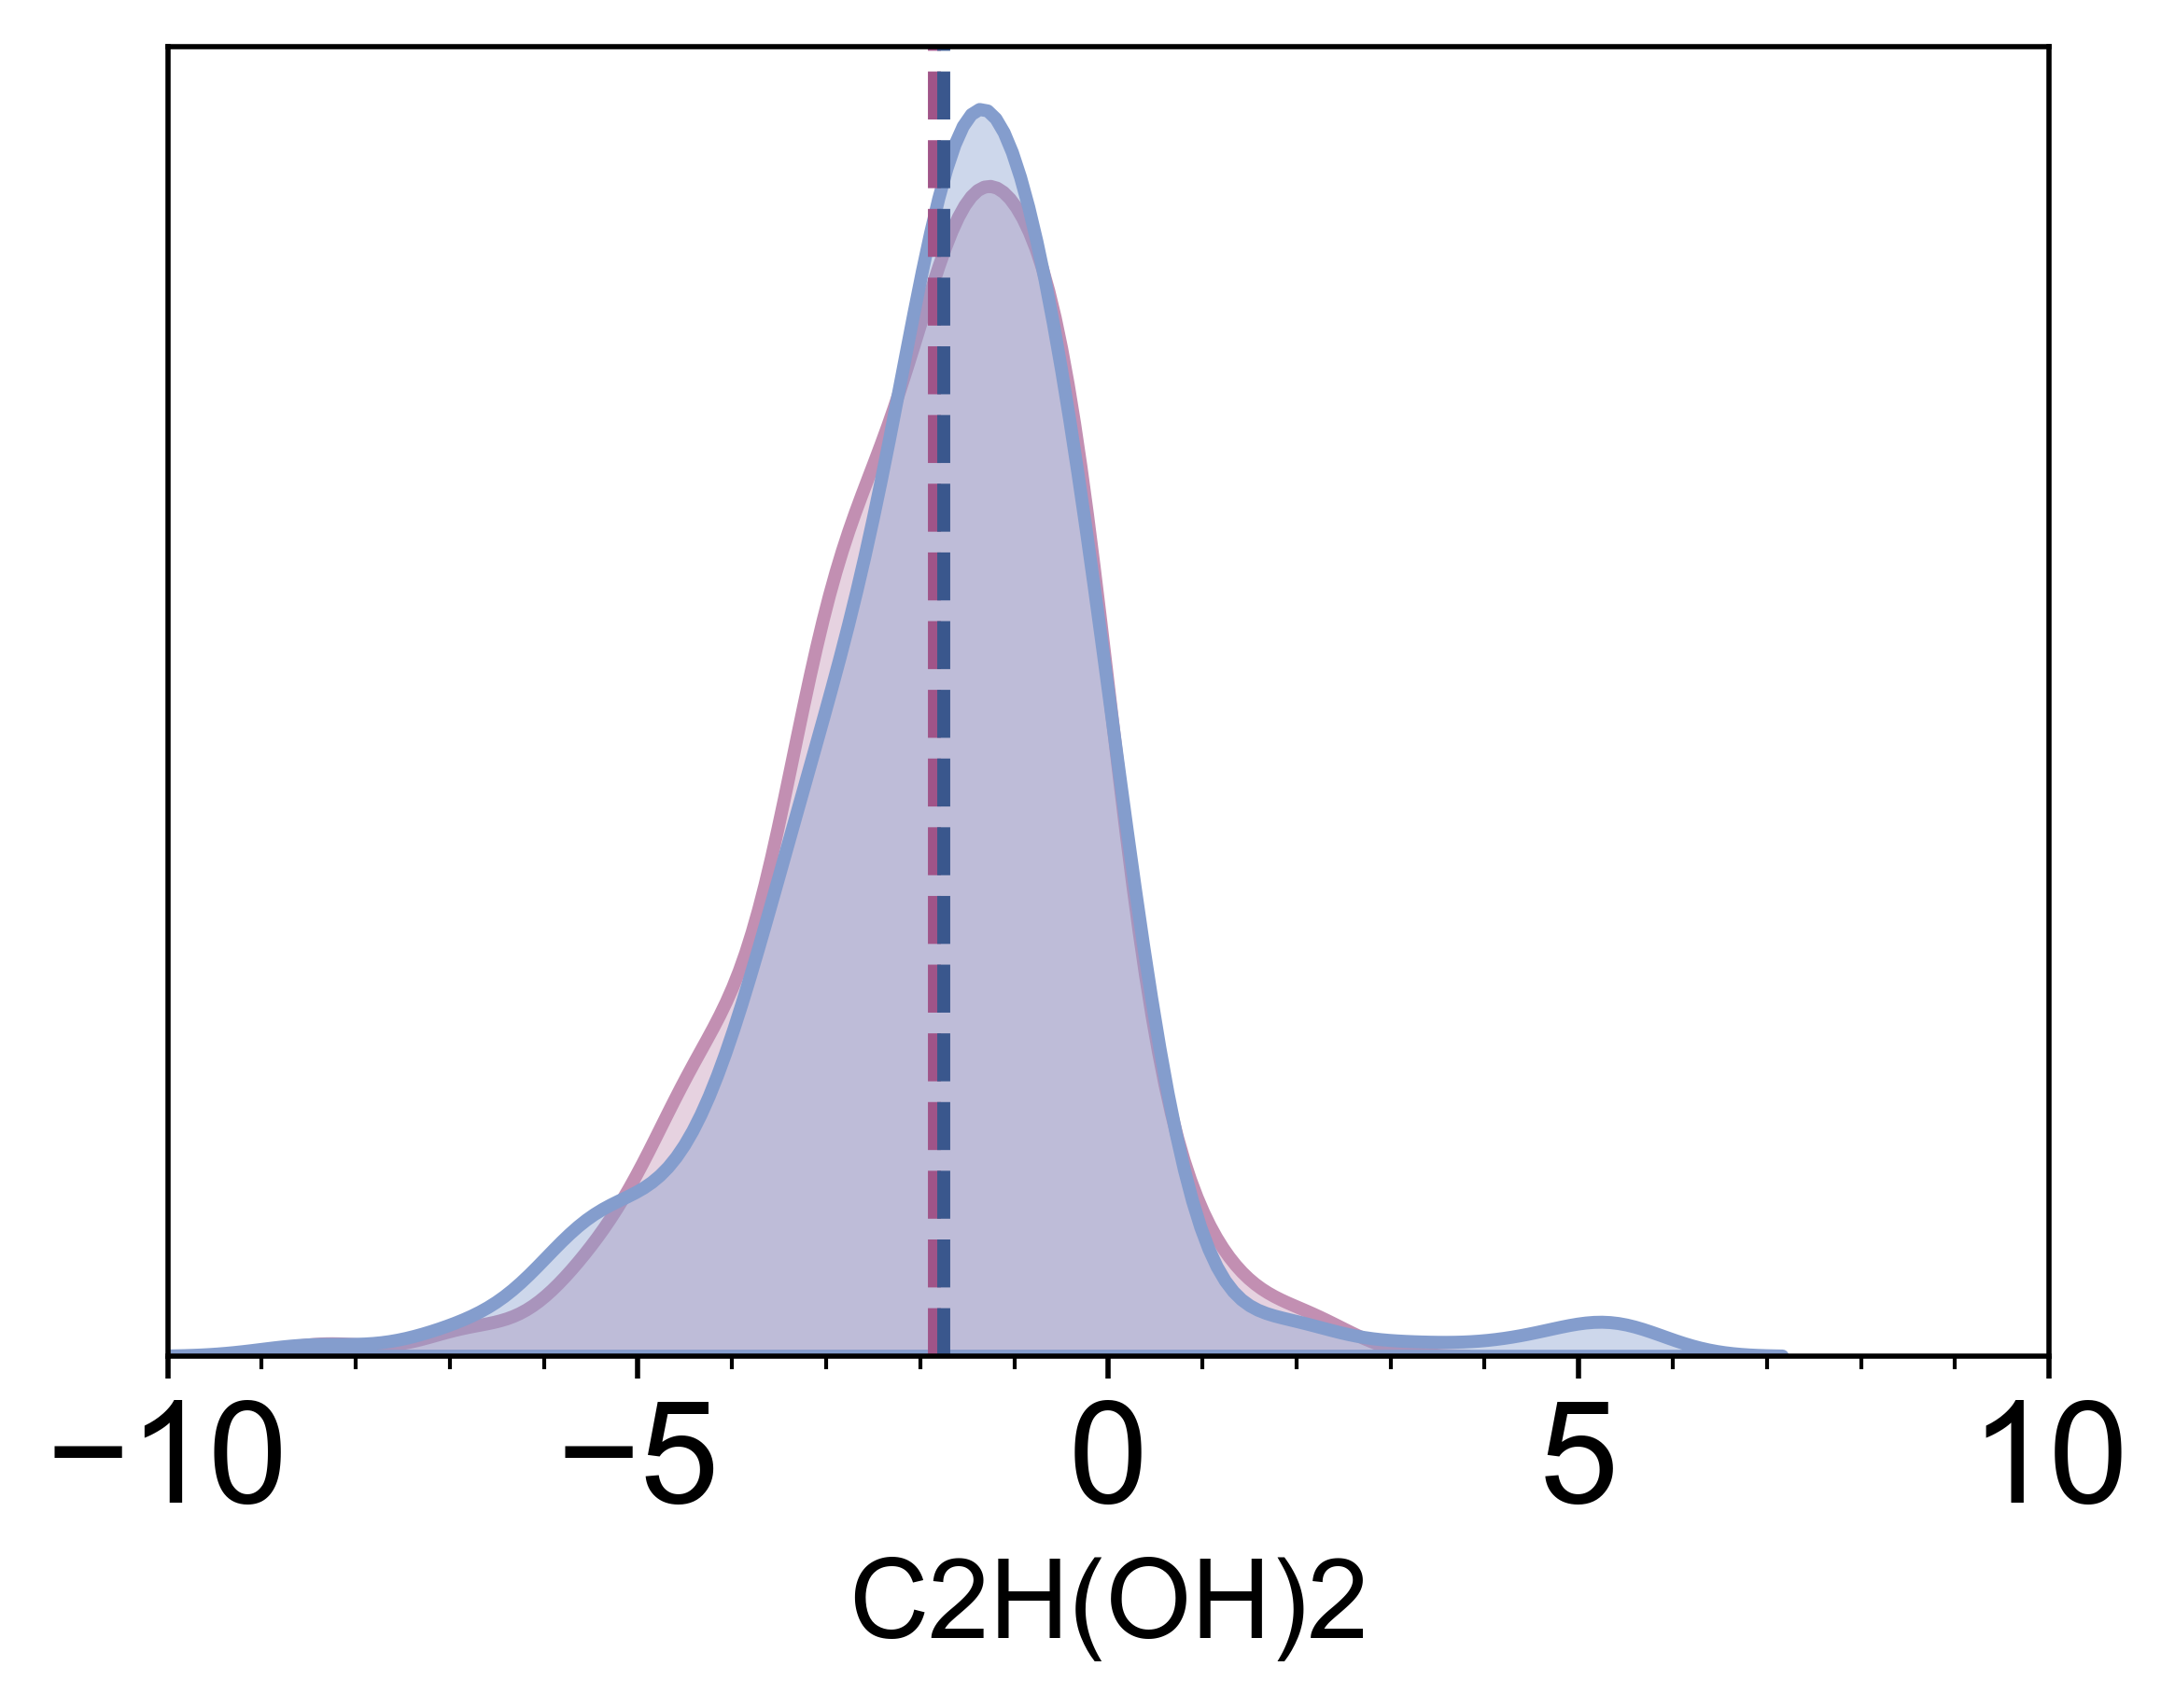

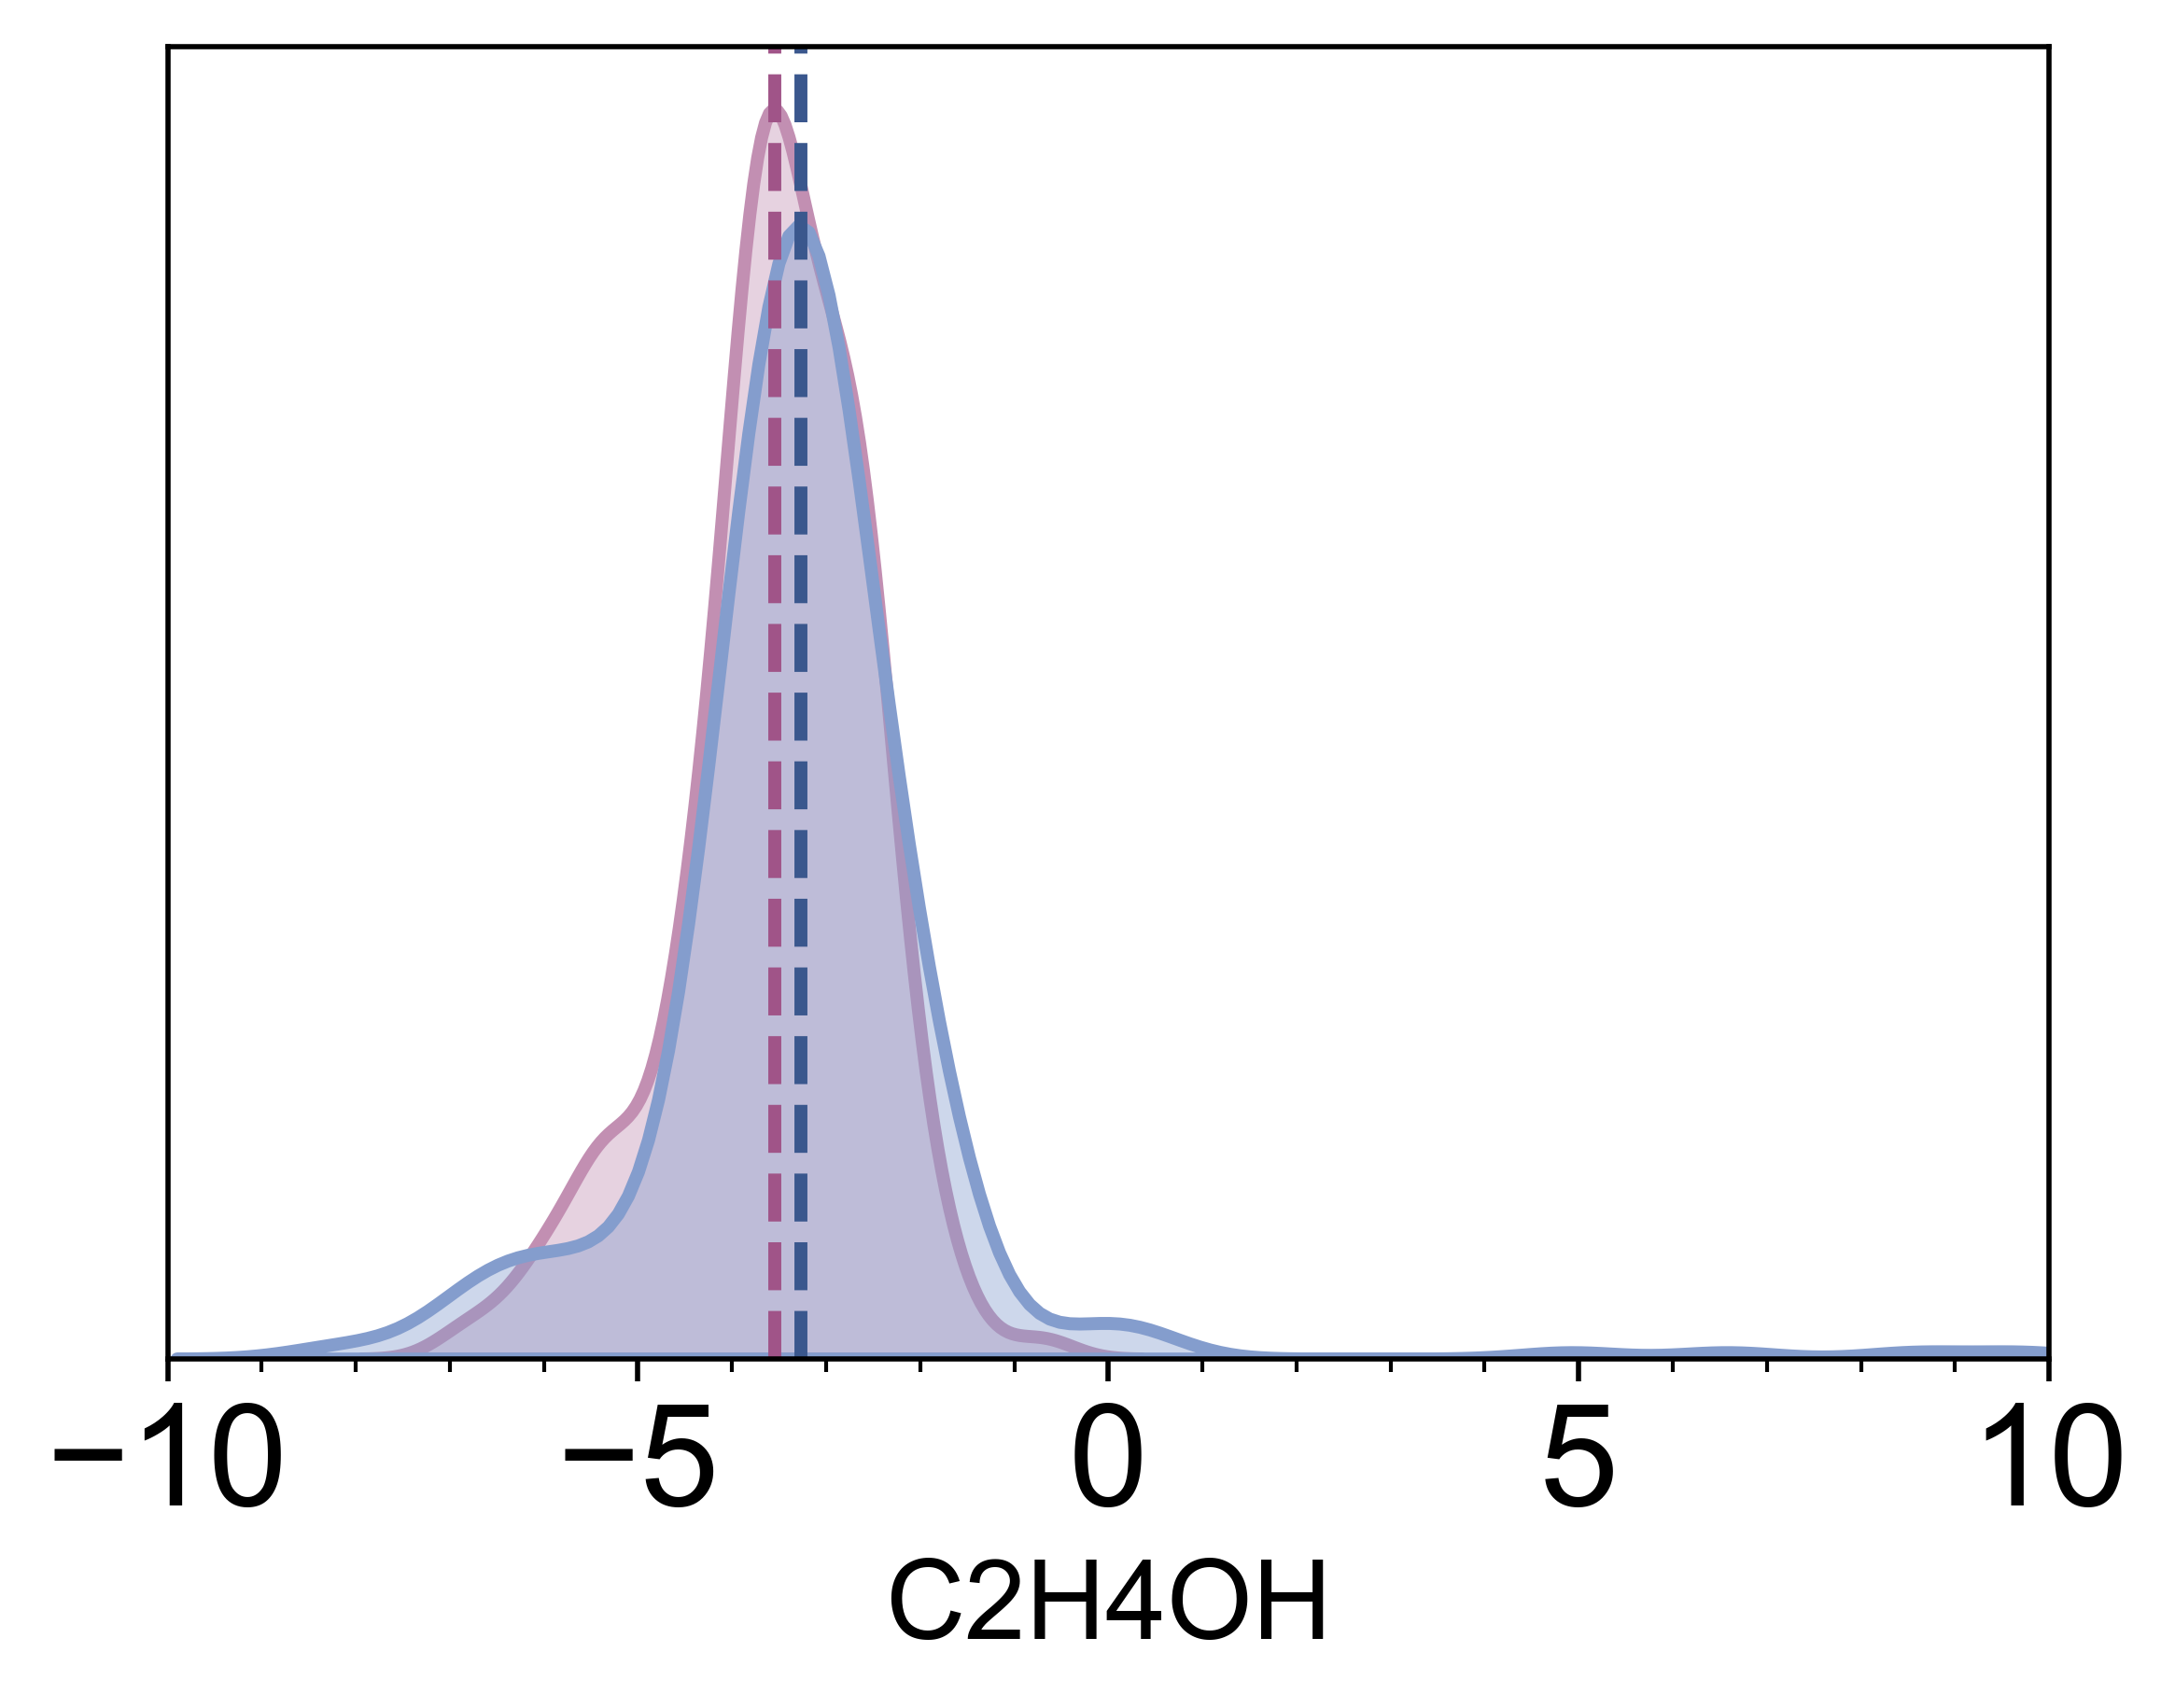

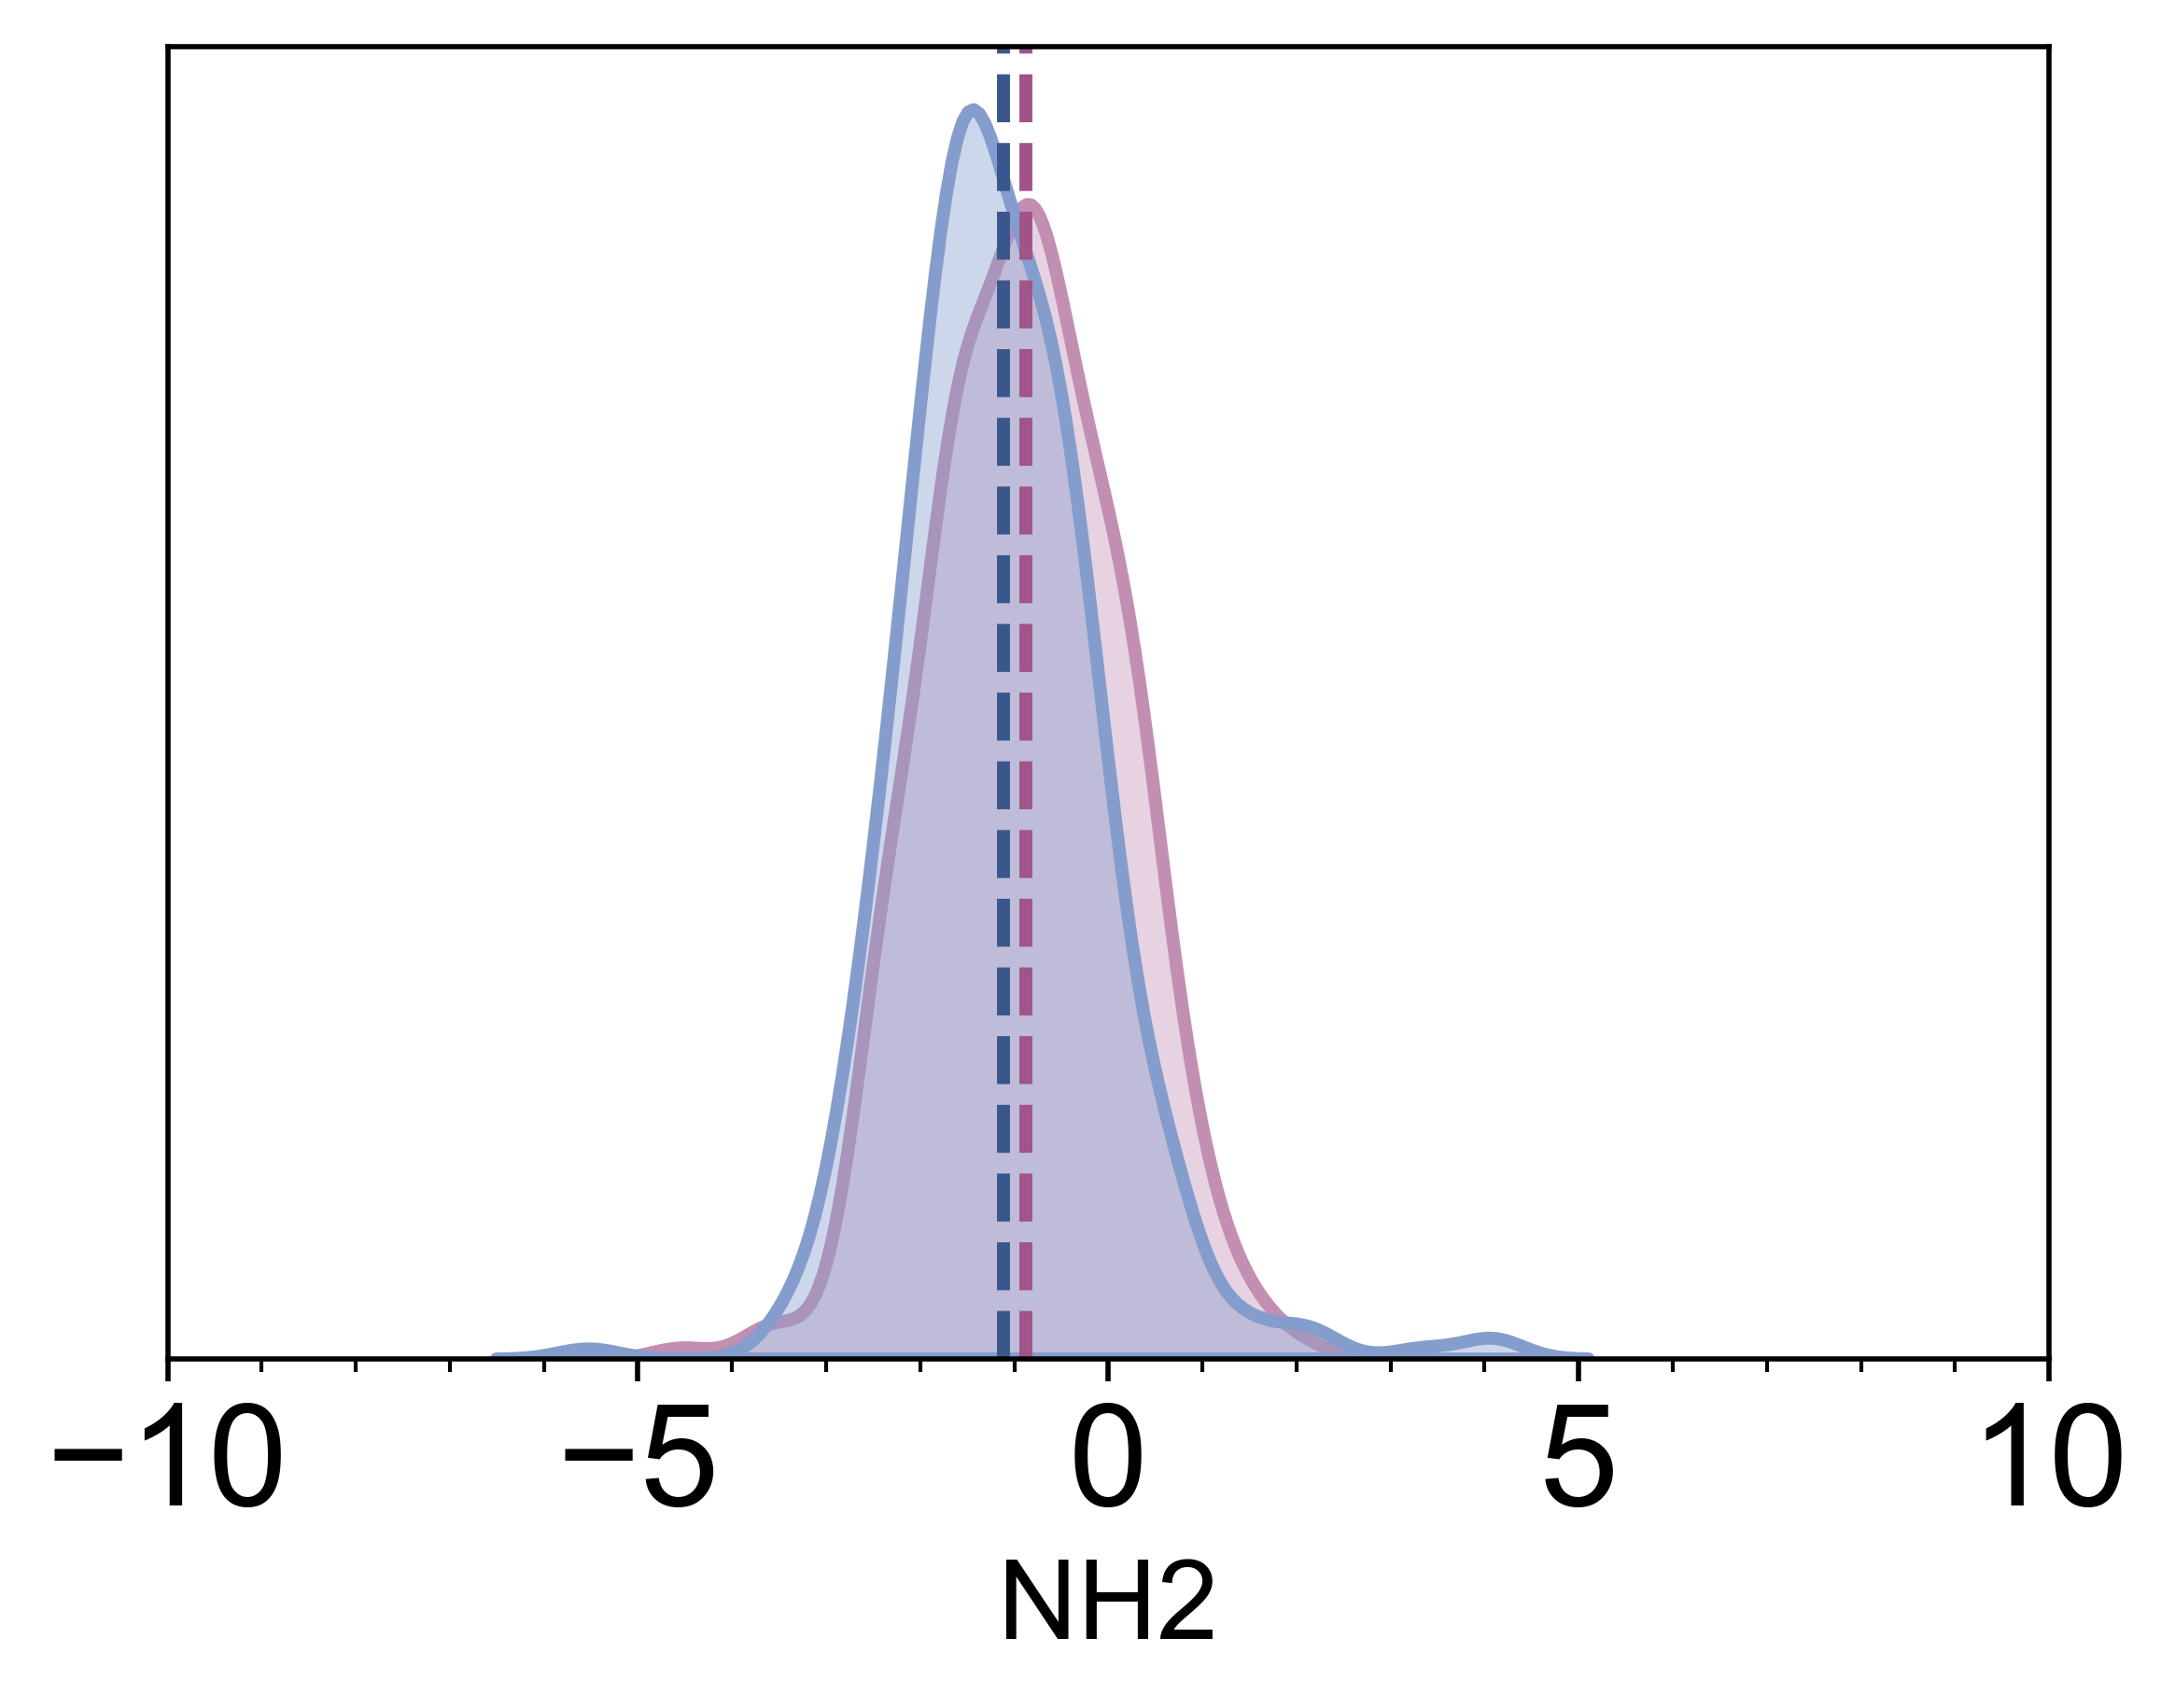

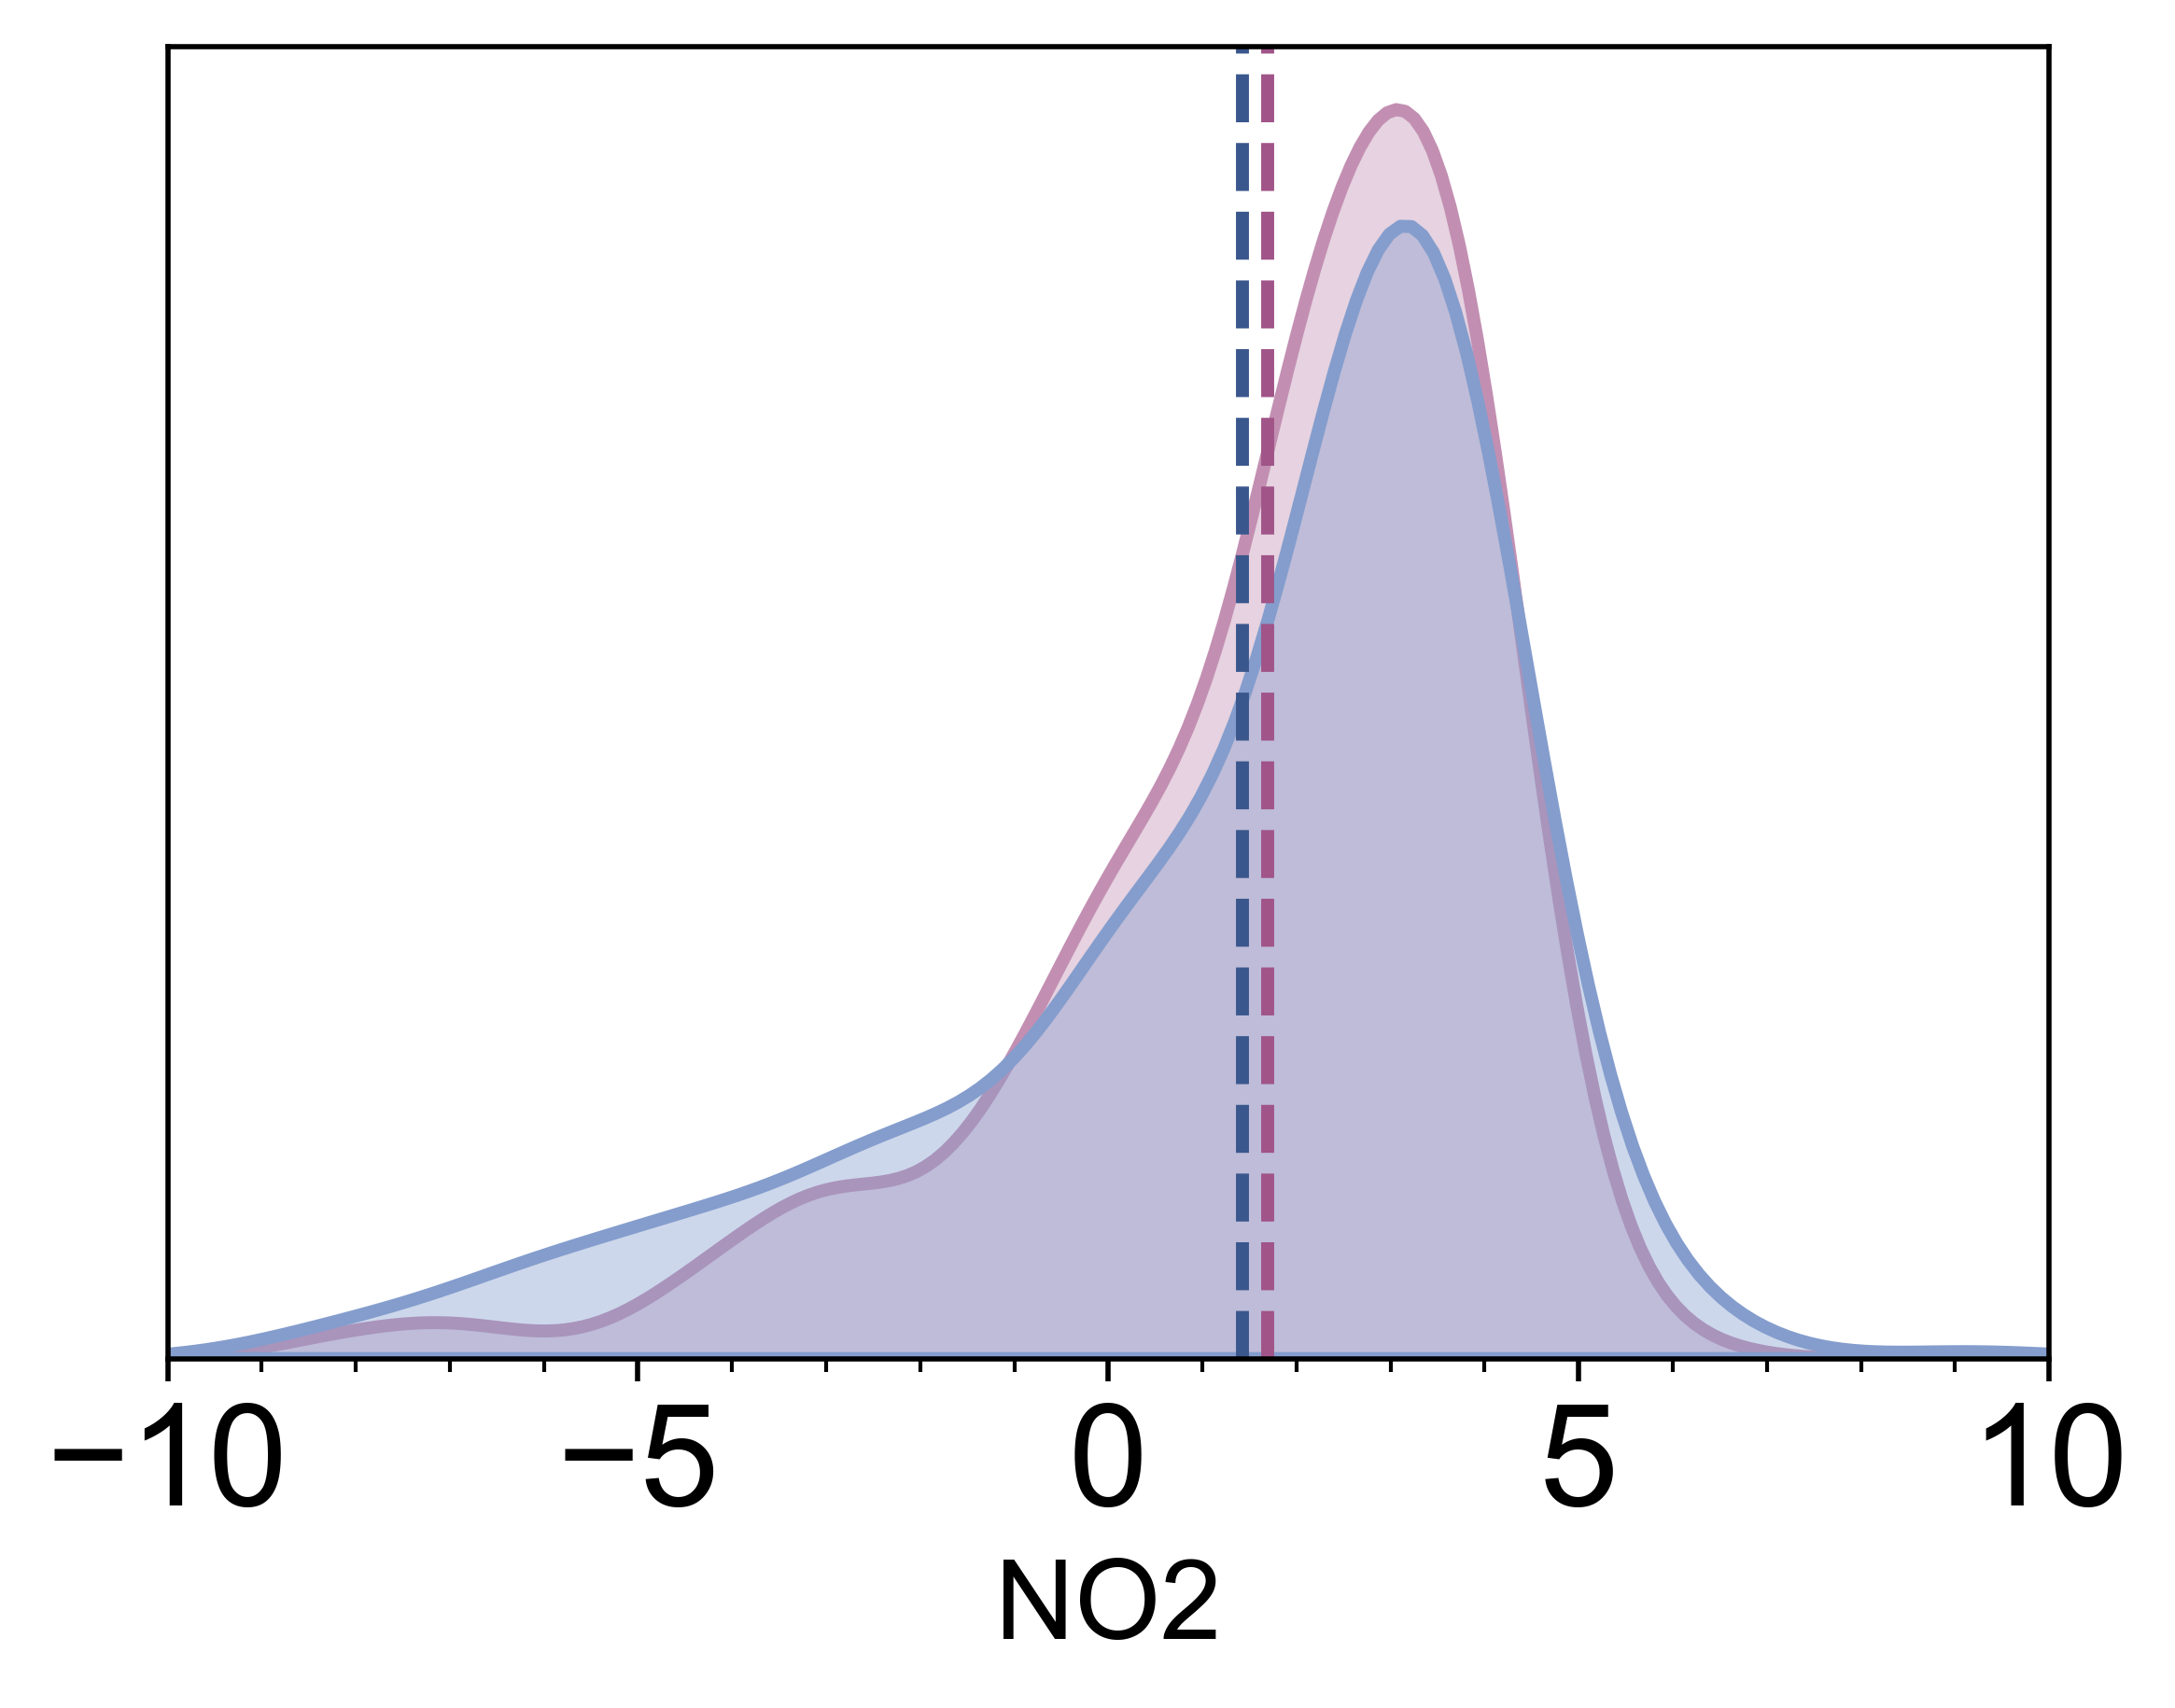

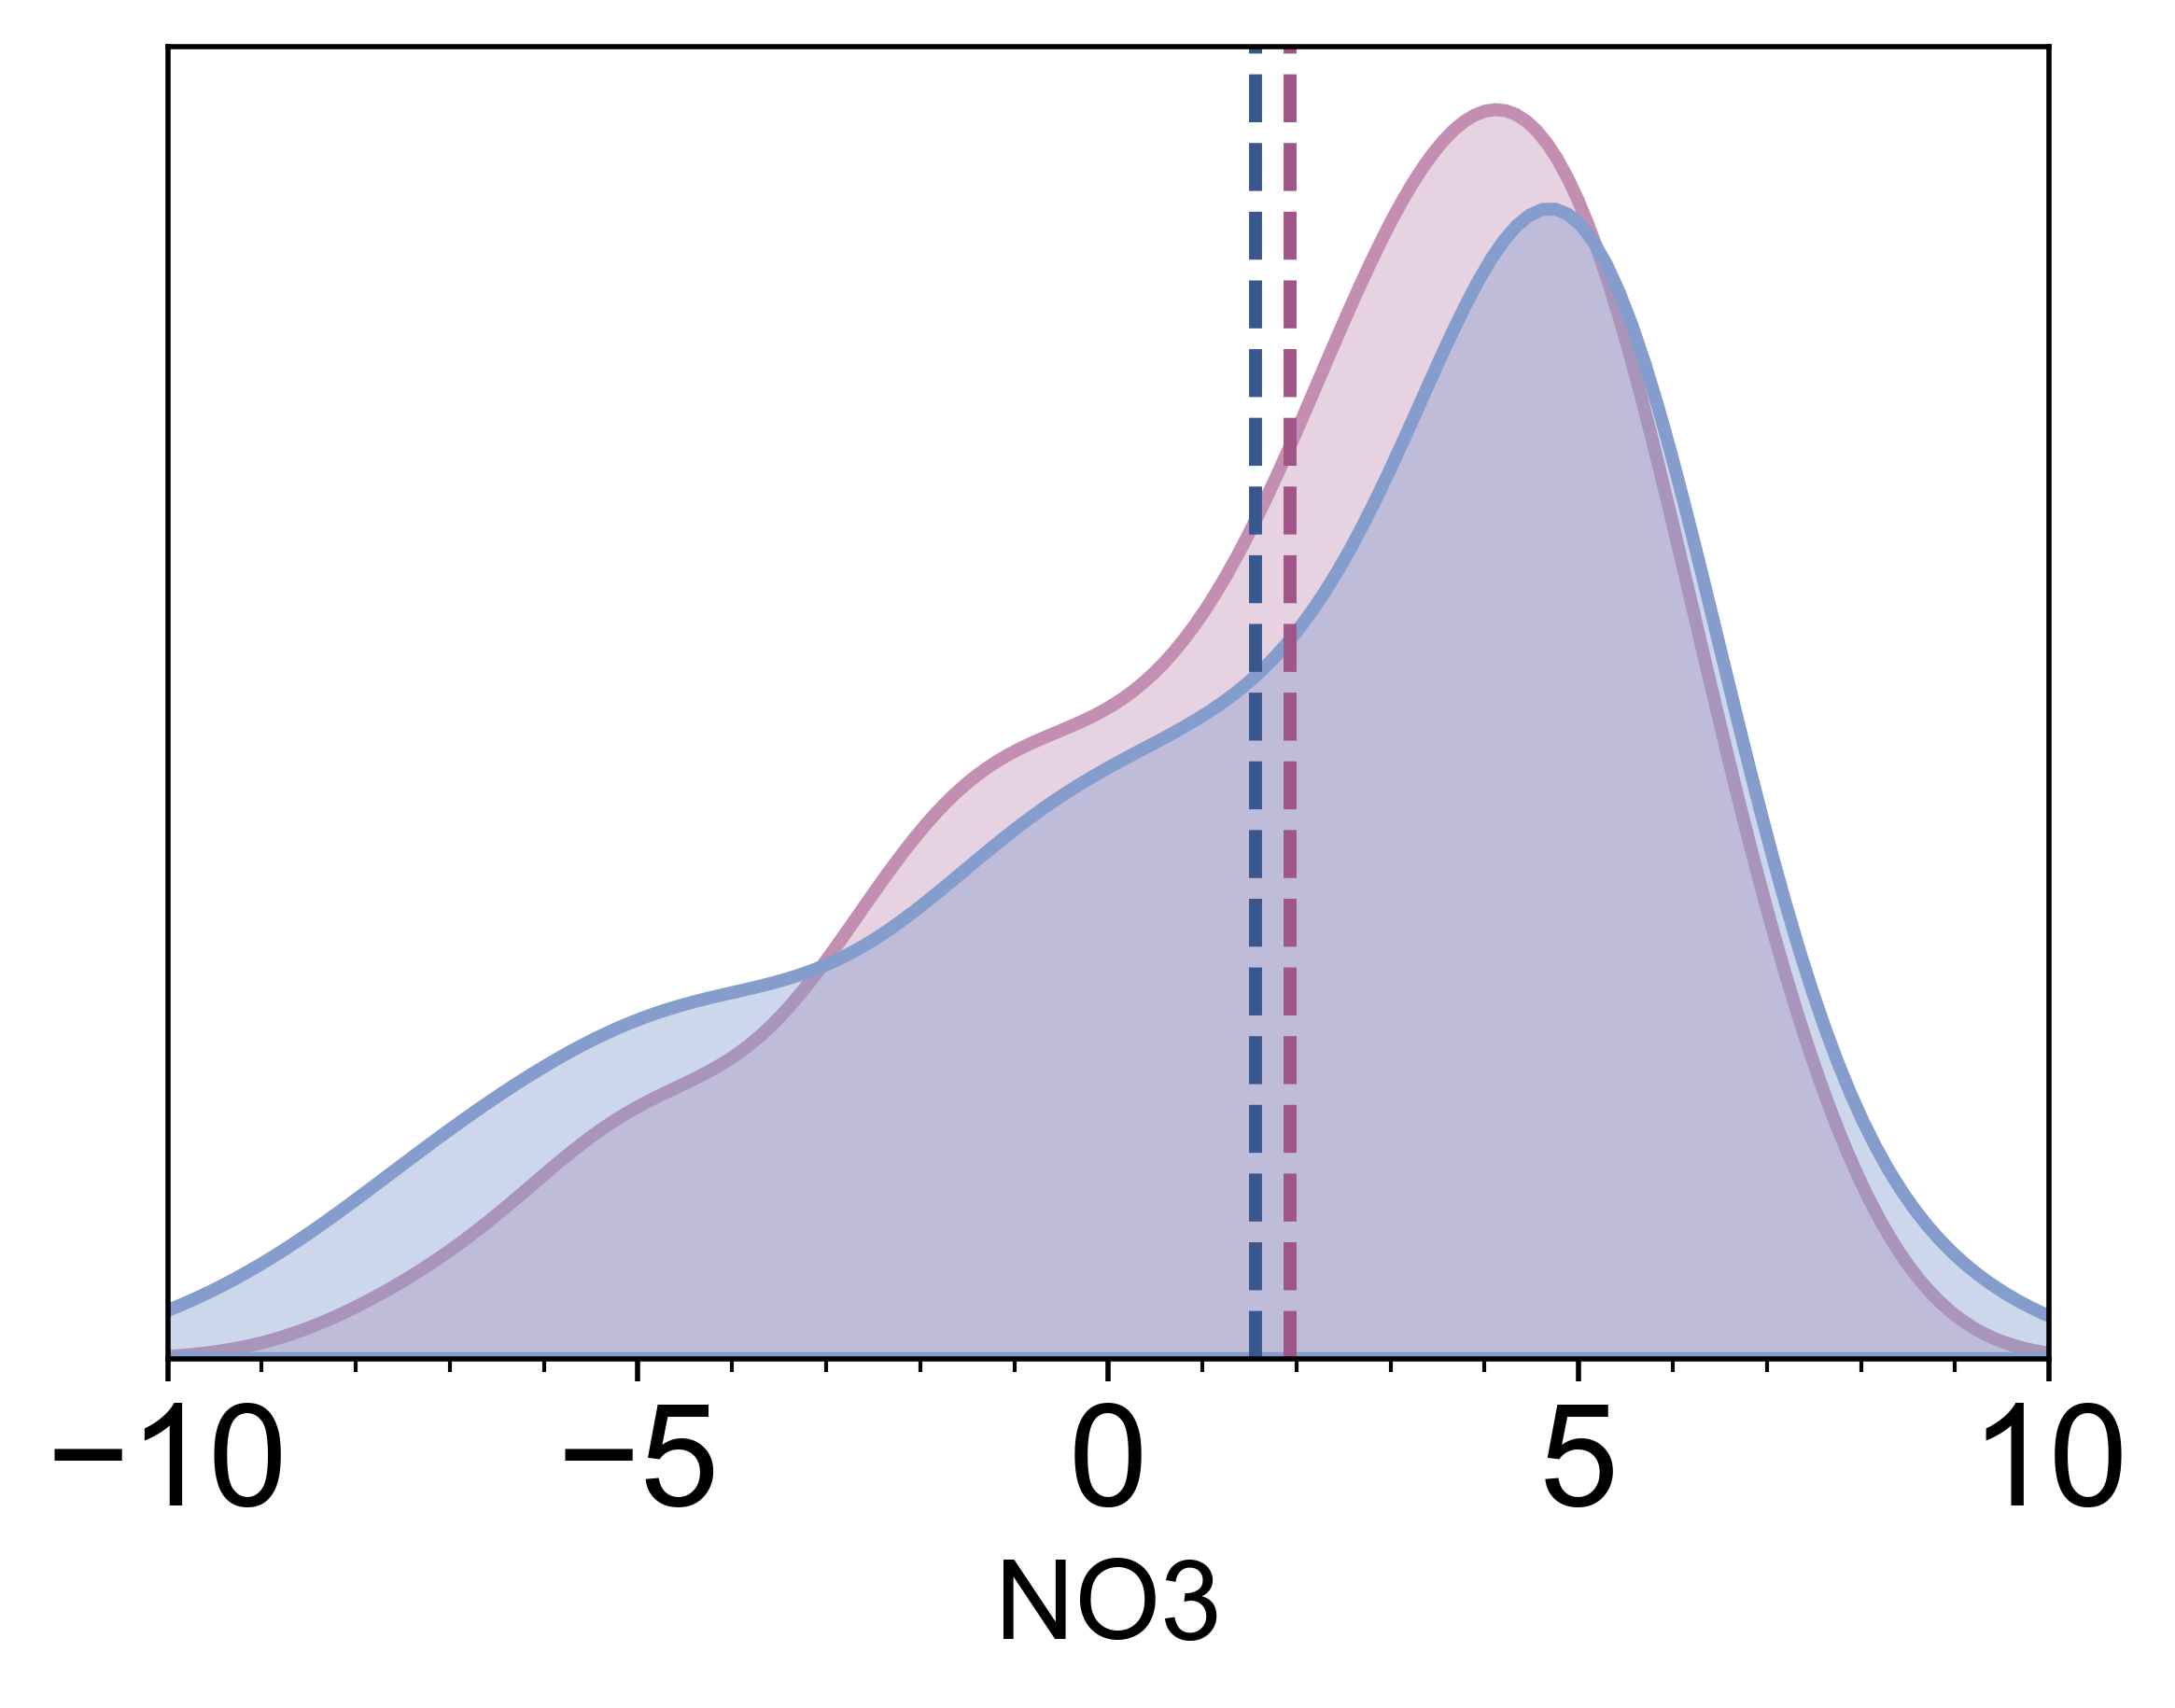

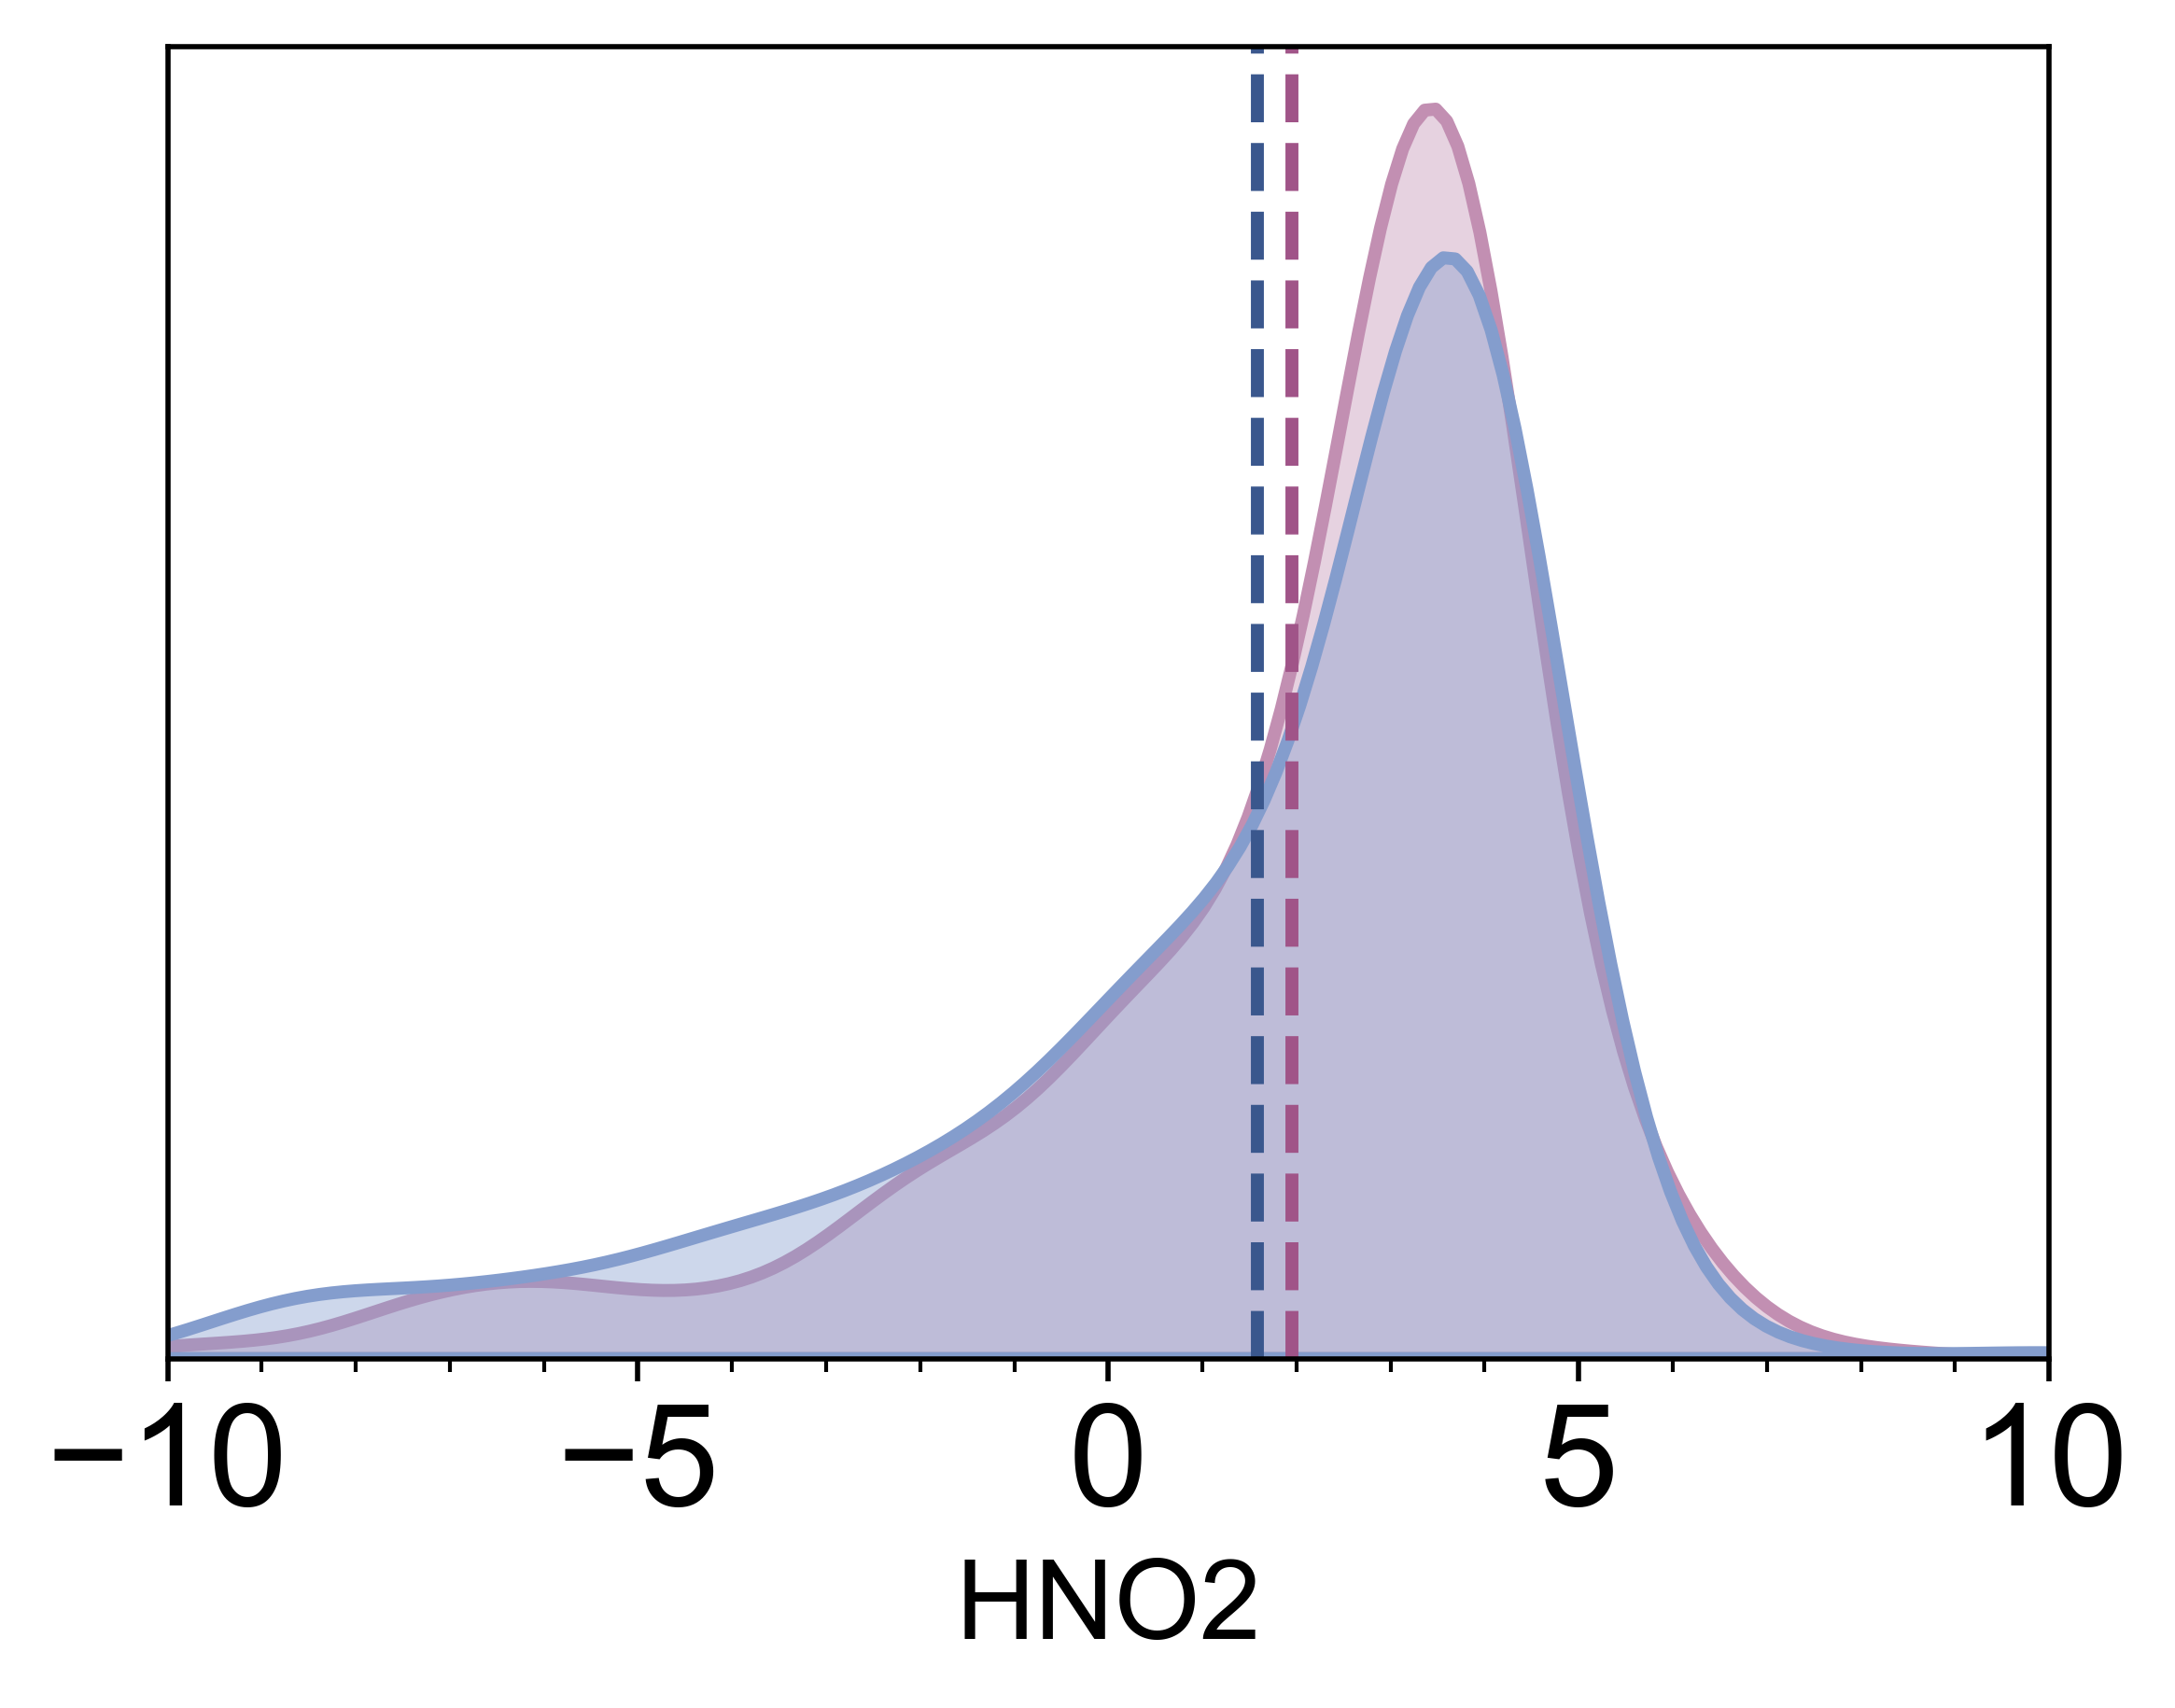

In [8]:
"""
Compare predicted (GACE) vs. reference (dataset) adsorption energies per
adsorbate, via summary stats, Wasserstein distance, and KDE overlay plots.

Setup:
  - DATA_DIR: root folder containing per-adsorbate subfolders
    ("ads_<num>/energies.csv").
  - ads_dict: maps adsorbate name (e.g. "O", "CH2O") -> its numeric ID used
    in file/column naming. Edit this to choose which adsorbates to plot.
  - SELECTED_NUMS: the numeric IDs to iterate over (all values of ads_dict).
  - FILTER_RANGE = (-10, 10): energy bounds (eV) used to discard outlier rows.
  - XLIM = (-10, 10): x-axis limits for the energy distribution plots.

For each adsorbate ID in SELECTED_NUMS:
  1. Loads "{DATA_DIR}/ads_{num}/energies.csv", which contains a GACE-predicted
     adsorption energy column ("ads_{num}_adsorption_E") and a reference/
     target energy column ("ads_{num}_target_E").
  2. Filters out rows where either column falls outside FILTER_RANGE
     (i.e. keeps only energies within ±10 eV).
  3. Looks up the adsorbate's short name (`key`) from ads_dict via its ID.
  4. Computes mean/std of the dataset and GACE energy columns, and the
     Wasserstein (earth mover's) distance between the two distributions.
  5. Prints per-adsorbate summary stats: number of dropped rows, dataset
     mean ± std, GACE mean ± std, and the Wasserstein distance.
  6. Plots overlaid KDEs of the dataset vs. GACE energy distributions
     (filled, semi-transparent), with dashed vertical lines marking each
     distribution's mean.
  7. Formats the axes (minor ticks on, x-limits set to XLIM, y-axis hidden
     since only the density shape matters), labels the x-axis with the
     adsorbate name, and saves the figure as an SVG to
     "fig2/panel/{key}.svg" via `save_flat_svg`.
"""

DATA_DIR = "./data/oc20_and_gace/energy_data"

# ---- EDIT THIS to pick which datasets to plot ----
ads_dict = {"O": 0, "CH2O": 10, "COCH2OH": 41, "C2H(OH)2": 42, "C2H4OH": 54, "NH2": 71, "NO2": 75, "NO3": 78, "HNO2": 80}
SELECTED_NUMS = list(ads_dict.values())

# Discard any row where either column falls outside this range.
FILTER_RANGE = (-10, 10)

XLIM = (-10, 10)


abs_errors = {}
target_vals = {}
computed_vals = {}
for num in SELECTED_NUMS:
    path = f"{DATA_DIR}/ads_{num}/energies.csv"
    df = pd.read_csv(path)

    gace_col = f"ads_{num}_adsorption_E"
    dataset_col = f"ads_{num}_target_E"

    # discard rows outside +/- 10 eV in either column
    mask = df[gace_col].between(*FILTER_RANGE) & df[dataset_col].between(*FILTER_RANGE)
    n_dropped = (~mask).sum()
    key = next(k for k, v in ads_dict.items() if v == num)
    print(f"== {key} ==")
    print(f"Dropped {len(df[~mask])} out of {len(df)} structures")

    df = df[mask]

    dataset_mean, dataset_std = df[dataset_col].mean(), df[dataset_col].std()
    gace_mean, gace_std = df[gace_col].mean(), df[gace_col].std()
    w_dist = wasserstein_distance(df[dataset_col], df[gace_col])

    abs_errors[num] = (df[gace_col] - df[dataset_col]).abs()
    target_vals[num] = df[dataset_col]
    computed_vals[num] = df[gace_col]

    print(f"Dataset mean and std: {dataset_mean} ± {dataset_std}")
    print(f"Mean GACE: {gace_mean} ±  {gace_std}")

    print(f"Wasserstein distance b/t GACE and dataset: {w_dist}")

    fig_d, ax = plt.subplots(figsize=(5, 4), dpi=500)

    sns.kdeplot(df[dataset_col], ax=ax, fill=True, color="#C28FB2",
                alpha=0.4, linewidth=2, label="Dataset")
    sns.kdeplot(df[gace_col], ax=ax, fill=True, color="#849DCD",
                alpha=0.4, linewidth=2, label="GACE")

    # mean: solid-ish dashed line; +/- 1 std: thinner dotted lines, same color per series
        # mean: solid-ish dashed line; +/- 1 std: thinner dotted lines, same color per series
    ax.axvline(dataset_mean, color="#A05488", linestyle="--", linewidth=2)
    #ax.axvline(dataset_mean - dataset_std, color="#A05488", linestyle=":", linewidth=1.5)
    #ax.axvline(dataset_mean + dataset_std, color="#A05488", linestyle=":", linewidth=1.5)

    ax.axvline(gace_mean, color="#3A578D", linestyle="--", linewidth=2)
    #ax.axvline(gace_mean - gace_std, color="#3A578D", linestyle=":", linewidth=1.5)
    #ax.axvline(gace_mean + gace_std, color="#3A578D", linestyle=":", linewidth=1.5)

    ax.minorticks_on()
    ax.set_xlim(*XLIM)
    ax.tick_params(axis='x', labelsize=22)
    ax.set_xlabel(f"{key}")
    ax.yaxis.set_visible(False)
    plt.tight_layout()
    save_flat_svg(fig=fig_d, path=f"fig2/panel/{key}.svg")

== O ==
  0.10 eV: 4.61%
  0.20 eV: 9.40%
  0.30 eV: 15.25%
  0.50 eV: 24.82%
  0.80 eV: 41.13%

== CH2O ==
  0.10 eV: 12.87%
  0.20 eV: 21.72%
  0.30 eV: 28.42%
  0.50 eV: 40.21%
  0.80 eV: 59.79%

== COCH2OH ==
  0.10 eV: 6.33%
  0.20 eV: 12.40%
  0.30 eV: 20.05%
  0.50 eV: 35.09%
  0.80 eV: 50.92%

== C2H(OH)2 ==
  0.10 eV: 8.65%
  0.20 eV: 15.57%
  0.30 eV: 22.15%
  0.50 eV: 33.91%
  0.80 eV: 52.94%

== C2H4OH ==
  0.10 eV: 11.24%
  0.20 eV: 21.30%
  0.30 eV: 30.18%
  0.50 eV: 46.45%
  0.80 eV: 63.31%

== NH2 ==
  0.10 eV: 7.16%
  0.20 eV: 15.12%
  0.30 eV: 20.95%
  0.50 eV: 35.28%
  0.80 eV: 55.17%

== NO2 ==
  0.10 eV: 4.85%
  0.20 eV: 11.86%
  0.30 eV: 17.25%
  0.50 eV: 28.30%
  0.80 eV: 42.59%

== NO3 ==
  0.10 eV: 7.19%
  0.20 eV: 11.56%
  0.30 eV: 15.31%
  0.50 eV: 20.62%
  0.80 eV: 30.31%

== HNO2 ==
  0.10 eV: 6.60%
  0.20 eV: 12.14%
  0.30 eV: 19.79%
  0.50 eV: 33.25%
  0.80 eV: 45.38%

== average across adsorbates ==
  0.10 eV: 7.72% ± 2.61
  0.20 eV: 14.56% ± 4.10
  0.30

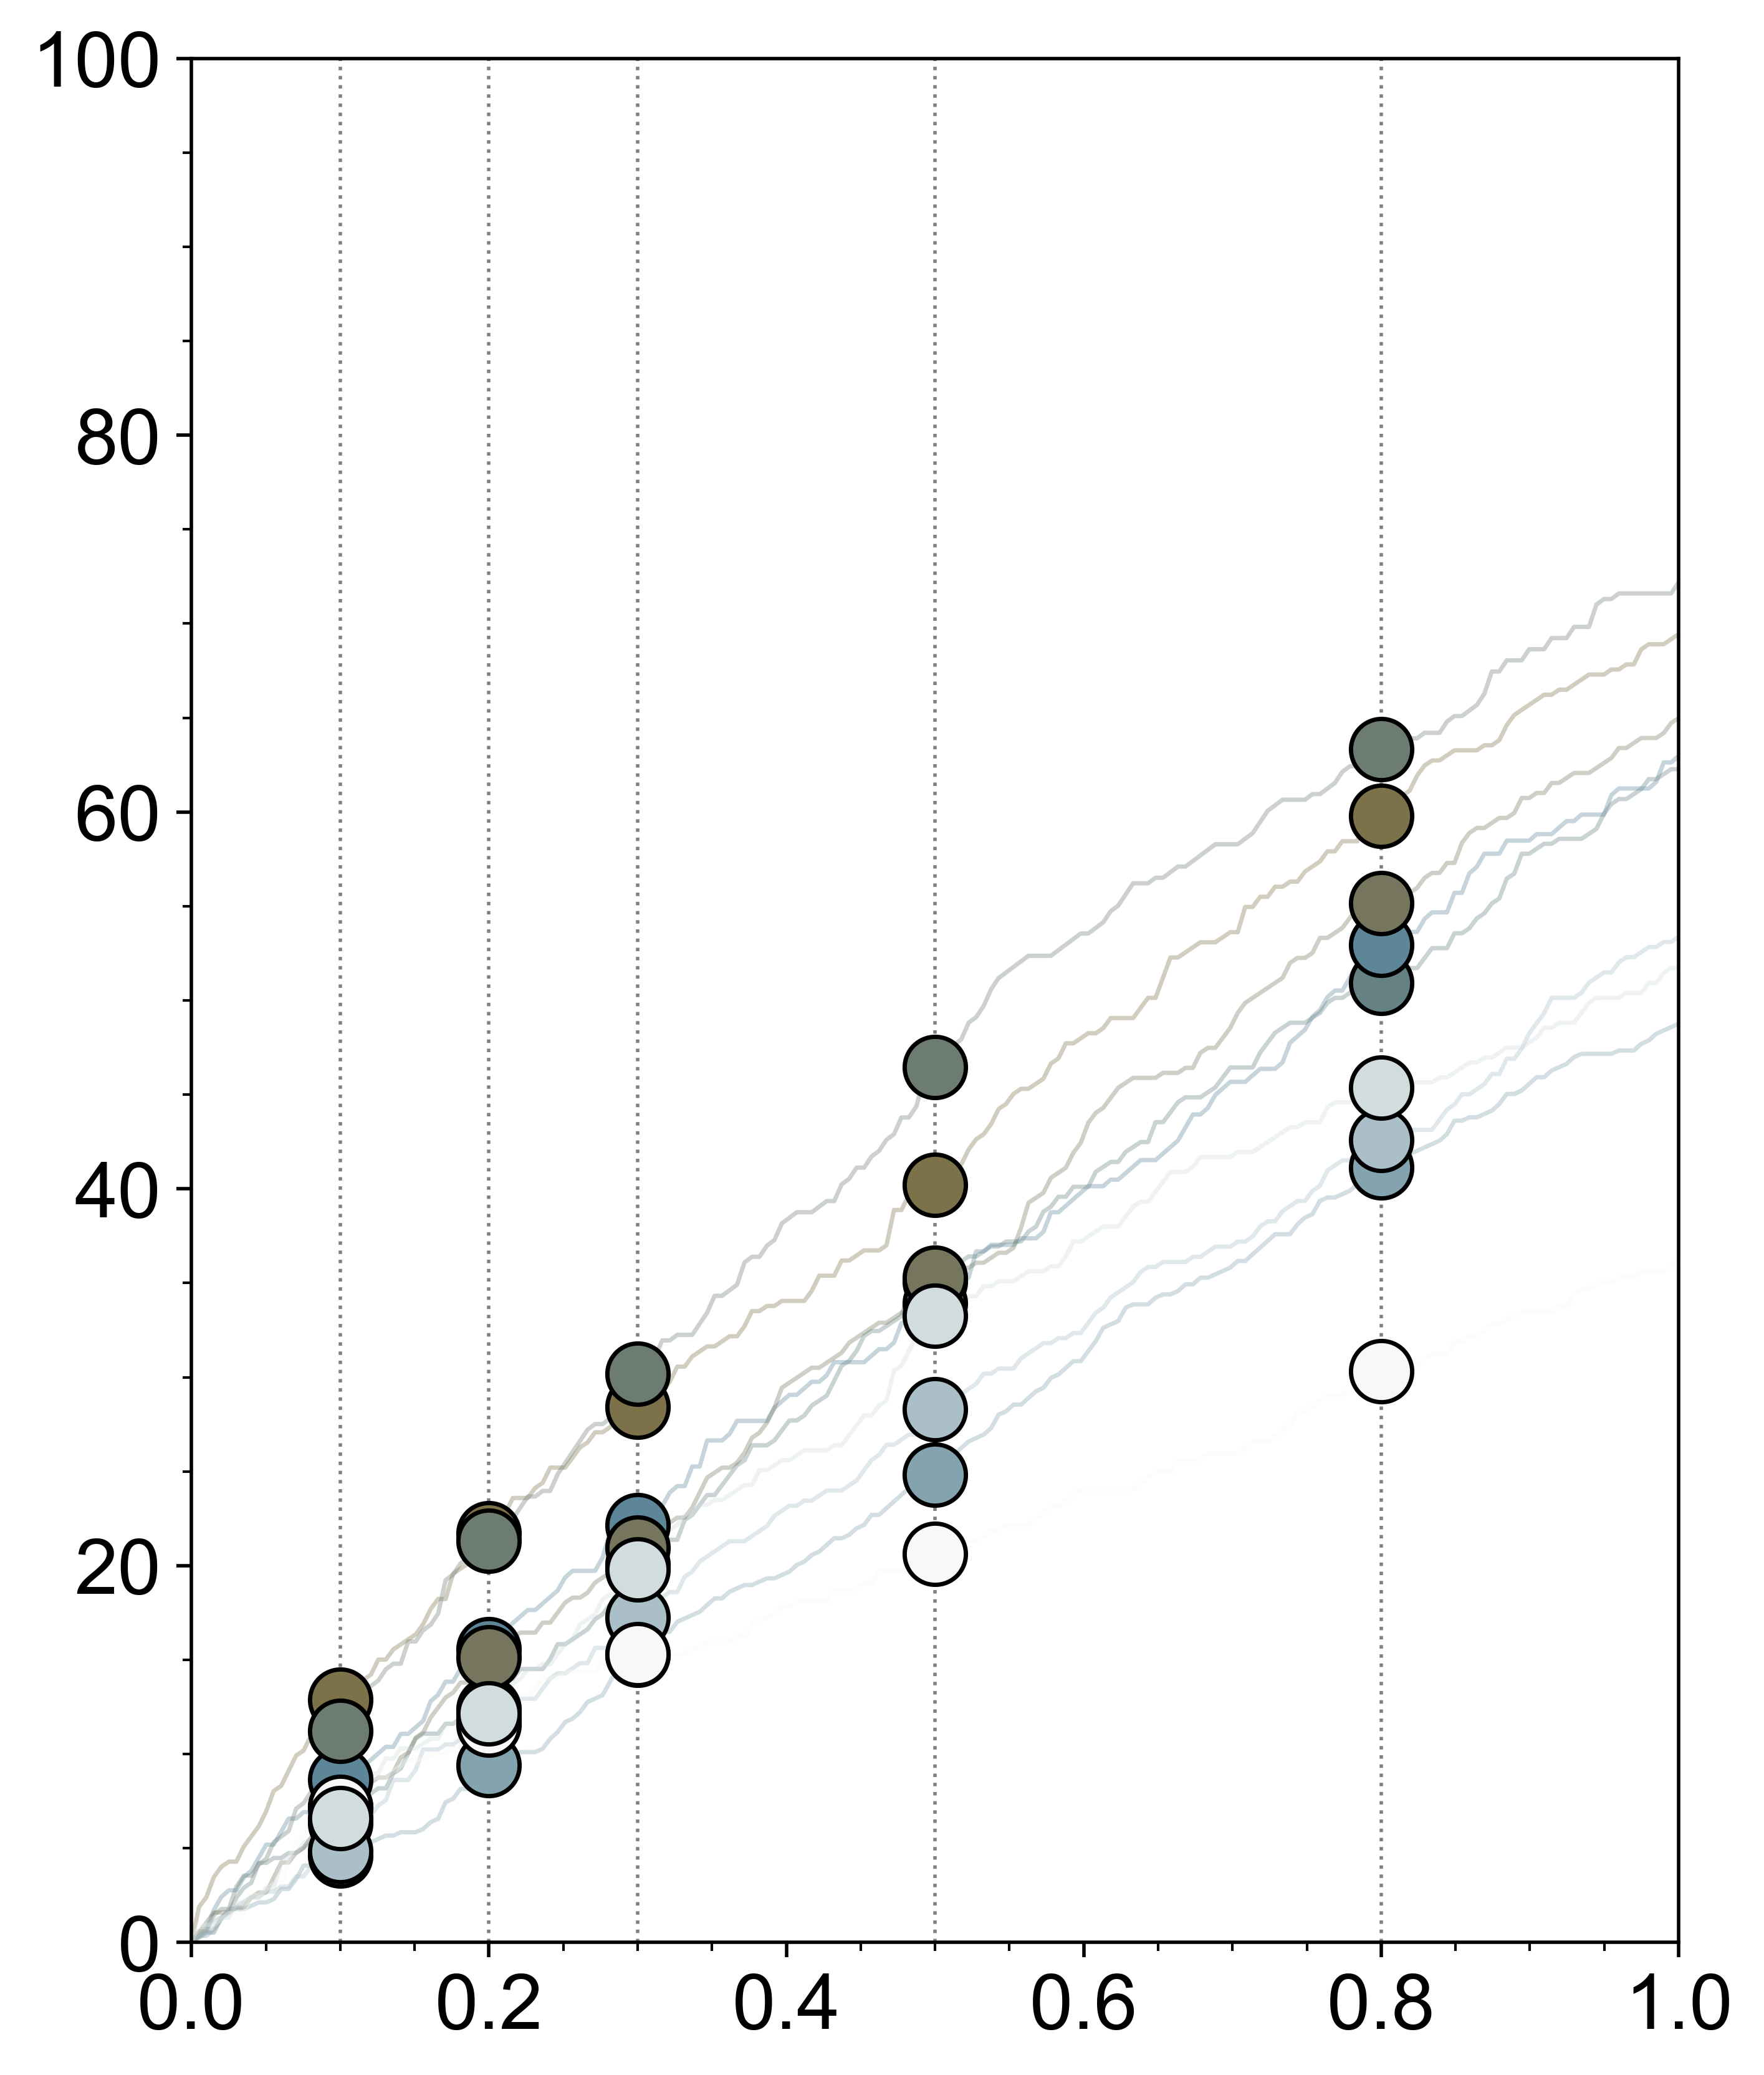

In [9]:
"""
Plot cumulative accuracy (fig 1) and target-vs-computed calibration (fig 2)
for selected ads_<num> csv files, each as its own standalone figure.

Expected file layout: ./data/ads_<num>/energies.csv
Expected columns:     ads_<num>_adsorption_E (GACE), ads_<num>_target_E (dataset)

Setup:
  - DATA_DIR: root folder containing per-adsorbate subfolders.
  - num_to_name: reverse-lookup of ads_dict (id -> adsorbate name) for legend labels.
  - FILTER_RANGE = (-10, 10): energy bounds (eV) used to discard outlier rows
    (expected to have been applied wherever `abs_errors` was built).
  - ERROR_THRESHOLDS: |GACE - target| cutoffs (eV) at which cumulative
    accuracy is reported/marked.
  - XLIM = (0, 1.0): x-axis range (eV) for the cumulative accuracy curve.
  - GRADIENT_COLORS / GRADIENT: three-color gradient used to color each
    adsorbate's curve by how well GACE performs on it (worst -> best).

`color_for_rank(pos)`:
  Maps a normalized rank pos in [0, 1] (0 = worst, 1 = best) to an
  interpolated color from GRADIENT.

Ranking:
  Uses a pre-existing `abs_errors` dict (adsorbate id -> absolute error
  series) to compute each adsorbate's mean absolute error, ranks
  adsorbates worst-to-best (highest to lowest mean error), and assigns
  each a normalized rank_pos used to pick its curve/marker color.

Figure 1 — cumulative accuracy:
  For each adsorbate: plots the percent of structures with absolute error
  <= t for a fine grid of thresholds (faint line), overlays discrete
  markers at ERROR_THRESHOLDS, and prints that adsorbate's accuracy at
  each threshold immediately within the same loop iteration. After the
  loop, prints the average accuracy at each threshold across adsorbates
  (equal weight per adsorbate, not per structure, since each adsorbate
  contributes one entry to pct_at_thresholds_all regardless of its
  structure count). Draws vertical dotted guide lines at each
  ERROR_THRESHOLDS value, sets axis limits, and saves the figure as
  "fig3/panel/cumulative_accuracy.svg" via `save_flat_svg`.
"""

from matplotlib.colors import LinearSegmentedColormap

num_to_name = {v: k for k, v in ads_dict.items()}  # for legend labels

# Discard any row where either column falls outside this range.
FILTER_RANGE = (-10, 10)

ERROR_THRESHOLDS = [0.10, 0.20, 0.30, 0.50, 0.80]
XLIM = (0, 1.0)

# Three colors from the Snom palette: light cream -> blue-grey -> dark khaki
GRADIENT_COLORS = ["#F8F8F6", "#5D8798", "#7D714A"]
GRADIENT = LinearSegmentedColormap.from_list("snom", GRADIENT_COLORS)


def color_for_rank(pos):
    """pos in [0, 1] (0=worst, 1=best) -> interpolated color from GRADIENT."""
    return GRADIENT(pos)


# rank: 0 = worst (highest mean error) -> 1 = best (lowest mean error)
mean_errors = {num: abs_errors[num].mean() for num in SELECTED_NUMS}
order = sorted(SELECTED_NUMS, key=lambda n: -mean_errors[n])  # worst first
rank_pos = {num: i / (len(order) - 1) for i, num in enumerate(order)}

# -------------------------------------------------------------
# Figure 1: cumulative accuracy
# -------------------------------------------------------------
fig_e, ax = plt.subplots(figsize=(6, 7), dpi=500)

thresholds_fine = np.linspace(*XLIM, 200)

pct_at_thresholds_all = []  # collect per-dataset values at ERROR_THRESHOLDS to average

for num in SELECTED_NUMS:
    abs_error = abs_errors[num]
    color = color_for_rank(rank_pos[num])

    pct_within = [(abs_error <= t).mean() * 100 for t in thresholds_fine]
    ax.plot(thresholds_fine, pct_within, linewidth=1, alpha=0.35, color=color)

    # discrete markers at the four thresholds of interest
    pct_at_thresholds = [(abs_error <= t).mean() * 100 for t in ERROR_THRESHOLDS]
    pct_at_thresholds_all.append(pct_at_thresholds)
    ax.scatter(ERROR_THRESHOLDS, pct_at_thresholds, s=200, color=color,
               edgecolor="black", linewidth=1, zorder=3, label=num_to_name.get(num, str(num)))

    key = next(k for k, v in ads_dict.items() if v == num)
    print(f"== {key} ==")
    for t, p in zip(ERROR_THRESHOLDS, pct_at_thresholds):
        print(f"  {t:.2f} eV: {p:.2f}%")
    print()


avg_pct_at_thresholds = np.mean(pct_at_thresholds_all, axis=0)  # equal weight per adsorbate
std_pct_at_thresholds = np.std(pct_at_thresholds_all, axis=0)  # equal weight per adsorbate
print("== average across adsorbates ==")
for t, pct, std in zip(ERROR_THRESHOLDS, avg_pct_at_thresholds, std_pct_at_thresholds):
    print(f"  {t:.2f} eV: {pct:.2f}% ± {std:.2f}")

for t in ERROR_THRESHOLDS:
    ax.axvline(t, color="gray", linestyle=":", linewidth=0.8)

ax.minorticks_on()
ax.set_xlim(*XLIM)
ax.set_ylim(0, 100)
plt.tight_layout()
save_flat_svg(fig=fig_e, path=f"fig3/panel/cumulative_accuracy.svg")

O: slope=0.619±0.039, r2=0.308, p=6.79e-47, n=564
CH2O: slope=0.589±0.049, r2=0.282, p=1.58e-28, n=373
COCH2OH: slope=0.640±0.046, r2=0.337, p=1.45e-35, n=379
C2H(OH)2: slope=0.619±0.056, r2=0.301, p=4.27e-24, n=289
C2H4OH: slope=0.570±0.086, r2=0.115, p=1.63e-10, n=338
NH2: slope=0.409±0.051, r2=0.147, p=1.32e-14, n=377
NO2: slope=0.865±0.045, r2=0.502, p=8.80e-58, n=371
NO3: slope=0.821±0.050, r2=0.458, p=3.73e-44, n=320
HNO2: slope=0.806±0.040, r2=0.514, p=5.20e-61, n=379

POOLED: slope=0.814±0.011, intercept=-0.133, r2=0.601, p=0.00e+00, n=3390
             slope  intercept         r        r2             p    stderr  \
O         0.618813   0.057345  0.555073  0.308106  6.790251e-47  0.039117   
CH2O      0.588985  -0.559573  0.531043  0.282007  1.582186e-28  0.048792   
COCH2OH   0.639675  -0.697750  0.580802  0.337331  1.451087e-35  0.046175   
C2H(OH)2  0.618554  -0.604312  0.548450  0.300797  4.271725e-24  0.055667   
C2H4OH    0.569743  -1.248011  0.338624  0.114666  1.634111e

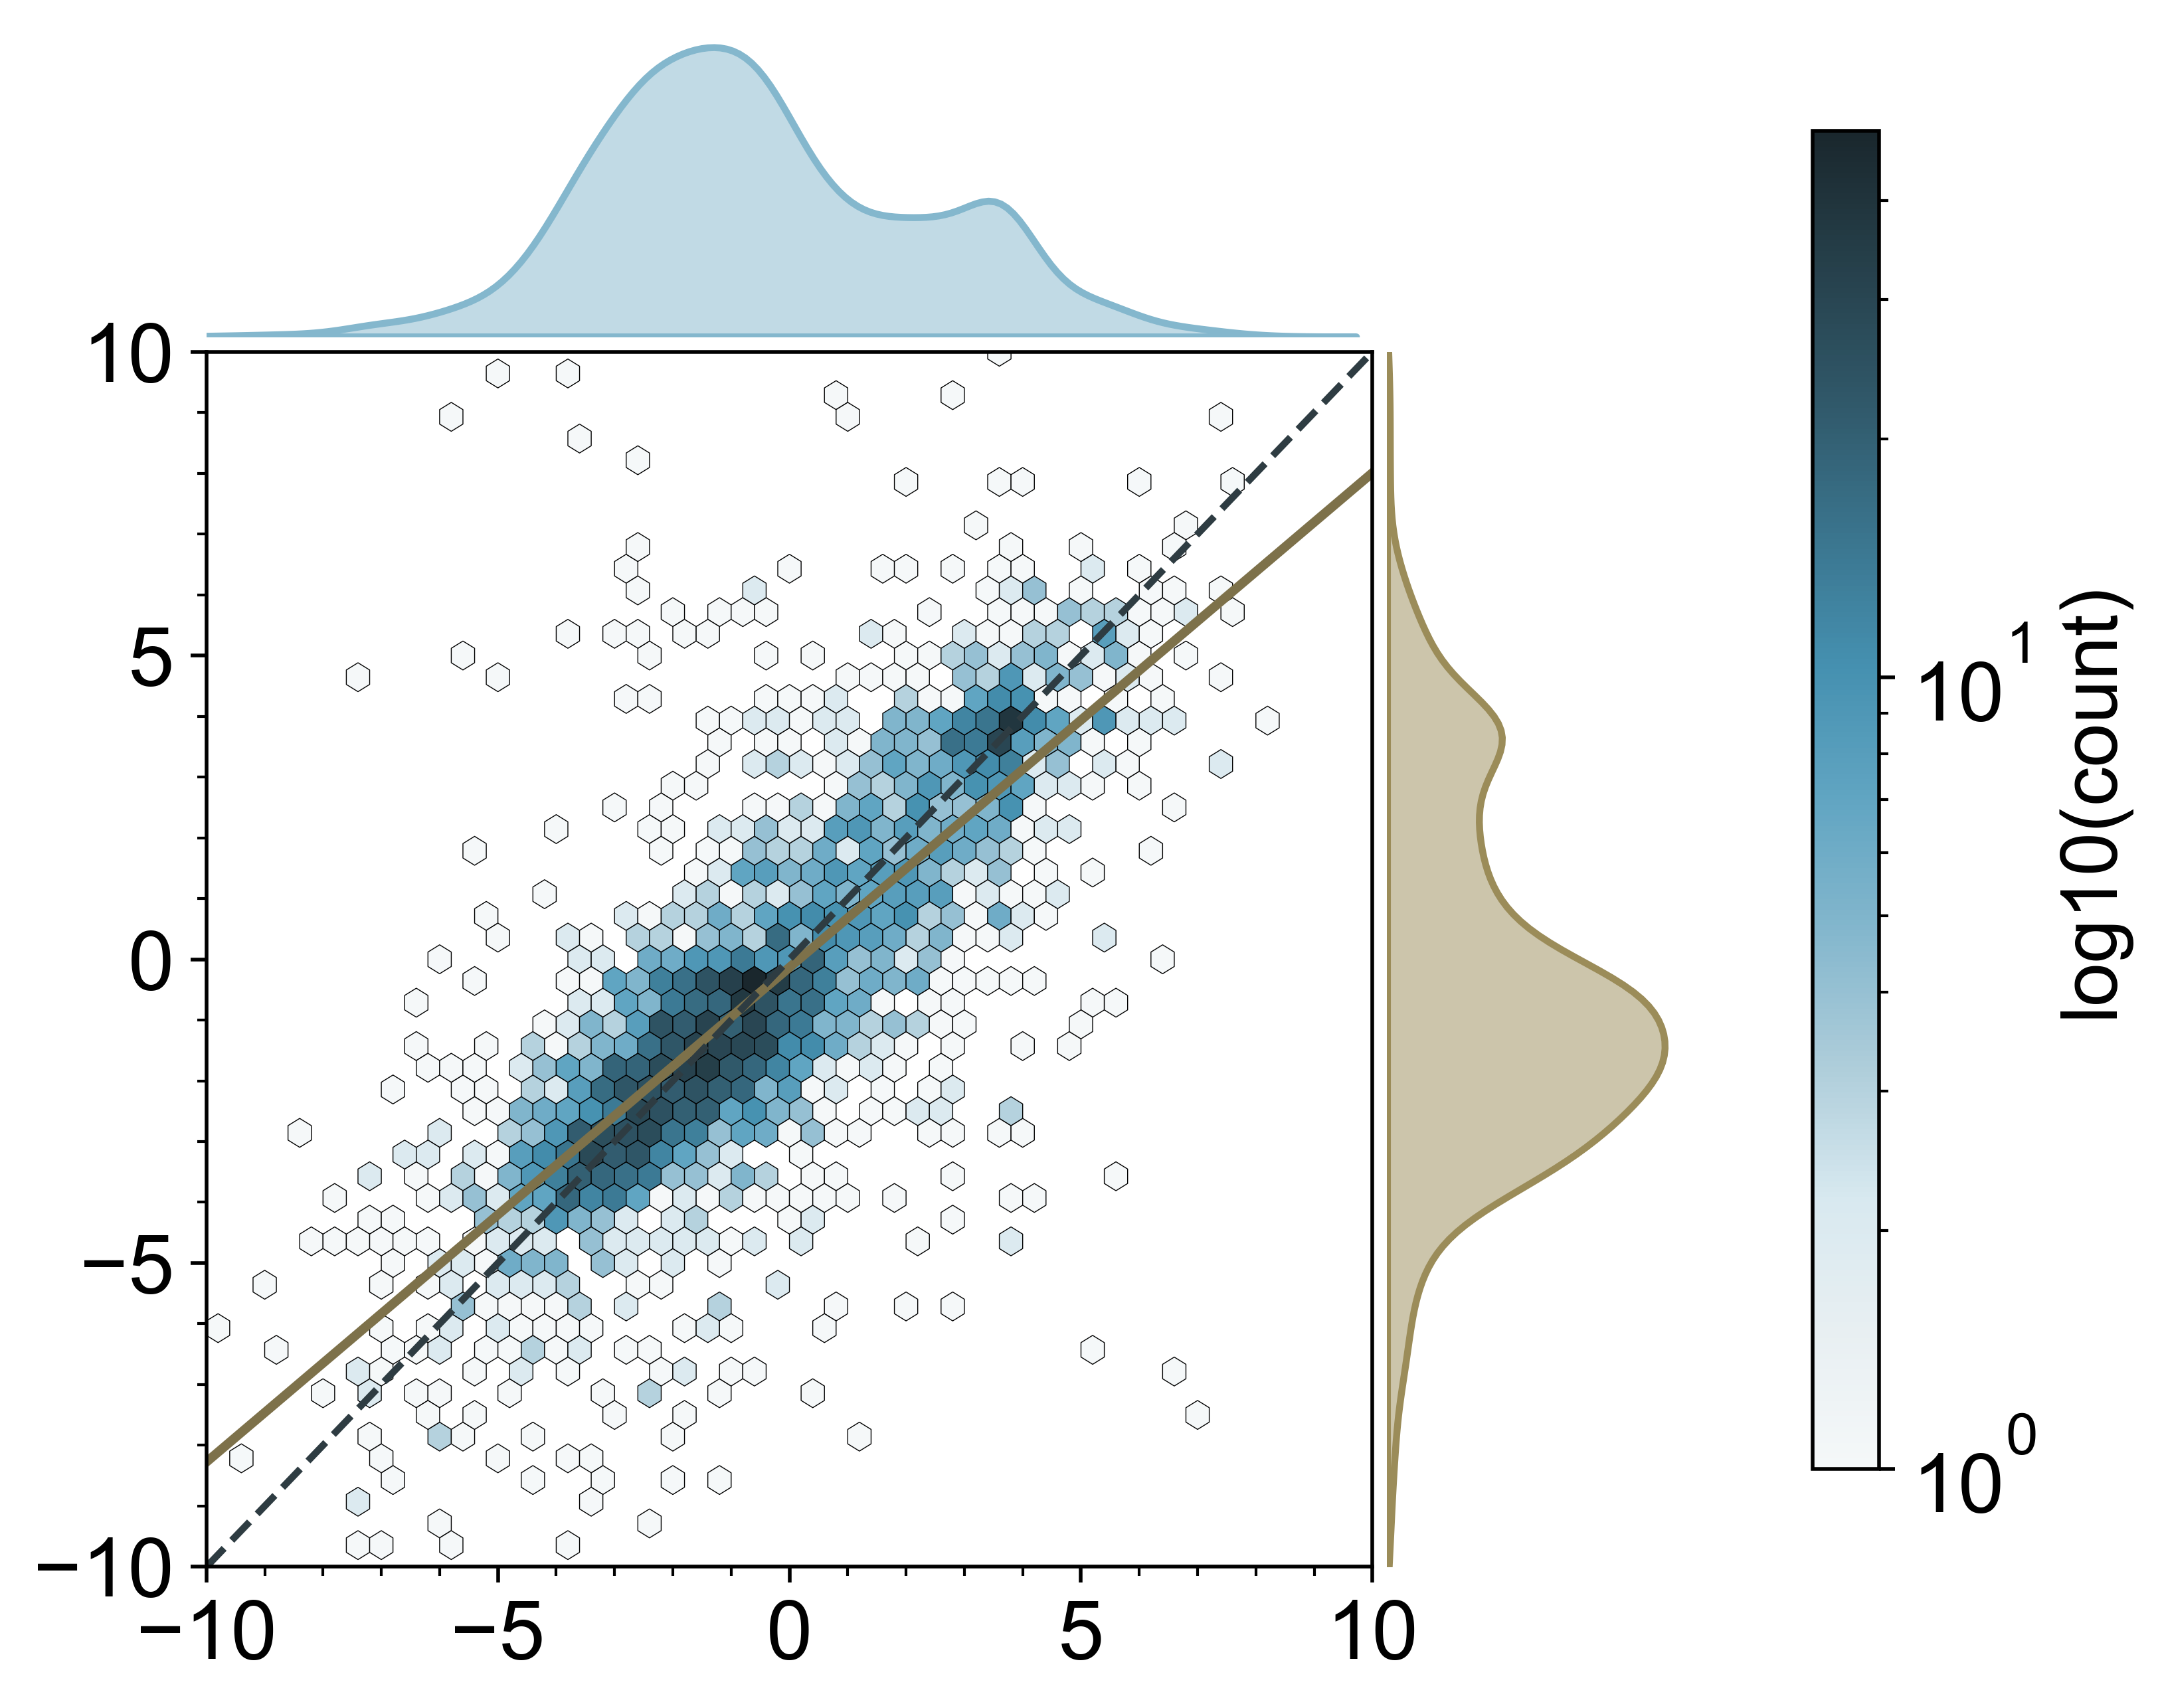

In [10]:
"""
Same pooled hexbin with marginal distributions (KDE) added on top (target
energy) and right (predicted energy) axes via manual gridspec, since hexbin
isn't natively supported by seaborn's JointGrid.
"""

from scipy.stats import linregress
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.gridspec as gridspec

DATA_DIR = "./data/oc20_and_gace/energy_data"
ads_dict = {"O": 0, "CH2O": 10, "COCH2OH": 41, "C2H(OH)2": 42, "C2H4OH": 54, "NH2": 71, "NO2": 75, "NO3": 78, "HNO2": 80}
SELECTED_NUMS = list(ads_dict.values())
FILTER_RANGE = (-10, 10)
XLIM = (-10, 10)

color3_ramp = ["#F5F8F9", "#E8EFF2", "#D8E9F0", "#AECDDA", "#84B7CD",
               "#61A5C2", "#4590B0", "#3A748D", "#305869", "#26404B", "#1A272D"]
cmap = LinearSegmentedColormap.from_list("color3_seq", color3_ramp)

fit_color = "#7D714A"      # Snom 700
yx_color = "#2E3C42"       # Color 2 900
target_marg_color = "#84B7CD"   # Color 3 400 (x-axis marginal)
pred_marg_color = "#9B8C59"     # Snom 600 (y-axis marginal)

all_targets = []
all_preds = []
regression_results = {}

for num in SELECTED_NUMS:
    path = f"{DATA_DIR}/ads_{num}/energies.csv"
    df = pd.read_csv(path)

    gace_col = f"ads_{num}_adsorption_E"
    target_col = f"ads_{num}_target_E"

    mask = df[gace_col].between(*FILTER_RANGE) & df[target_col].between(*FILTER_RANGE)
    df = df[mask]

    key = next(k for k, v in ads_dict.items() if v == num)

    slope, intercept, r, p, stderr = linregress(df[target_col], df[gace_col])
    regression_results[key] = dict(slope=slope, intercept=intercept, r=r, r2=r**2, p=p, stderr=stderr, n=len(df))
    print(f"{key}: slope={slope:.3f}±{stderr:.3f}, r2={r**2:.3f}, p={p:.2e}, n={len(df)}")

    all_targets.append(df[target_col].values)
    all_preds.append(df[gace_col].values)

all_targets = np.concatenate(all_targets)
all_preds = np.concatenate(all_preds)

slope, intercept, r, p, stderr = linregress(all_targets, all_preds)
print(f"\nPOOLED: slope={slope:.3f}±{stderr:.3f}, intercept={intercept:.3f}, r2={r**2:.3f}, p={p:.2e}, n={len(all_targets)}")

fig = plt.figure(figsize=(6.5, 6), dpi=500)
gs = gridspec.GridSpec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4],
                        wspace=0.02, hspace=0.02)

ax_main = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0], sharex=ax_main)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax_main)

hb = ax_main.hexbin(all_targets, all_preds, gridsize=50, cmap=cmap, mincnt=1,
                     extent=[*XLIM, *XLIM], bins="log",
                     edgecolors="black", linewidths=0.2)

x_line = np.linspace(*XLIM, 100)
ax_main.plot(x_line, slope * x_line + intercept, color=fit_color, linewidth=2,
             label=f"fit (slope={slope:.2f}, r²={r**2:.2f})")
ax_main.plot(x_line, x_line, color=yx_color, linestyle="--", linewidth=1.5,
             label="y = x (perfect adherence)")

ax_main.minorticks_on()
ax_main.set_xlim(*XLIM)
ax_main.set_ylim(*XLIM)

# top marginal: target energy distribution
sns.kdeplot(x=all_targets, ax=ax_top, fill=True, color=target_marg_color,
            alpha=0.5, linewidth=1.5)
ax_top.set_xlim(*XLIM)
ax_top.axis("off")

# right marginal: predicted energy distribution
sns.kdeplot(y=all_preds, ax=ax_right, fill=True, color=pred_marg_color,
            alpha=0.5, linewidth=1.5)
ax_right.set_ylim(*XLIM)
ax_right.axis("off")

# colorbar off to the side of the marginal, not overlapping main plot
cb = fig.colorbar(hb, ax=[ax_main, ax_top, ax_right], location="right",
                   fraction=0.04, pad=0.08)
cb.set_label("log10(count)")

#save_flat_svg(fig=fig, path="fig2/panel/all_adsorbates_hexbin.svg")

summary_df = pd.DataFrame(regression_results).T
print(summary_df)

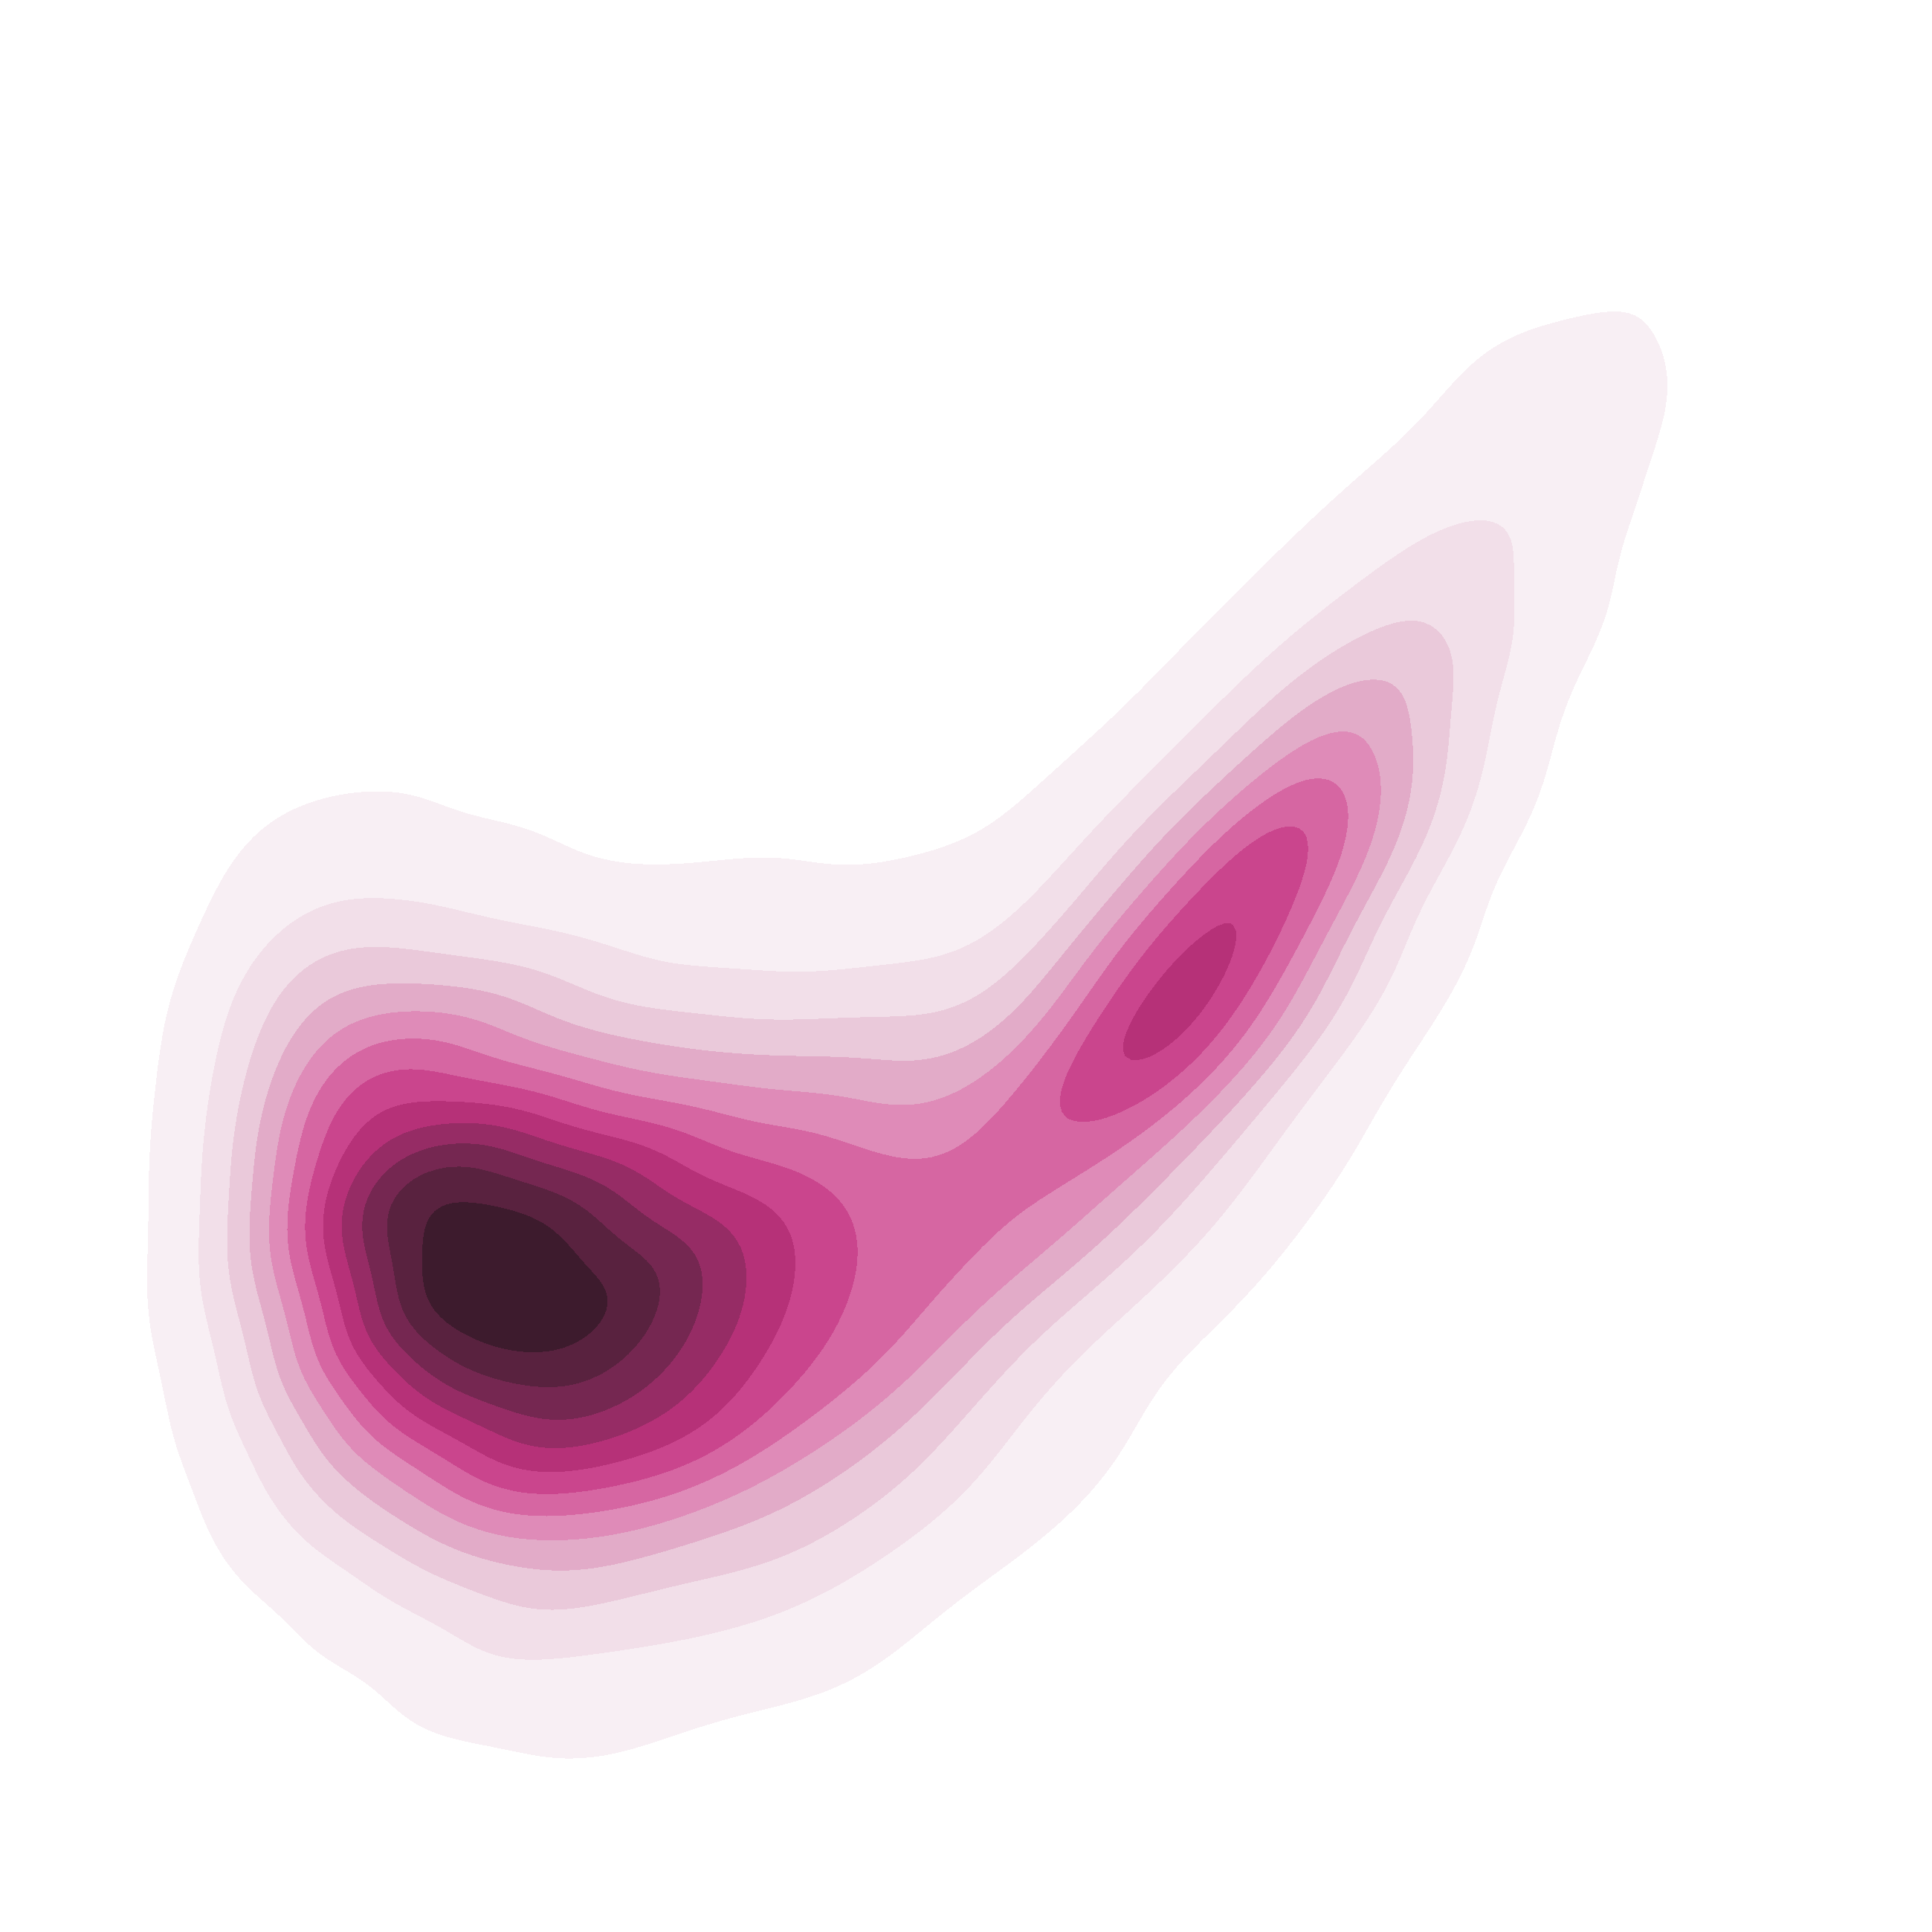

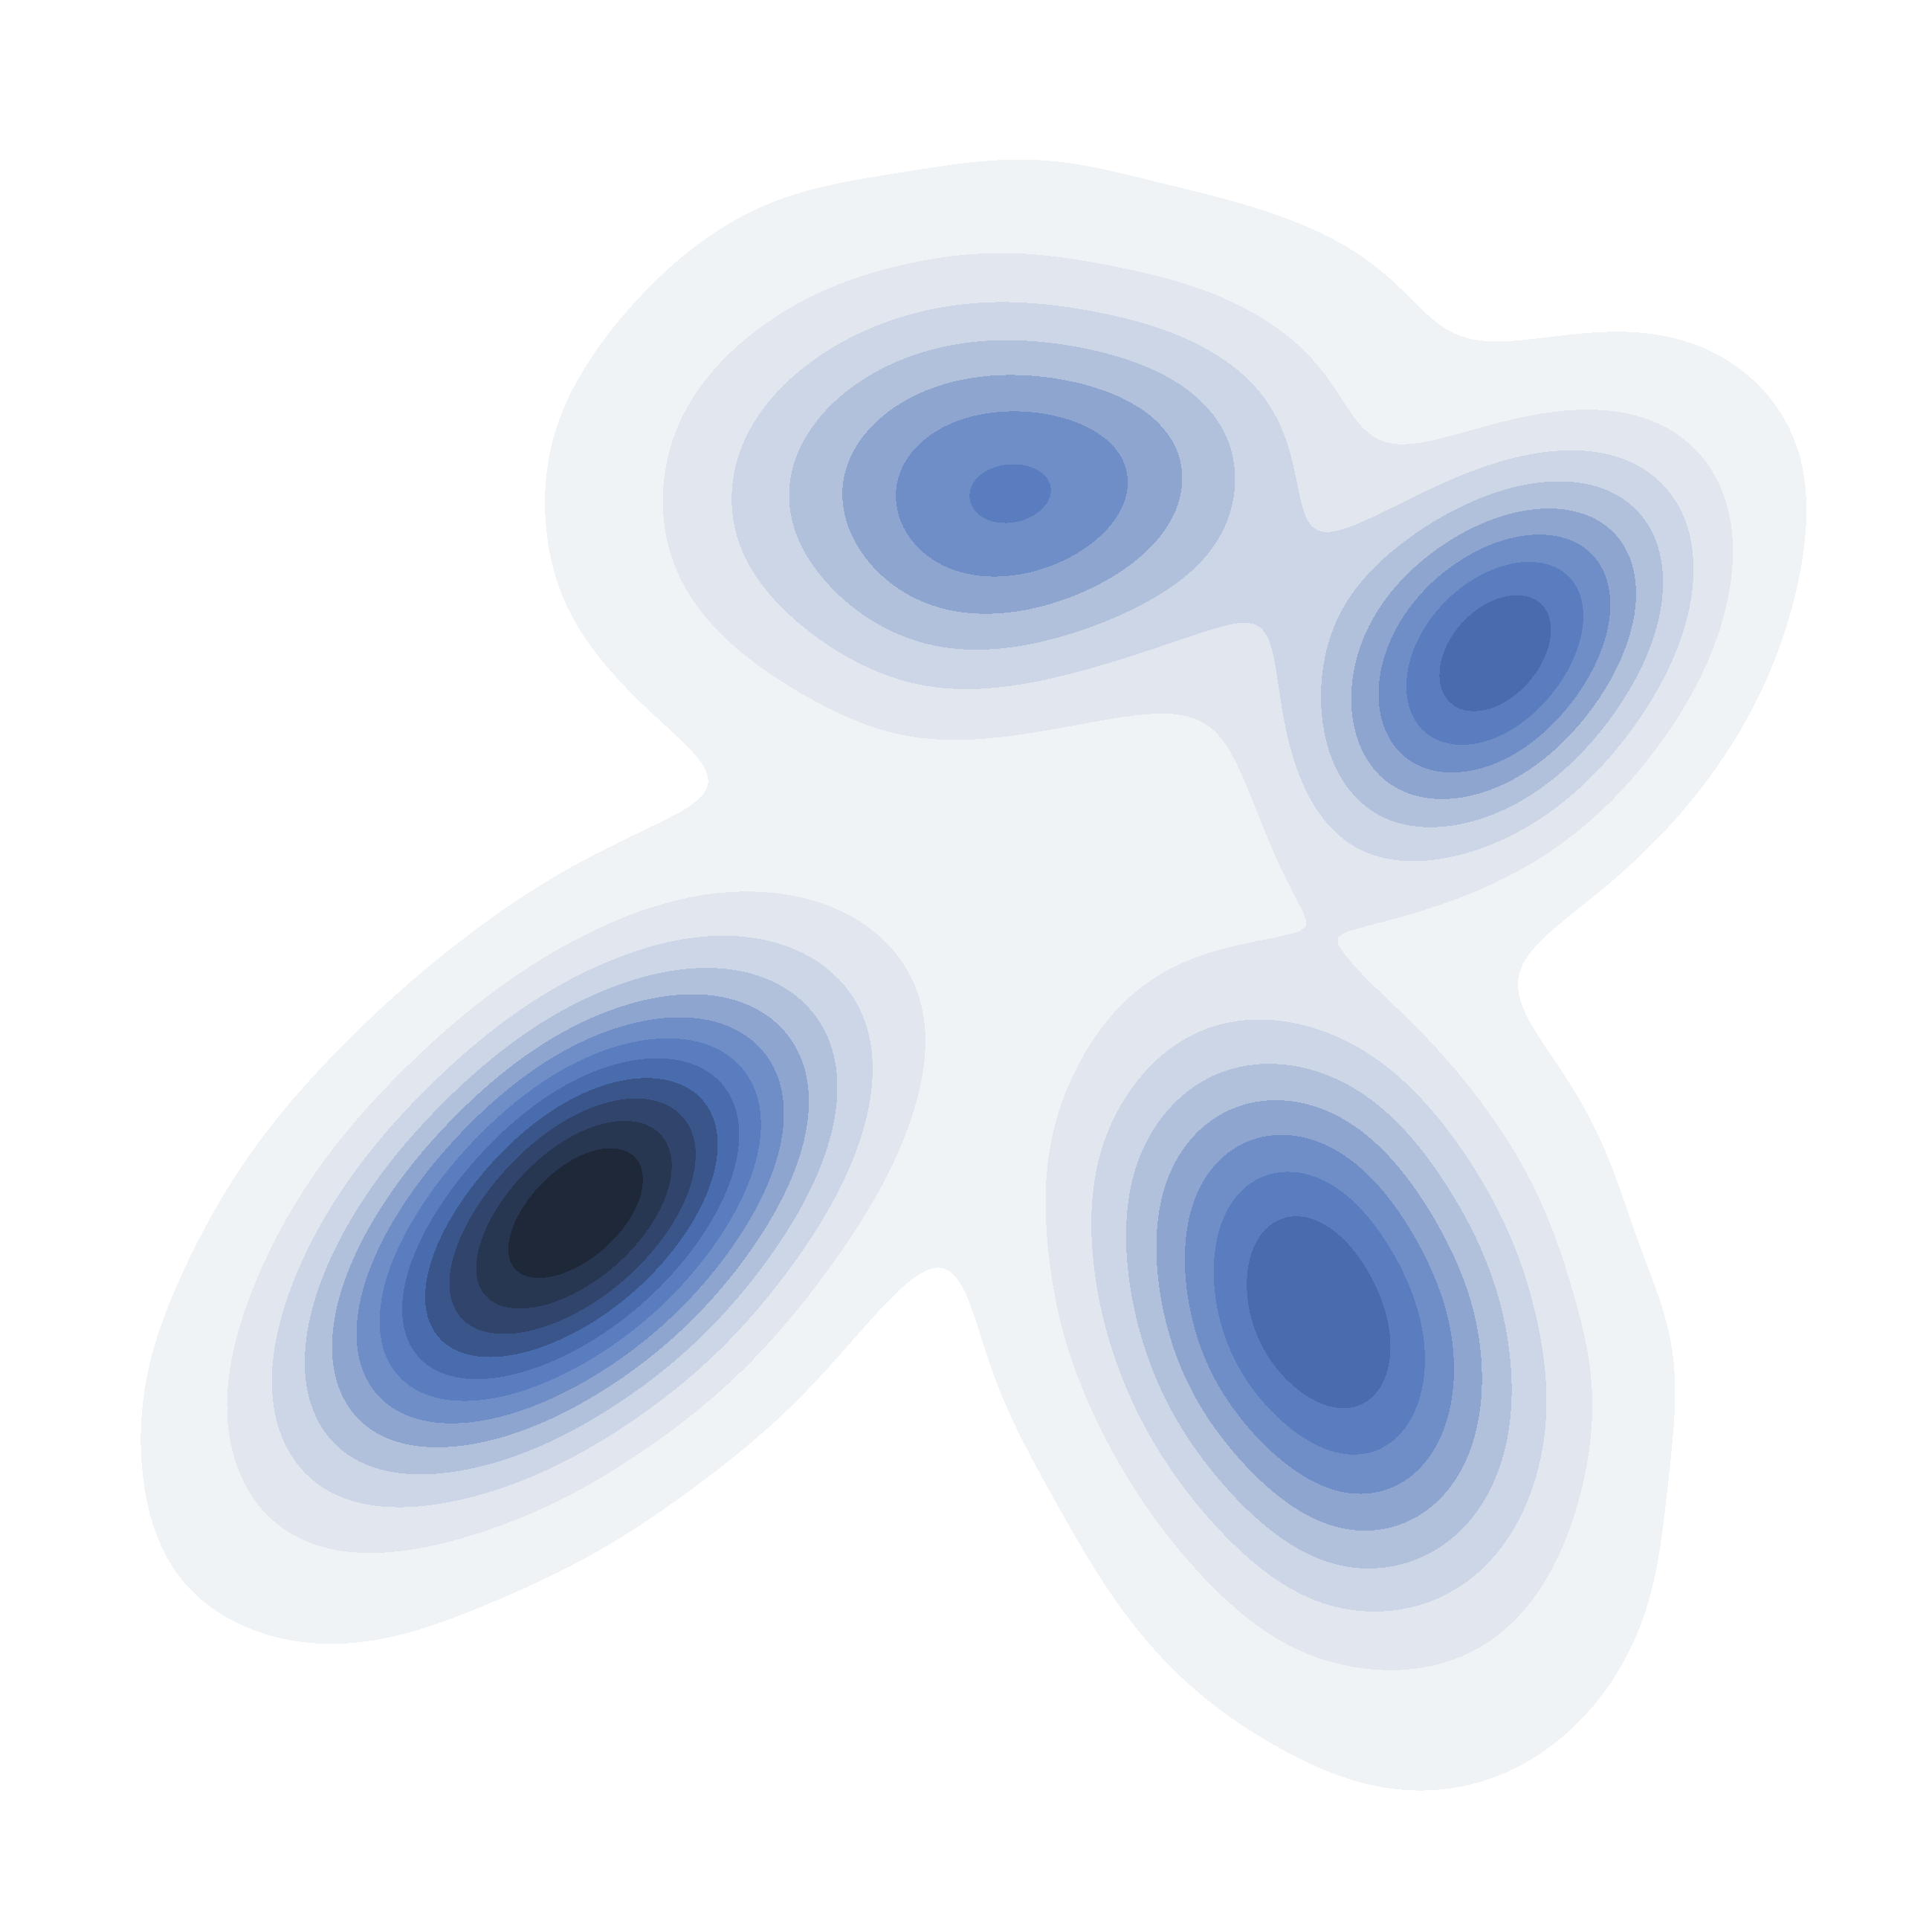

In [11]:
"""Clean 2D density plots (no axes, grid, or colorbar) using a Tailwind-style shade ramp."""

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde

PALETTES = {
    "gligar": ["#FAF5F8", "#F4E6EE", "#EBCCDC", "#E1A7C6", "#DE83B4", "#D15296",
               "#C1337F", "#9A2D67", "#72274F", "#51203A", "#301725"],
    "mauve":  ["#F9F6F8", "#F1EAEE", "#E4D3DE", "#D4B5CA", "#C28FB2", "#AC6294",
               "#A05488", "#81466E", "#613854", "#452B3D", "#2A1D26"],
    "blue":   ["#F5F7F9", "#E8ECF2", "#D0D8E7", "#AEBEDA", "#849DCD", "#6183C2",
               "#4D74BA", "#3A578D", "#304469", "#26334B", "#1A212D"],
}


def ramp(name):
    return LinearSegmentedColormap.from_list(name, PALETTES[name])


def density_plot(x, y, palette="gligar", levels=12, pad=0.15, grid=300,
                 floor=0.03, figsize=(5, 5), path=None):
    """KDE of (x, y) rendered as filled contours with no chrome.

    floor: lowest contour as a fraction of peak density. Anything below it is
    left unpainted, so the background stays white.
    """
    q = [0.005, 0.995]  # quantile window keeps heavy tails from dominating the frame
    x0, x1 = np.quantile(x, q)
    y0, y1 = np.quantile(y, q)
    xg = np.linspace(x0 - pad * (x1 - x0), x1 + pad * (x1 - x0), grid)
    yg = np.linspace(y0 - pad * (y1 - y0), y1 + pad * (y1 - y0), grid)
    XX, YY = np.meshgrid(xg, yg)

    kde = gaussian_kde(np.vstack([x, y]))
    Z = kde(np.vstack([XX.ravel(), YY.ravel()])).reshape(XX.shape)

    cmap = ramp(palette)
    fig, ax = plt.subplots(figsize=figsize, dpi=500)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")
    lv = np.linspace(floor * Z.max(), Z.max(), levels + 1)
    ax.contourf(XX, YY, Z, levels=lv, cmap=cmap, extend="neither")
    ax.axis("off")
    fig.tight_layout(pad=0)

    if path:
        fig.savefig(path, dpi=200, facecolor=fig.get_facecolor())
    return fig, ax


def sample_unimodal(n=20000, seed=0, shoulder=0.18):
    """Dominant curved, skewed mode plus a small shoulder along the ridge.

    shoulder: fraction of mass in the secondary bump. 0.0 gives a single mode,
    ~0.3 starts to read as genuinely bimodal.
    """
    rng = np.random.default_rng(seed)
    n_main = int(n * (1 - shoulder))
    n_sec = n - n_main

    u = rng.gamma(2.5, 0.6, n_main)
    v = rng.normal(0, 0.55, n_main)
    x_main = u - 1.5
    y_main = 0.30 * x_main**2 + v - 0.6

    # sits on the upper arm of the ridge, wide enough to stay attached
    x_sec = rng.normal(1.9, 0.45, n_sec)
    y_sec = 0.30 * x_sec**2 + rng.normal(0, 0.40, n_sec) - 0.4

    return np.concatenate([x_main, x_sec]), np.concatenate([y_main, y_sec])


def sample_multimodal(n=20000, seed=1):
    """Four components with different weights, spreads, and orientations."""
    rng = np.random.default_rng(seed)
    means = [(-1.8, -1.2), (1.6, -1.6), (0.2, 1.9), (2.4, 1.2)]
    covs = [[[0.45, 0.25], [0.25, 0.35]],
            [[0.30, -0.18], [-0.18, 0.55]],
            [[0.70, 0.0], [0.0, 0.25]],
            [[0.20, 0.10], [0.10, 0.20]]]
    weights = [0.35, 0.28, 0.22, 0.15]
    counts = rng.multinomial(n, weights)
    pts = [rng.multivariate_normal(m, c, k) for m, c, k in zip(means, covs, counts)]
    pts = np.vstack(pts)
    return pts[:, 0], pts[:, 1]


if __name__ == "__main__":
    density_plot(*sample_unimodal(), palette="gligar", path="unimodal.svg")
    density_plot(*sample_multimodal(), palette="blue", path="multimodal.svg")

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV_PATH = "slab_hist.csv"

df = pd.read_csv(CSV_PATH)
edges = np.append(df["bin_left"].values, df["bin_right"].values[-1])
counts = df["count"].values.astype(float)
centers = 0.5 * (edges[:-1] + edges[1:])
mean = np.average(centers, weights=counts)

fig, ax = plt.subplots(figsize=(6, 2.6), dpi=500)
ax.hist(centers, bins=edges, weights=counts, color="#A8AFCD",
        alpha=0.6, edgecolor="black", linewidth=0.6)
ax.axvline(mean, color="black", ls="--", lw=1.2)

ax.set_xlim(edges[0] - 15, edges[-1] + 35)
ax.set_ylim(0, counts.max() * 1.05)
for side in ("left", "right", "top"):
    ax.spines[side].set_visible(False)
ax.yaxis.set_visible(False)

ax.set_xlim(0, 200)
ax.set_xticks(np.arange(0, 201, 50))
fig.tight_layout()
save_flat_svg(fig=fig, path=f"hist.svg")

KeyError: 'bin_left'

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

CSV_PATH = "slab_hist.csv"
BIN_WIDTH = 8
XMAX = 200
STYLE = {"Primitive Cell": "#3A748D", "Slab": "#A8AFCD"}

df = pd.read_csv(CSV_PATH)
edges = np.arange(0, XMAX + BIN_WIDTH, BIN_WIDTH)

fig, ax = plt.subplots(figsize=(6, 2.6), dpi=500)
for name, color in STYLE.items():
    g = df[df["series"] == name]
    if g.empty:
        continue
    ax.hist(g["n_atoms"], bins=edges, weights=g["count"], color=color,
            alpha=0.6, edgecolor="black", linewidth=0.6, label=name)
    mean = np.average(g["n_atoms"], weights=g["count"])
    ax.axvline(mean, color=color, ls="--", lw=1.2)

ax.set_xlim(0, XMAX)
ax.set_xticks(np.arange(0, XMAX + 1, 50))
ax.set_ylim(0, None)
for side in ("left", "right", "top"):
    ax.spines[side].set_visible(False)
ax.yaxis.set_visible(False)
fig.tight_layout()
save_flat_svg(fig=fig, path="fig3/panel/natoms.svg")